# Tahap 1 — Pemeriksaan Citra Batuan Kirby



In [ ]:
from google.colab import files
uploaded = files.upload()
print('\nFile yang berhasil diunggah:')
for name, content in uploaded.items():
    print(f'- {name}: {len(content):,} byte')

Saving Kirby_2d25um_binary_256.raw to Kirby_2d25um_binary_256.raw
Saving metadata-citra.json to metadata-citra.json
Saving sebelas-batupasir.csv to sebelas-batupasir.csv

File yang berhasil diunggah:
- Kirby_2d25um_binary_256.raw: 16,777,216 byte
- metadata-citra.json: 2,487 byte
- sebelas-batupasir.csv: 3,465 byte


In [ ]:
import json, csv, os
import numpy as np
import pandas as pd

required = ['Kirby_2d25um_binary_256.raw', 'metadata-citra.json', 'sebelas-batupasir.csv']
missing = [f for f in required if not os.path.exists(f)]
if missing:
    raise FileNotFoundError('File berikut belum diunggah: ' + ', '.join(missing))

with open('metadata-citra.json', encoding='utf-8') as f:
    metadata = json.load(f)

df = pd.read_csv('sebelas-batupasir.csv')
kirby_csv = df[df['batuan'].str.lower() == 'kirby'].copy()
if kirby_csv.empty:
    raise ValueError('Baris Kirby tidak ditemukan di CSV.')

kirby_meta = next(x for x in metadata['berkas'] if x['batuan'].lower() == 'kirby')
n = int(metadata['ukuran_voxel_tiap_sumbu'])
voxel_m = float(metadata['ukuran_voxel_m'])
expected_values = n**3
raw_path = 'Kirby_2d25um_binary_256.raw'
raw_bytes = os.path.getsize(raw_path)
volume_1d = np.fromfile(raw_path, dtype=np.dtype(metadata['tipe_data']))

print('--- Pemeriksaan awal ---')
print(f'Ukuran domain yang diharapkan : {n} x {n} x {n}')
print(f'Jumlah voxel yang diharapkan  : {expected_values:,}')
print(f'Ukuran file                   : {raw_bytes:,} byte')
print(f'Jumlah nilai yang terbaca     : {volume_1d.size:,}')
print(f'Tipe data                     : {metadata["tipe_data"]}')
print(f'Urutan indeks                 : {metadata["urutan_indeks"]}')

if volume_1d.size != expected_values:
    raise ValueError('GAGAL: jumlah voxel tidak sesuai ukuran domain.')

nilai_unik, jumlah = np.unique(volume_1d, return_counts=True)
print('\nNilai voxel dan jumlahnya:')
for v, count in zip(nilai_unik, jumlah):
    print(f'  nilai {int(v)}: {count:,} voxel')
if not set(nilai_unik.tolist()).issubset({0, 1}):
    raise ValueError('GAGAL: ditemukan nilai selain 0 dan 1 pada citra biner.')

volume = volume_1d.reshape((n, n, n), order=metadata['urutan_indeks'])
pore = (volume == 0)
phi_hitung = float(pore.mean())
phi_meta = float(kirby_meta['porositas_acuan'])
phi_csv = float(kirby_csv.iloc[0]['phi'])
phi_connected_csv = float(kirby_csv.iloc[0]['phi_terhubung'])
selisih = abs(phi_hitung - phi_csv)
toleransi = 5e-4

print('\n--- Pemeriksaan porositas ---')
print(f'Porositas hasil pembacaan : {phi_hitung:.8f} ({phi_hitung*100:.5f}%)')
print(f'Porositas acuan metadata  : {phi_meta:.8f} ({phi_meta*100:.5f}%)')
print(f'Porositas acuan CSV       : {phi_csv:.8f} ({phi_csv*100:.5f}%)')
print(f'Porositas terhubung CSV   : {phi_connected_csv:.8f} ({phi_connected_csv*100:.5f}%)')
print(f'Selisih terhadap CSV      : {selisih:.3e}')
print(f'Toleransi pedoman program : {toleransi:.1e}')

if selisih < toleransi:
    print('\nLULUS: citra Kirby terbaca sesuai data acuan.')
else:
    print('\nPERLU DIPERIKSA: porositas berbeda dari data acuan.')

print('\n--- Ukuran fisik domain ---')
print(f'Ukuran voxel : {voxel_m*1e6:.2f} mikrometer')
print(f'Sisi domain : {n*voxel_m*1e6:.2f} mikrometer')
print(f'Volume fisik : {(n*voxel_m*1e6)**3:,.0f} mikrometer kubik')

hasil_tahap1 = {
    'batuan': 'Kirby',
    'ukuran_voxel': [n, n, n],
    'jumlah_voxel': int(volume_1d.size),
    'nilai_voxel_unik': [int(v) for v in nilai_unik],
    'porositas_hasil_hitung': phi_hitung,
    'porositas_acuan_csv': phi_csv,
    'porositas_terhubung_acuan_csv': phi_connected_csv,
    'selisih_porositas': selisih,
    'toleransi': toleransi,
    'lulus_pemeriksaan': bool(selisih < toleransi)
}
with open('hasil_pemeriksaan_kirby.json', 'w', encoding='utf-8') as f:
    json.dump(hasil_tahap1, f, indent=2)
print('\nFile hasil_pemeriksaan_kirby.json berhasil dibuat.')

--- Pemeriksaan awal ---
Ukuran domain yang diharapkan : 256 x 256 x 256
Jumlah voxel yang diharapkan  : 16,777,216
Ukuran file                   : 16,777,216 byte
Jumlah nilai yang terbaca     : 16,777,216
Tipe data                     : uint8
Urutan indeks                 : C

Nilai voxel dan jumlahnya:
  nilai 0: 3,444,096 voxel
  nilai 1: 13,333,120 voxel

--- Pemeriksaan porositas ---
Porositas hasil pembacaan : 0.20528412 (20.52841%)
Porositas acuan metadata  : 0.20528400 (20.52840%)
Porositas acuan CSV       : 0.20528400 (20.52840%)
Porositas terhubung CSV   : 0.20332600 (20.33260%)
Selisih terhadap CSV      : 1.187e-07
Toleransi pedoman program : 5.0e-04

LULUS: citra Kirby terbaca sesuai data acuan.

--- Ukuran fisik domain ---
Ukuran voxel : 2.25 mikrometer
Sisi domain : 576.00 mikrometer
Volume fisik : 191,102,976 mikrometer kubik

File hasil_pemeriksaan_kirby.json berhasil dibuat.


# Tahap 2 — Analisis REV (Representative Elementary Volume)

In [ ]:
# TAHAP 2.1 — VALIDASI ULANG POROSITAS

# Pada citra Kirby:
# 0 = pori
# 1 = matriks batuan (solid)

jumlah_pori = np.count_nonzero(volume == 0)
jumlah_solid = np.count_nonzero(volume == 1)
jumlah_total = volume.size

porositas_total = jumlah_pori / jumlah_total

print("Jumlah voxel pori   :", jumlah_pori)
print("Jumlah voxel solid  :", jumlah_solid)
print("Jumlah seluruh voxel:", jumlah_total)

print(f"\nPorositas total: {porositas_total:.6f}")
print(f"Porositas total: {porositas_total*100:.4f}%")

print("\nPorositas acuan Kirby: 20.5284%")

assert abs(porositas_total - 0.205284) < 0.0005

print("\nVALIDASI POROSITAS BERHASIL")


Jumlah voxel pori   : 3444096
Jumlah voxel solid  : 13333120
Jumlah seluruh voxel: 16777216

Porositas total: 0.205284
Porositas total: 20.5284%

Porositas acuan Kirby: 20.5284%

VALIDASI POROSITAS BERHASIL


In [ ]:
# TAHAP 2.2 — MENENTUKAN PARAMETER SUBVOLUME

# Ukuran subvolume dalam satuan voxel
UKURAN_SISI = [32, 48, 64, 96, 128]

# Jumlah sampel acak untuk setiap ukuran
JUMLAH_SUBVOLUME = 30

# Seed untuk menjaga agar hasil acak dapat diulang
RANDOM_SEED = 20261123

# Ukuran satu voxel dalam mikrometer
DX_UM = 2.25

print("PARAMETER ANALISIS REV POROSITAS")
print("--------------------------------")

for L in UKURAN_SISI:
    print(
        f"Ukuran: {L} x {L} x {L} voxel"
        f" | Ukuran fisik: {L * DX_UM:.2f} µm"
    )

print("--------------------------------")
print("Jumlah sampel per ukuran:", JUMLAH_SUBVOLUME)
print("Total sampel:", len(UKURAN_SISI) * JUMLAH_SUBVOLUME)

PARAMETER ANALISIS REV POROSITAS
--------------------------------
Ukuran: 32 x 32 x 32 voxel | Ukuran fisik: 72.00 µm
Ukuran: 48 x 48 x 48 voxel | Ukuran fisik: 108.00 µm
Ukuran: 64 x 64 x 64 voxel | Ukuran fisik: 144.00 µm
Ukuran: 96 x 96 x 96 voxel | Ukuran fisik: 216.00 µm
Ukuran: 128 x 128 x 128 voxel | Ukuran fisik: 288.00 µm
--------------------------------
Jumlah sampel per ukuran: 30
Total sampel: 150


In [ ]:
# TAHAP 2.3 — EKSTRAKSI SUBVOLUME ACAK

# Membuat generator angka acak
rng = np.random.default_rng(RANDOM_SEED)

# Menyiapkan tempat penyimpanan hasil
data_subvolume = []

# Mengambil subvolume untuk setiap ukuran
for L in UKURAN_SISI:

    print(f"Sedang mengambil subvolume ukuran {L}³...")

    # Menghitung jumlah kemungkinan posisi awal
    jumlah_posisi = (256 - L + 1) ** 3

    # Memilih 30 posisi secara acak tanpa pengulangan
    indeks_acak = rng.choice(
        jumlah_posisi,
        size=JUMLAH_SUBVOLUME,
        replace=False
    )

    # Mengubah indeks menjadi koordinat z, y, x
    koordinat = np.unravel_index(
        indeks_acak,
        (256 - L + 1, 256 - L + 1, 256 - L + 1)
    )

    # Memotong citra berdasarkan koordinat
    for nomor, (z, y, x) in enumerate(zip(*koordinat), start=1):

        subvolume = volume[
            z:z+L,
            y:y+L,
            x:x+L
        ]

        # Nilai 0 = pori
        jumlah_pori = np.count_nonzero(subvolume == 0)

        # Menghitung total voxel
        jumlah_total = subvolume.size

        # Menghitung porositas subvolume
        porositas = jumlah_pori / jumlah_total

        # Menyimpan hasil dan koordinat
        data_subvolume.append({
            "ukuran_voxel": L,
            "ukuran_fisik_um": L * DX_UM,
            "nomor_sampel": nomor,
            "z_awal": z,
            "y_awal": y,
            "x_awal": x,
            "z_akhir": z + L,
            "y_akhir": y + L,
            "x_akhir": x + L,
            "jumlah_pori": jumlah_pori,
            "jumlah_total_voxel": jumlah_total,
            "porositas": porositas
        })

# Mengubah hasil menjadi DataFrame
subvolume_df = pd.DataFrame(data_subvolume)

print("\nEKSTRAKSI SELESAI")
print("Jumlah seluruh sampel:", len(subvolume_df))
print("\nContoh 10 data pertama:")

display(subvolume_df.head(10))


Sedang mengambil subvolume ukuran 32³...
Sedang mengambil subvolume ukuran 48³...
Sedang mengambil subvolume ukuran 64³...
Sedang mengambil subvolume ukuran 96³...
Sedang mengambil subvolume ukuran 128³...

EKSTRAKSI SELESAI
Jumlah seluruh sampel: 150

Contoh 10 data pertama:


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,z_akhir,y_akhir,x_akhir,jumlah_pori,jumlah_total_voxel,porositas
0,32,72.0,1,94,206,121,126,238,153,9499,32768,0.289886
1,32,72.0,2,42,127,211,74,159,243,2272,32768,0.069336
2,32,72.0,3,116,31,91,148,63,123,5725,32768,0.174713
3,32,72.0,4,178,72,186,210,104,218,1817,32768,0.055450
4,32,72.0,5,14,186,54,46,218,86,6533,32768,0.199371
5,32,72.0,6,97,90,189,129,122,221,6951,32768,0.212128
6,32,72.0,7,20,60,201,52,92,233,8847,32768,0.269989
7,32,72.0,8,2,179,126,34,211,158,6340,32768,0.193481
8,32,72.0,9,115,159,70,147,191,102,4053,32768,0.123688
9,32,72.0,10,203,2,190,235,34,222,1654,32768,0.050476


In [ ]:
# TAHAP 2.4 — ANALISIS STATISTIK POROSITAS

# Mengelompokkan data berdasarkan ukuran subvolume
ringkasan_por = (
    subvolume_df
    .groupby("ukuran_voxel")["porositas"]
    .agg(
        jumlah_sampel="count",
        rata_rata="mean",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .reset_index()
)

# Mengubah ukuran voxel menjadi mikrometer
ringkasan_por["ukuran_fisik_um"] = (
    ringkasan_por["ukuran_voxel"] * DX_UM
)

# Menghitung Coefficient of Variation
ringkasan_por["CV"] = (
    ringkasan_por["standar_deviasi"] /
    ringkasan_por["rata_rata"]
)

# Mengubah CV menjadi persen
ringkasan_por["CV_persen"] = ringkasan_por["CV"] * 100

# Menentukan status awal kriteria REV porositas
ringkasan_por["status_REV"] = np.where(
    ringkasan_por["CV"] < 0.05,
    "Memenuhi ambang CV",
    "Belum memenuhi ambang CV"
)

# Menampilkan hasil
display(ringkasan_por.round(5))


,ukuran_voxel,jumlah_sampel,rata_rata,standar_deviasi,minimum,maksimum,ukuran_fisik_um,CV,CV_persen,status_REV
0,32,30,0.19740,0.09343,0.05048,0.41434,72.0,0.47329,47.32924,Belum memenuhi ambang CV
1,48,30,0.20835,0.07593,0.07489,0.36022,108.0,0.36444,36.44401,Belum memenuhi ambang CV
2,64,30,0.20567,0.05427,0.10233,0.35736,144.0,0.26387,26.38740,Belum memenuhi ambang CV
3,96,30,0.20326,0.02242,0.15827,0.24818,216.0,0.11031,11.03083,Belum memenuhi ambang CV
4,128,30,0.21531,0.01091,0.19362,0.24015,288.0,0.05067,5.06656,Belum memenuhi ambang CV


In [ ]:
# TAHAP 2.5 — DIAGNOSTIK OVERLAP SUBVOLUME

hasil_overlap = []

for L in UKURAN_SISI:

    # Mengambil data berdasarkan ukuran subvolume
    data_L = (
        subvolume_df[
            subvolume_df["ukuran_voxel"] == L
        ]
        .reset_index(drop=True)
    )

    total_pasangan = 0
    jumlah_pasangan_overlap = 0
    daftar_overlap = []

    # Membandingkan setiap pasangan subvolume
    for i in range(len(data_L)):

        for j in range(i + 1, len(data_L)):

            A = data_L.iloc[i]
            B = data_L.iloc[j]

            total_pasangan += 1

            # Menghitung panjang irisan pada setiap sumbu
            irisan_z = max(
                0,
                min(A["z_akhir"], B["z_akhir"])
                - max(A["z_awal"], B["z_awal"])
            )

            irisan_y = max(
                0,
                min(A["y_akhir"], B["y_akhir"])
                - max(A["y_awal"], B["y_awal"])
            )

            irisan_x = max(
                0,
                min(A["x_akhir"], B["x_akhir"])
                - max(A["x_awal"], B["x_awal"])
            )

            # Volume area yang saling tumpang tindih
            volume_overlap = (
                irisan_z * irisan_y * irisan_x
            )

            # Persentase overlap terhadap volume satu subvolume
            persentase_overlap = (
                volume_overlap / (L ** 3)
            ) * 100

            daftar_overlap.append(persentase_overlap)

            if volume_overlap > 0:
                jumlah_pasangan_overlap += 1

    hasil_overlap.append({
        "ukuran_voxel": L,
        "jumlah_pasangan": total_pasangan,
        "pasangan_overlap": jumlah_pasangan_overlap,
        "persentase_pasangan_overlap": (
            jumlah_pasangan_overlap / total_pasangan * 100
        ),
        "rata_rata_overlap_persen": np.mean(daftar_overlap),
        "maksimum_overlap_persen": np.max(daftar_overlap)
    })

overlap_df = pd.DataFrame(hasil_overlap)

display(overlap_df.round(2))

,ukuran_voxel,jumlah_pasangan,pasangan_overlap,persentase_pasangan_overlap,rata_rata_overlap_persen,maksimum_overlap_persen
0,32,435,6,1.38,0.13,16.41
1,48,435,21,4.83,0.64,41.75
2,64,435,89,20.46,3.37,75.45
3,96,435,293,67.36,13.19,93.85
4,128,435,435,100.00,31.55,86.47


Library visualisasi berhasil diimpor.


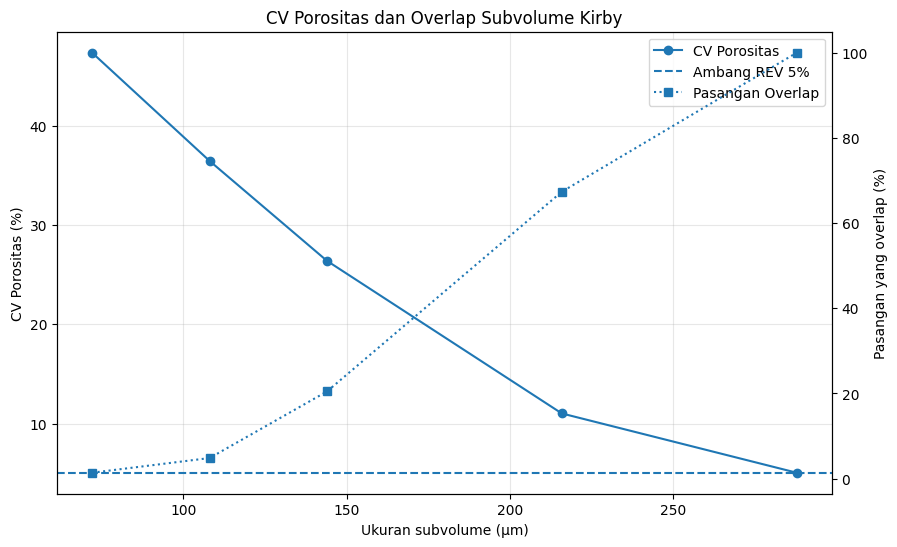

In [ ]:
# TAHAP 2.6 — GABUNGKAN HASIL CV DAN OVERLAP


import matplotlib.pyplot as plt
import numpy as np

print("Library visualisasi berhasil diimpor.")


fig, ax1 = plt.subplots(figsize=(10, 6))

# Grafik CV porositas
ax1.plot(
    ringkasan_por["ukuran_fisik_um"],
    ringkasan_por["CV_persen"],
    marker="o",
    label="CV Porositas"
)

ax1.axhline(
    y=5,
    linestyle="--",
    label="Ambang REV 5%"
)

ax1.set_xlabel("Ukuran subvolume (µm)")
ax1.set_ylabel("CV Porositas (%)")
ax1.grid(True, alpha=0.3)

# Sumbu kedua untuk overlap
ax2 = ax1.twinx()

ax2.plot(
    overlap_df["ukuran_voxel"] * DX_UM,
    overlap_df["persentase_pasangan_overlap"],
    marker="s",
    linestyle=":",
    label="Pasangan Overlap"
)

ax2.set_ylabel("Pasangan yang overlap (%)")

# Gabungkan legenda kedua sumbu
garis1, label1 = ax1.get_legend_handles_labels()
garis2, label2 = ax2.get_legend_handles_labels()

ax1.legend(
    garis1 + garis2,
    label1 + label2,
    loc="upper right"
)

plt.title("CV Porositas dan Overlap Subvolume Kirby")
plt.show()

In [ ]:
# TAHAP 2.7 — MENYIMPAN HASIL ANALISIS REV POROSITAS

subvolume_df.to_csv(
    "data_subvolume_kirby.csv",
    index=False
)

ringkasan_por.to_csv(
    "ringkasan_porositas_kirby.csv",
    index=False
)

overlap_df.to_csv(
    "diagnostik_overlap_kirby.csv",
    index=False
)

print("Seluruh hasil Tahap 2 berhasil disimpan:")
print("1. data_subvolume_kirby.csv")
print("2. ringkasan_porositas_kirby.csv")
print("3. diagnostik_overlap_kirby.csv")


Seluruh hasil Tahap 2 berhasil disimpan:
1. data_subvolume_kirby.csv
2. ringkasan_porositas_kirby.csv
3. diagnostik_overlap_kirby.csv


# Tahap 3 — Specific Surface Area (SSA)

In [ ]:
# TAHAP 3.1 — MENGHITUNG MUKA VOXEL PORI-SOLID

# Memastikan data Tahap 2 tersedia
assert "subvolume_df" in globals()
assert "volume" in globals()

hasil_ssa = []

for _, baris in subvolume_df.iterrows():

    L = int(baris["ukuran_voxel"])

    # Mengambil kembali subvolume dari koordinat yang tersimpan
    z = int(baris["z_awal"])
    y = int(baris["y_awal"])
    x = int(baris["x_awal"])

    sub = volume[
        z:z+L,
        y:y+L,
        x:x+L
    ]

    # Menghitung muka yang berbeda nilai pada tiga arah
    muka_z = np.count_nonzero(
        sub[:-1, :, :] != sub[1:, :, :]
    )

    muka_y = np.count_nonzero(
        sub[:, :-1, :] != sub[:, 1:, :]
    )

    muka_x = np.count_nonzero(
        sub[:, :, :-1] != sub[:, :, 1:]
    )

    # Total muka pori-solid
    total_muka = muka_x + muka_y + muka_z

    hasil_ssa.append({
        "ukuran_voxel": L,
        "nomor_sampel": int(baris["nomor_sampel"]),
        "muka_x": muka_x,
        "muka_y": muka_y,
        "muka_z": muka_z,
        "total_muka": total_muka
    })

# Menyimpan hasil dalam tabel
ssa_df = pd.DataFrame(hasil_ssa)

print("PERHITUNGAN MUKA VOXEL SELESAI")
print("Jumlah subvolume:", len(ssa_df))

display(ssa_df.head(10))


PERHITUNGAN MUKA VOXEL SELESAI
Jumlah subvolume: 150


,ukuran_voxel,nomor_sampel,muka_x,muka_y,muka_z,total_muka
0,32,1,1412,1459,1650,4521
1,32,2,490,459,821,1770
2,32,3,701,874,1214,2789
3,32,4,256,331,548,1135
4,32,5,1470,1552,1622,4644
5,32,6,1352,1126,1443,3921
6,32,7,1079,1192,1308,3579
7,32,8,1204,1129,1638,3971
8,32,9,760,601,533,1894
9,32,10,537,388,347,1272


In [ ]:
# TAHAP 3.2 — MENGHITUNG LUAS PERMUKAAN DAN SSA

# Luas satu muka voxel
LUAS_MUKA_VOXEL = DX_UM ** 2

# Volume satu voxel
VOLUME_VOXEL = DX_UM ** 3

# Menggabungkan jumlah muka voxel dengan data subvolume
ssa_df["luas_permukaan_um2"] = (
    ssa_df["total_muka"] * LUAS_MUKA_VOXEL
)

# Menghitung volume total setiap subvolume
ssa_df["volume_total_um3"] = (
    ssa_df["ukuran_voxel"] ** 3 * VOLUME_VOXEL
)

# Menghitung SSA sebelum koreksi
ssa_df["SSA_raw_um_inv"] = (
    ssa_df["luas_permukaan_um2"] /
    ssa_df["volume_total_um3"]
)

# Koreksi staircase bias dengan faktor 2/3
ssa_df["SSA_koreksi_um_inv"] = (
    ssa_df["SSA_raw_um_inv"] * (2 / 3)
)

print("PERHITUNGAN SSA SELESAI")
display(ssa_df.head(10).round(6))


PERHITUNGAN SSA SELESAI


,ukuran_voxel,nomor_sampel,muka_x,muka_y,muka_z,total_muka,luas_permukaan_um2,volume_total_um3,SSA_raw_um_inv,SSA_koreksi_um_inv
0,32,1,1412,1459,1650,4521,22887.5625,373248.0,0.061320,0.040880
1,32,2,490,459,821,1770,8960.6250,373248.0,0.024007,0.016005
2,32,3,701,874,1214,2789,14119.3125,373248.0,0.037828,0.025219
3,32,4,256,331,548,1135,5745.9375,373248.0,0.015394,0.010263
4,32,5,1470,1552,1622,4644,23510.2500,373248.0,0.062988,0.041992
5,32,6,1352,1126,1443,3921,19850.0625,373248.0,0.053182,0.035455
6,32,7,1079,1192,1308,3579,18118.6875,373248.0,0.048543,0.032362
7,32,8,1204,1129,1638,3971,20103.1875,373248.0,0.053860,0.035907
8,32,9,760,601,533,1894,9588.3750,373248.0,0.025689,0.017126
9,32,10,537,388,347,1272,6439.5000,373248.0,0.017253,0.011502


In [ ]:
# TAHAP 3.3 — STATISTIK SSA DAN CV

ringkasan_ssa = (
    ssa_df
    .groupby("ukuran_voxel")["SSA_koreksi_um_inv"]
    .agg(
        jumlah_sampel="count",
        rata_rata="mean",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .reset_index()
)

# Mengubah ukuran voxel ke mikrometer
ringkasan_ssa["ukuran_fisik_um"] = (
    ringkasan_ssa["ukuran_voxel"] * DX_UM
)

# Menghitung CV
ringkasan_ssa["CV"] = (
    ringkasan_ssa["standar_deviasi"] /
    ringkasan_ssa["rata_rata"]
)

ringkasan_ssa["CV_persen"] = (
    ringkasan_ssa["CV"] * 100
)

# Evaluasi ambang REV
ringkasan_ssa["status_REV"] = np.where(
    ringkasan_ssa["CV"] < 0.05,
    "Memenuhi ambang CV",
    "Belum memenuhi ambang CV"
)

display(ringkasan_ssa.round(6))

,ukuran_voxel,jumlah_sampel,rata_rata,standar_deviasi,minimum,maksimum,ukuran_fisik_um,CV,CV_persen,status_REV
0,32,30,0.030453,0.009441,0.010263,0.043023,72.0,0.310003,31.000283,Belum memenuhi ambang CV
1,48,30,0.030711,0.007232,0.013565,0.048850,108.0,0.235494,23.549421,Belum memenuhi ambang CV
2,64,30,0.031618,0.005088,0.022248,0.042963,144.0,0.160911,16.091084,Belum memenuhi ambang CV
3,96,30,0.031110,0.002428,0.026936,0.037140,216.0,0.078045,7.804538,Belum memenuhi ambang CV
4,128,30,0.032093,0.001506,0.029482,0.035507,288.0,0.046940,4.693961,Memenuhi ambang CV


In [ ]:
# TAHAP 3.4 — KEMIRINGAN KURVA CV (LOG-LOG)

# Ukuran subvolume dalam voxel
L = ringkasan_por["ukuran_voxel"].to_numpy()

# CV porositas dan SSA dalam bentuk desimal
CV_porositas = ringkasan_por["CV"].to_numpy()
CV_ssa = ringkasan_ssa["CV"].to_numpy()

# Regresi linear pada skala logaritmik
slope_por, intercept_por = np.polyfit(
    np.log(L),
    np.log(CV_porositas),
    1
)

slope_ssa, intercept_ssa = np.polyfit(
    np.log(L),
    np.log(CV_ssa),
    1
)

print("HASIL KEMIRINGAN KURVA CV")
print("--------------------------------")
print(f"Kemiringan CV Porositas : {slope_por:.4f}")
print(f"Kemiringan CV SSA       : {slope_ssa:.4f}")
print("Nilai teoritis          : -1.5000")
print("--------------------------------")

HASIL KEMIRINGAN KURVA CV
--------------------------------
Kemiringan CV Porositas : -1.6239
Kemiringan CV SSA       : -1.4019
Nilai teoritis          : -1.5000
--------------------------------


In [ ]:
# TAHAP 3.5 — MENYIMPAN HASIL SSA

ssa_df.to_csv(
    "data_ssa_subvolume_kirby.csv",
    index=False
)

ringkasan_ssa.to_csv(
    "ringkasan_ssa_kirby.csv",
    index=False
)

print("HASIL TAHAP 3 BERHASIL DISIMPAN")
print("1. data_ssa_subvolume_kirby.csv")
print("2. ringkasan_ssa_kirby.csv")


HASIL TAHAP 3 BERHASIL DISIMPAN
1. data_ssa_subvolume_kirby.csv
2. ringkasan_ssa_kirby.csv


# Tahap 4 — Simulasi permeabilitas dengan LBM

In [ ]:
# TAHAP 4.1 — PEMERIKSAAN LINGKUNGAN KOMPUTASI

import os
import platform
import numpy as np

print("INFORMASI LINGKUNGAN KOMPUTASI")
print("--------------------------------")

print("Sistem operasi:", platform.system())
print("Versi Python:", platform.python_version())
print("Jumlah CPU:", os.cpu_count())

# Memeriksa GPU NVIDIA
print("\nINFORMASI GPU:")

!nvidia-smi

# Memeriksa kesiapan data
print("\nPEMERIKSAAN DATA")

print("Dimensi citra:", volume.shape)
print("Tipe data:", volume.dtype)

print("\nPEMETAAN VOXEL:")
print("0 = Pori")
print("1 = Solid")

print("\nPorositas total:", np.mean(volume == 0))

print("\nPEMERIKSAAN SELESAI")


INFORMASI LINGKUNGAN KOMPUTASI
--------------------------------
Sistem operasi: Linux
Versi Python: 3.13.18
Jumlah CPU: 2

INFORMASI GPU:
/bin/bash: line 1: nvidia-smi: command not found

PEMERIKSAAN DATA
Dimensi citra: (256, 256, 256)
Tipe data: uint8

PEMETAAN VOXEL:
0 = Pori
1 = Solid

Porositas total: 0.20528411865234375

PEMERIKSAAN SELESAI


In [ ]:
# TAHAP 4.2 — PEMERIKSAAN NUMBA

try:
    import numba
    print("Numba tersedia")
    print("Versi Numba:", numba.__version__)
    ADA_NUMBA = True

except ImportError:
    print("Numba belum tersedia")
    ADA_NUMBA = False

print("Status percepatan CPU:", ADA_NUMBA)

Numba tersedia
Versi Numba: 0.64.0
Status percepatan CPU: True


In [ ]:
# TAHAP 4.3 — PERSIAPAN LBM D3Q19

import numpy as np
import time
import numba as nb
from scipy import ndimage as ndi

DARCY = 0.987e-12

def kisi(nama):
    if nama == "D2Q9":
        c = np.array([
            [0,0], [1,0], [0,1], [-1,0], [0,-1],
            [1,1], [-1,1], [-1,-1], [1,-1]
        ])
        w = np.array([4/9] + [1/9]*4 + [1/36]*4)

    elif nama == "D3Q19":
        c = [[0,0,0]]

        for a in range(3):
            for s in (1,-1):
                v = [0,0,0]
                v[a] = s
                c.append(v)

        for a in range(3):
            for b in range(a+1,3):
                for s1 in (1,-1):
                    for s2 in (1,-1):
                        v = [0,0,0]
                        v[a] = s1
                        v[b] = s2
                        c.append(v)

        c = np.array(c)
        w = np.array([1/3] + [1/18]*6 + [1/36]*12)

    else:
        raise ValueError(nama)

    opp = np.array([
        np.where((c == -ci).all(1))[0][0]
        for ci in c
    ])

    return c, w, opp


# Pemeriksaan kisi
c, w, opp = kisi("D3Q19")

print("PEMERIKSAAN KISI LBM")
print("--------------------")
print("Jumlah arah kecepatan:", len(w))
print("Dimensi kisi:", c.shape)
print("Jumlah pasangan arah berlawanan:", len(opp))
print("Jumlah bobot:", len(w))
print("Total bobot:", w.sum())

assert len(w) == 19
assert abs(w.sum() - 1.0) < 1e-12

print("\nKISI D3Q19 BERHASIL DISIAPKAN")

PEMERIKSAAN KISI LBM
--------------------
Jumlah arah kecepatan: 19
Dimensi kisi: (19, 3)
Jumlah pasangan arah berlawanan: 19
Jumlah bobot: 19
Total bobot: 1.0

KISI D3Q19 BERHASIL DISIAPKAN


In [ ]:
try:
    import numba as nb
    ADA_NUMBA = True
except ImportError:
    ADA_NUMBA = False

print("Numba aktif:", ADA_NUMBA)

Numba aktif: True


In [ ]:
# TAHAP 4.4 — PEMECAH LBM TRT D3Q19
# Kode diadaptasi dari P11_Penurunan_Sifat_Efektif.ipynb

if not ADA_NUMBA:
    class nb:
        @staticmethod
        def njit(**k):
            return lambda f: f


@nb.njit
def _langkah(f, fb, nbr, c, w, opp, F, wp, wm, u, rho):
    Q, n = f.shape
    D = c.shape[1]

    for j in range(n):
        r = 0.0
        for i in range(Q):
            r += f[i, j]

        for a in range(D):
            m = 0.0
            for i in range(Q):
                m += c[i, a] * f[i, j]
            u[a, j] = (m + 0.5 * F[a]) / r

        rho[j] = r
        uu = 0.0
        uF = 0.0

        for a in range(D):
            uu += u[a, j] * u[a, j]
            uF += F[a] * u[a, j]

        for i in range(Q):
            if opp[i] < i:
                continue

            o = opp[i]
            cu = 0.0
            cF = 0.0

            for a in range(D):
                cu += c[i, a] * u[a, j]
                cF += c[i, a] * F[a]

            ei = w[i] * r * (
                1 + 3 * cu + 4.5 * cu * cu - 1.5 * uu
            )
            eo = w[o] * r * (
                1 - 3 * cu + 4.5 * cu * cu - 1.5 * uu
            )

            fp = 0.5 * (f[i, j] + f[o, j])
            fm = 0.5 * (f[i, j] - f[o, j])
            ep = 0.5 * (ei + eo)
            em = 0.5 * (ei - eo)

            Sg = w[i] * (-3 * uF + 9 * cu * cF)
            Sa = w[i] * 3 * cF

            gp = -wp * (fp - ep) + (1 - 0.5 * wp) * Sg
            gm = -wm * (fm - em) + (1 - 0.5 * wm) * Sa

            if i == o:
                fb[i, j] = f[i, j] + gp + gm
            else:
                fb[i, j] = f[i, j] + gp + gm
                fb[o, j] = f[o, j] + gp - gm

    # Streaming tarik dan bounce-back
    for i in range(Q):
        for j in range(n):
            s = nbr[i, j]
            if s >= 0:
                f[i, j] = fb[i, s]
            else:
                f[i, j] = fb[opp[i], j]


def jalankan(
    padat,
    tau,
    g=1e-5,
    arah=0,
    maks=400000,
    tol=1e-7,
    periksa=100,
    catat=False,
    operator="TRT",
    lam=3/16,
    cetak=False,
    **_
):
    D = padat.ndim
    nama = "D2Q9" if D == 2 else "D3Q19"

    c, w, opp = kisi(nama)
    Q = len(w)

    nu = (tau - 0.5) / 3.0
    sh = padat.shape

    alir = ~padat
    idx = -np.ones(sh, np.int64)
    idx[alir] = np.arange(alir.sum())
    n = int(alir.sum())

    nbr = np.empty((Q, n), np.int64)

    for i in range(Q):
        sumber = np.roll(
            idx,
            shift=tuple(c[i]),
            axis=tuple(range(D))
        )
        nbr[i] = sumber[alir]

    F = np.zeros(D)
    F[arah] = g

    if operator == "BGK":
        wp = wm = 1.0 / tau
    else:
        wp = 1.0 / tau
        wm = 1.0 / (0.5 + lam / (tau - 0.5))

    f = np.repeat(w[:, None], n, 1).astype(np.float64)
    fb = np.empty_like(f)
    u = np.zeros((D, n))
    rho = np.ones(n)
    cf = c.astype(np.float64)

    riwayat = []
    ux_lama = 0.0
    N = padat.size

    for k in range(1, maks + 1):
        _langkah(
            f, fb, nbr, cf, w, opp,
            F, wp, wm, u, rho
        )

        if k % periksa == 0:
            ux = u[arah].sum() / N
            ubah = abs(ux - ux_lama) / max(abs(ux), 1e-30)

            if catat:
                riwayat.append((k, ux, ubah))

            ux_lama = ux

            if not np.isfinite(ux) or ubah < tol:
                break

    rho = f.sum(0)
    uf = (cf.T @ f + 0.5 * F[:, None]) / rho

    U = np.zeros((D,) + sh)
    R = np.ones(sh)

    for a in range(D):
        U[a][alir] = uf[a]

    R[alir] = rho

    uD = U[arah].mean()
    kk = nu * uD / g
    umaks = np.sqrt((U ** 2).sum(0)).max()

    return dict(
        u=U,
        rho=R,
        k=kk,
        uD=uD,
        langkah=k,
        riwayat=riwayat,
        nu=nu,
        umaks=umaks,
        Ma=umaks * np.sqrt(3),
        meledak=not np.isfinite(kk)
    )


print("Pemecah LBM TRT berhasil dimuat.")
print("Numba aktif:", ADA_NUMBA)

Pemecah LBM TRT berhasil dimuat.
Numba aktif: True


In [ ]:

# TAHAP 4.5 — FUNGSI IDENTIFIKASI PORI TEMBUS
# Diadaptasi dari P11_Penurunan_Sifat_Efektif.ipynb

def label_periodik(pori, sumbu=None):
    lab, n = ndi.label(pori)
    induk = list(range(n + 1))

    def akar(a):
        while induk[a] != a:
            induk[a] = induk[induk[a]]
            a = induk[a]
        return a

    for ax in (range(pori.ndim) if sumbu is None else sumbu):
        a = np.take(lab, 0, axis=ax)
        b = np.take(lab, -1, axis=ax)
        m = (a > 0) & (b > 0)

        for p, q in set(zip(a[m].tolist(), b[m].tolist())):
            ra, rb = akar(p), akar(q)
            if ra != rb:
                induk[ra] = rb

    peta = np.array([akar(i) for i in range(n + 1)])
    return peta[lab]


def pori_tembus(padat, arah=0):
    pori = ~padat
    lab = label_periodik(pori)

    lab2 = label_periodik(
        pori,
        [a for a in range(pori.ndim) if a != arah]
    )

    a = set(np.unique(np.take(lab2, 0, axis=arah))) - {0}
    b = set(np.unique(np.take(lab2, -1, axis=arah))) - {0}

    tembus2 = np.isin(lab2, list(a & b))
    kel = set(np.unique(lab[tembus2])) - {0}

    return np.isin(lab, list(kel))


print("Fungsi pori tembus berhasil dimuat.")


Fungsi pori tembus berhasil dimuat.


In [ ]:
# CEK NAMA KOLOM DAN CONTOH DATA
print("DAFTAR KOLOM:")
print(subvolume_df.columns.tolist())

print("\n5 BARIS PERTAMA:")
display(subvolume_df.head())

DAFTAR KOLOM:
['ukuran_voxel', 'ukuran_fisik_um', 'nomor_sampel', 'z_awal', 'y_awal', 'x_awal', 'z_akhir', 'y_akhir', 'x_akhir', 'jumlah_pori', 'jumlah_total_voxel', 'porositas']

5 BARIS PERTAMA:


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,z_akhir,y_akhir,x_akhir,jumlah_pori,jumlah_total_voxel,porositas
0,32,72.0,1,94,206,121,126,238,153,9499,32768,0.289886
1,32,72.0,2,42,127,211,74,159,243,2272,32768,0.069336
2,32,72.0,3,116,31,91,148,63,123,5725,32768,0.174713
3,32,72.0,4,178,72,186,210,104,218,1817,32768,0.055450
4,32,72.0,5,14,186,54,46,218,86,6533,32768,0.199371


In [ ]:
# PILIH SUBVOLUME PERTAMA DENGAN UKURAN 32³

baris_uji = subvolume_df[
    subvolume_df["ukuran_voxel"] == 32
].iloc[0]

L = int(baris_uji["ukuran_voxel"])

z0 = int(baris_uji["z_awal"])
y0 = int(baris_uji["y_awal"])
x0 = int(baris_uji["x_awal"])

# Ekstrak subvolume dari citra utama
sub_uji = volume[
    z0:z0+L,
    y0:y0+L,
    x0:x0+L
]

# True = batuan padat, False = pori
padat_uji = (sub_uji == 1)

print("SUBVOLUME UJI BERHASIL DIPILIH")
print("--------------------------------")
print("Nomor sampel:", baris_uji["nomor_sampel"])
print("Ukuran:", sub_uji.shape)
print("Koordinat awal (z,y,x):", (z0, y0, x0))
print("Porositas:", round((sub_uji == 0).mean(), 6))
print("Jumlah voxel pori:", (sub_uji == 0).sum())
print("Jumlah voxel padat:", padat_uji.sum())

SUBVOLUME UJI BERHASIL DIPILIH
--------------------------------
Nomor sampel: 1.0
Ukuran: (32, 32, 32)
Koordinat awal (z,y,x): (94, 206, 121)
Porositas: 0.289886
Jumlah voxel pori: 9499
Jumlah voxel padat: 23269


In [ ]:
# TAHAP 4.7 — UJI KONEKTIVITAS PORI TIGA ARAH

for arah, nama in [(0, "Z"), (1, "Y"), (2, "X")]:
    tembus = pori_tembus(padat_uji, arah=arah)

    jumlah_pori_tembus = np.count_nonzero(tembus)
    porositas_tembus = tembus.mean()

    print(f"\nARAH {nama}")
    print("-" * 25)
    print("Jumlah voxel pori tembus:", jumlah_pori_tembus)
    print("Fraksi volume pori tembus:", round(porositas_tembus, 6))
    print("Persentase volume pori tembus:", round(porositas_tembus * 100, 4), "%")


ARAH Z
-------------------------
Jumlah voxel pori tembus: 9364
Fraksi volume pori tembus: 0.285767
Persentase volume pori tembus: 28.5767 %

ARAH Y
-------------------------
Jumlah voxel pori tembus: 9364
Fraksi volume pori tembus: 0.285767
Persentase volume pori tembus: 28.5767 %

ARAH X
-------------------------
Jumlah voxel pori tembus: 9364
Fraksi volume pori tembus: 0.285767
Persentase volume pori tembus: 28.5767 %


In [ ]:
# TAHAP 4.8 — MEMBANDINGKAN MASK PORI TEMBUS

tembus_z = pori_tembus(padat_uji, arah=0)
tembus_y = pori_tembus(padat_uji, arah=1)
tembus_x = pori_tembus(padat_uji, arah=2)

print("VALIDASI MASK PORI TEMBUS")
print("-------------------------")

print("Z dan Y identik:", np.array_equal(tembus_z, tembus_y))
print("Z dan X identik:", np.array_equal(tembus_z, tembus_x))
print("Y dan X identik:", np.array_equal(tembus_y, tembus_x))

print("\nJumlah voxel yang berbeda:")
print("Z vs Y:", np.count_nonzero(tembus_z != tembus_y))
print("Z vs X:", np.count_nonzero(tembus_z != tembus_x))
print("Y vs X:", np.count_nonzero(tembus_y != tembus_x))

VALIDASI MASK PORI TEMBUS
-------------------------
Z dan Y identik: True
Z dan X identik: True
Y dan X identik: True

Jumlah voxel yang berbeda:
Z vs Y: 0
Z vs X: 0
Y vs X: 0


In [ ]:
# TAHAP 4.9 — MENYIAPKAN DOMAIN LBM

tembus_uji = pori_tembus(padat_uji, arah=0)

# True = padatan, False = fluida
padat_lbm = ~tembus_uji

print("DOMAIN LBM SIAP")
print("----------------")
print("Ukuran domain:", padat_lbm.shape)
print("Jumlah voxel fluida:", np.count_nonzero(~padat_lbm))
print("Jumlah voxel padatan:", np.count_nonzero(padat_lbm))
print("Fraksi fluida:", round((~padat_lbm).mean(), 6))
print("Fraksi padatan:", round(padat_lbm.mean(), 6))

DOMAIN LBM SIAP
----------------
Ukuran domain: (32, 32, 32)
Jumlah voxel fluida: 9364
Jumlah voxel padatan: 23404
Fraksi fluida: 0.285767
Fraksi padatan: 0.714233


In [ ]:
# TAHAP 4.10 — CEK PARAMETER LBM

parameter = ["TAU", "G", "DARCY"]

for nama in parameter:
    if nama in globals():
        print(f"{nama} =", globals()[nama])
    else:
        print(f"{nama} belum tersedia")

print("\nFungsi jalankan tersedia:", "jalankan" in globals())
print("Fungsi sifat_aliran tersedia:", "sifat_aliran" in globals())

TAU belum tersedia
G belum tersedia
DARCY = 9.87e-13

Fungsi jalankan tersedia: True
Fungsi sifat_aliran tersedia: False


In [ ]:
# TAHAP 4.11 — PARAMETER LBM DAN FUNGSI ANALISIS

TAU = 1.0
G = 2e-6
DARCY = 0.987e-12

def sifat_aliran(hasil, padat, g, arah=0):
    u = hasil["u"]
    nu = hasil["nu"]
    pori = ~padat

    ux = u[arah]
    k_vol = nu * ux.mean() / g

    sumbu = tuple(a for a in range(padat.ndim) if a != arah)
    k_irisan = nu * ux.mean(axis=sumbu) / g

    besar = np.sqrt((u ** 2).sum(0))
    tau_u = besar[pori].sum() / ux[pori].sum()

    return {
        "k_vol": float(k_vol),
        "k_irisan_min": float(k_irisan.min()),
        "k_irisan_maks": float(k_irisan.max()),
        "k_irisan_sb": float(k_irisan.std() / k_irisan.mean()),
        "tau_u": float(tau_u)
    }

print("PARAMETER LBM")
print("TAU:", TAU)
print("G:", G)
print("DARCY:", DARCY)
print("Fungsi sifat_aliran berhasil dimuat:", callable(sifat_aliran))

PARAMETER LBM
TAU: 1.0
G: 2e-06
DARCY: 9.87e-13
Fungsi sifat_aliran berhasil dimuat: True


In [ ]:
# TAHAP 4.12 — SIMULASI LBM 32³ ARAH Z

import time

print("Memulai simulasi LBM...")
waktu_mulai = time.time()

hasil_z = jalankan(
    padat_lbm,
    TAU,
    g=G,
    arah=0,
    tol=1e-7,
    periksa=100,
    catat=True,
    cetak=True
)

waktu_selesai = time.time() - waktu_mulai

print("\nSIMULASI SELESAI")
print("----------------")
print("Waktu komputasi:", round(waktu_selesai, 2), "detik")
print("Jumlah langkah:", hasil_z["langkah"])
print("Permeabilitas (satuan voxel²):", hasil_z["k"])
print("Viskositas kinematik:", hasil_z["nu"])
print("Mach number:", hasil_z["Ma"])
print("Simulasi meledak:", hasil_z["meledak"])
print("Jumlah catatan konvergensi:", len(hasil_z["riwayat"]))

Memulai simulasi LBM...

SIMULASI SELESAI
----------------
Waktu komputasi: 24.6 detik
Jumlah langkah: 6300
Permeabilitas (satuan voxel²): 0.00923530906180314
Viskositas kinematik: 0.16666666666666666
Mach number: 1.846861923304899e-05
Simulasi meledak: False
Jumlah catatan konvergensi: 63


In [ ]:
# TAHAP 4.13 — ANALISIS HASIL LBM ARAH Z

analisis_z = sifat_aliran(
    hasil_z,
    padat_lbm,
    G,
    arah=0
)

# Konversi permeabilitas dari voxel² ke mD
k_m2_z = analisis_z["k_vol"] * (2.25e-6 ** 2)
k_mD_z = k_m2_z / DARCY * 1000

print("HASIL ANALISIS LBM ARAH Z")
print("-------------------------")
print("Permeabilitas (voxel²):", analisis_z["k_vol"])
print("Permeabilitas (m²):", k_m2_z)
print("Permeabilitas (mD):", k_mD_z)
print("Fluks irisan minimum:", analisis_z["k_irisan_min"])
print("Fluks irisan maksimum:", analisis_z["k_irisan_maks"])
print("Simpangan relatif antaririsan:", analisis_z["k_irisan_sb"])
print("Tortuositas aliran:", analisis_z["tau_u"])

HASIL ANALISIS LBM ARAH Z
-------------------------
Permeabilitas (voxel²): 0.00923530906180314
Permeabilitas (m²): 4.67537521253784e-14
Permeabilitas (mD): 47.369556358032824
Fluks irisan minimum: 0.008671017066735544
Fluks irisan maksimum: 0.00999157398323167
Simpangan relatif antaririsan: 0.04018911406773979
Tortuositas aliran: 1.6816469577931252


In [ ]:
# TAHAP 4.14 — PEMERIKSAAN KONVERGENSI

riwayat_z = np.array(hasil_z["riwayat"])

print("BENTUK DATA RIWAYAT:", riwayat_z.shape)
print("\n10 CATATAN TERAKHIR:")
print(riwayat_z[-10:])

print("\nPEMERIKSAAN KONVERGENSI")
print("-----------------------")
print("Perubahan relatif terakhir:", riwayat_z[-1, 2])
print("Target P11:", 1e-7)
print("Memenuhi target:", riwayat_z[-1, 2] < 1e-7)

BENTUK DATA RIWAYAT: (63, 3)

10 CATATAN TERAKHIR:
[[5.40000000e+03 1.10299115e-07 2.72073881e-07]
 [5.50000000e+03 1.10299141e-07 2.40960703e-07]
 [5.60000000e+03 1.10299165e-07 2.13408954e-07]
 [5.70000000e+03 1.10299186e-07 1.89032713e-07]
 [5.80000000e+03 1.10299204e-07 1.67467045e-07]
 [5.90000000e+03 1.10299221e-07 1.48356747e-07]
 [6.00000000e+03 1.10299235e-07 1.31477065e-07]
 [6.10000000e+03 1.10299248e-07 1.16520469e-07]
 [6.20000000e+03 1.10299259e-07 1.03279393e-07]
 [6.30000000e+03 1.10299269e-07 9.15757635e-08]]

PEMERIKSAAN KONVERGENSI
-----------------------
Perubahan relatif terakhir: 9.157576347879188e-08
Target P11: 1e-07
Memenuhi target: True


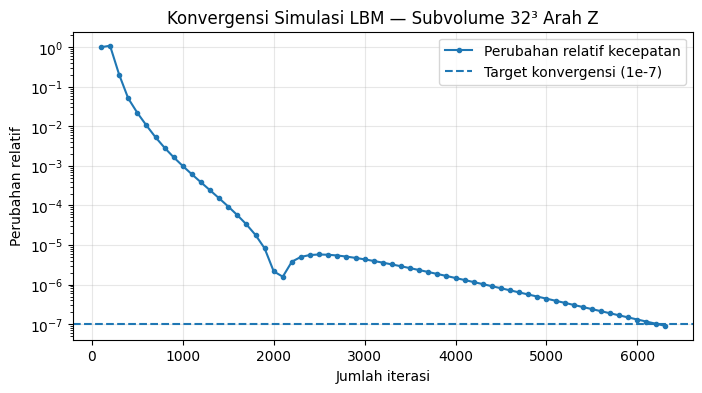

In [ ]:
# TAHAP 4.15 — GRAFIK KONVERGENSI LBM

plt.figure(figsize=(8, 4))

plt.semilogy(
    riwayat_z[:, 0],
    riwayat_z[:, 2],
    marker="o",
    markersize=3,
    label="Perubahan relatif kecepatan"
)

plt.axhline(
    1e-7,
    linestyle="--",
    label="Target konvergensi (1e-7)"
)

plt.xlabel("Jumlah iterasi")
plt.ylabel("Perubahan relatif")
plt.title("Konvergensi Simulasi LBM — Subvolume 32³ Arah Z")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# TAHAP 4.16 — SIMULASI LBM ARAH Y

import time

print("Memulai simulasi LBM arah Y...")
waktu_mulai = time.time()

hasil_y = jalankan(
    padat_lbm,
    TAU,
    g=G,
    arah=1,
    tol=1e-7,
    periksa=100,
    catat=True,
    cetak=True
)

waktu_y = time.time() - waktu_mulai

print("\nHASIL SIMULASI ARAH Y")
print("---------------------")
print("Waktu komputasi:", round(waktu_y, 2), "detik")
print("Jumlah langkah:", hasil_y["langkah"])
print("Permeabilitas kisi:", hasil_y["k"])
print("Mach number:", hasil_y["Ma"])
print("Simulasi meledak:", hasil_y["meledak"])
print("Perubahan relatif terakhir:", hasil_y["riwayat"][-1][2])

Memulai simulasi LBM arah Y...

HASIL SIMULASI ARAH Y
---------------------
Waktu komputasi: 22.45 detik
Jumlah langkah: 5900
Permeabilitas kisi: 0.014512971425492887
Mach number: 4.851885348356552e-05
Simulasi meledak: False
Perubahan relatif terakhir: 9.921011996461925e-08


In [ ]:
# TAHAP 4.17 — ANALISIS HASIL LBM ARAH Y

analisis_y = sifat_aliran(
    hasil_y,
    padat_lbm,
    G,
    arah=1
)

k_m2_y = analisis_y["k_vol"] * (2.25e-6 ** 2)
k_mD_y = k_m2_y / DARCY * 1000

print("HASIL ANALISIS LBM ARAH Y")
print("-------------------------")
print("Permeabilitas (voxel²):", analisis_y["k_vol"])
print("Permeabilitas (m²):", k_m2_y)
print("Permeabilitas (mD):", k_mD_y)
print("Fluks irisan minimum:", analisis_y["k_irisan_min"])
print("Fluks irisan maksimum:", analisis_y["k_irisan_maks"])
print("Simpangan relatif antaririsan:", analisis_y["k_irisan_sb"])
print("Tortuositas aliran:", analisis_y["tau_u"])

HASIL ANALISIS LBM ARAH Y
-------------------------
Permeabilitas (voxel²): 0.014512971425492887
Permeabilitas (m²): 7.347191784155774e-14
Permeabilitas (mD): 74.43963307148707
Fluks irisan minimum: 0.014323262072209289
Fluks irisan maksimum: 0.014703377134870115
Simpangan relatif antaririsan: 0.008722283823983297
Tortuositas aliran: 1.561185461325997


In [ ]:
# TAHAP 4.18 — SIMULASI LBM ARAH X

import time

print("Memulai simulasi LBM arah X...")
waktu_mulai = time.time()

hasil_x = jalankan(
    padat_lbm,
    TAU,
    g=G,
    arah=2,
    tol=1e-7,
    periksa=100,
    catat=True,
    cetak=True
)

waktu_x = time.time() - waktu_mulai

print("\nHASIL SIMULASI ARAH X")
print("---------------------")
print("Waktu komputasi:", round(waktu_x, 2), "detik")
print("Jumlah langkah:", hasil_x["langkah"])
print("Permeabilitas kisi:", hasil_x["k"])
print("Mach number:", hasil_x["Ma"])
print("Simulasi meledak:", hasil_x["meledak"])
print("Perubahan relatif terakhir:", hasil_x["riwayat"][-1][2])

Memulai simulasi LBM arah X...

HASIL SIMULASI ARAH X
---------------------
Waktu komputasi: 10.84 detik
Jumlah langkah: 1700
Permeabilitas kisi: 0.5422526010518023
Mach number: 0.00024045600242082884
Simulasi meledak: False
Perubahan relatif terakhir: 8.862961071271631e-08


In [ ]:
# TAHAP 4.19 — ANALISIS HASIL LBM ARAH X

analisis_x = sifat_aliran(
    hasil_x,
    padat_lbm,
    G,
    arah=2
)

k_m2_x = analisis_x["k_vol"] * (2.25e-6 ** 2)
k_mD_x = k_m2_x / DARCY * 1000

print("HASIL ANALISIS LBM ARAH X")
print("-------------------------")
print("Permeabilitas (voxel²):", analisis_x["k_vol"])
print("Permeabilitas (m²):", k_m2_x)
print("Permeabilitas (mD):", k_mD_x)
print("Fluks irisan minimum:", analisis_x["k_irisan_min"])
print("Fluks irisan maksimum:", analisis_x["k_irisan_maks"])
print("Simpangan relatif antaririsan:", analisis_x["k_irisan_sb"])
print("Tortuositas aliran:", analisis_x["tau_u"])

HASIL ANALISIS LBM ARAH X
-------------------------
Permeabilitas (voxel²): 0.5422526010518023
Permeabilitas (m²): 2.745153792824749e-12
Permeabilitas (mD): 2781.31083366236
Fluks irisan minimum: 0.5420274188496987
Fluks irisan maksimum: 0.543299871745051
Simpangan relatif antaririsan: 0.00040796845840151855
Tortuositas aliran: 1.0535674563908328


In [ ]:
# TAHAP 4.20 — REKAP HASIL PERMEABILITAS

rekap_lbm = pd.DataFrame([
    {
        "arah": "Z",
        "k_voxel2": analisis_z["k_vol"],
        "k_mD": analisis_z["k_vol"] * (2.25e-6)**2 / DARCY * 1000,
        "tortuositas": analisis_z["tau_u"],
        "simpangan_fluks": analisis_z["k_irisan_sb"] * 100
    },
    {
        "arah": "Y",
        "k_voxel2": analisis_y["k_vol"],
        "k_mD": analisis_y["k_vol"] * (2.25e-6)**2 / DARCY * 1000,
        "tortuositas": analisis_y["tau_u"],
        "simpangan_fluks": analisis_y["k_irisan_sb"] * 100
    },
    {
        "arah": "X",
        "k_voxel2": analisis_x["k_vol"],
        "k_mD": analisis_x["k_vol"] * (2.25e-6)**2 / DARCY * 1000,
        "tortuositas": analisis_x["tau_u"],
        "simpangan_fluks": analisis_x["k_irisan_sb"] * 100
    }
])

display(rekap_lbm.round(6))

k_maks = rekap_lbm["k_mD"].max()
k_min = rekap_lbm["k_mD"].min()

print("\nRASIO ANISOTROPI SEMENTARA")
print("k maksimum:", round(k_maks, 3), "mD")
print("k minimum:", round(k_min, 3), "mD")
print("kmax/kmin:", round(k_maks / k_min, 4))

,arah,k_voxel2,k_mD,tortuositas,simpangan_fluks
0,Z,0.009235,47.369556,1.681647,4.018911
1,Y,0.014513,74.439633,1.561185,0.872228
2,X,0.542253,2781.310834,1.053567,0.040797



RASIO ANISOTROPI SEMENTARA
k maksimum: 2781.311 mD
k minimum: 47.37 mD
kmax/kmin: 58.7152


In [ ]:
# TAHAP 4.21 — VALIDASI KONSISTENSI HASIL LBM

hasil_validasi = [
    ("Z", hasil_z, analisis_z),
    ("Y", hasil_y, analisis_y),
    ("X", hasil_x, analisis_x)
]

for nama, hasil, analisis in hasil_validasi:
    selisih = abs(hasil["k"] - analisis["k_vol"])

    print(f"\nARAH {nama}")
    print("-" * 30)
    print("k dari solver:", hasil["k"])
    print("k dari analisis:", analisis["k_vol"])
    print("Selisih:", selisih)
    print("Konvergen:", hasil["riwayat"][-1][2] < 1e-7)
    print("Mach number:", hasil["Ma"])
    print("Simulasi stabil:", not hasil["meledak"])


ARAH Z
------------------------------
k dari solver: 0.00923530906180314
k dari analisis: 0.00923530906180314
Selisih: 0.0
Konvergen: True
Mach number: 1.846861923304899e-05
Simulasi stabil: True

ARAH Y
------------------------------
k dari solver: 0.014512971425492887
k dari analisis: 0.014512971425492887
Selisih: 0.0
Konvergen: True
Mach number: 4.851885348356552e-05
Simulasi stabil: True

ARAH X
------------------------------
k dari solver: 0.5422526010518023
k dari analisis: 0.5422526010518023
Selisih: 0.0
Konvergen: True
Mach number: 0.00024045600242082884
Simulasi stabil: True


In [ ]:
# TAHAP 4.22 — SIMPAN HASIL LBM SUBVOLUME PERTAMA

rekap_lbm.to_csv(
    "hasil_lbm_kirby_32_sampel_1.csv",
    index=False
)

print("File berhasil disimpan:")
print("hasil_lbm_kirby_32_sampel_1.csv")

from google.colab import files
files.download("hasil_lbm_kirby_32_sampel_1.csv")

File berhasil disimpan:
hasil_lbm_kirby_32_sampel_1.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Ambil data subvolume ukuran 32, sampel nomor 2
baris = subvolume_df[
    (subvolume_df["ukuran_voxel"] == 32) &
    (subvolume_df["nomor_sampel"] == 2)
].iloc[0]

# Ambil koordinat awal
z0 = int(baris["z_awal"])
y0 = int(baris["y_awal"])
x0 = int(baris["x_awal"])

# Ekstrak subvolume dari citra batuan
sub_uji = volume[
    z0:z0+32,
    y0:y0+32,
    x0:x0+32
]

# Identifikasi bagian padat
padat_uji = (sub_uji == 1)

print("SUBVOLUME 32³ - SAMPEL 2")
print("Koordinat awal (z, y, x):", (z0, y0, x0))
print("Ukuran subvolume:", sub_uji.shape)
print("Porositas total:", round(np.mean(sub_uji == 0), 6))

# Periksa pori tembus untuk masing-masing arah
for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    tembus = pori_tembus(padat_uji, arah=arah)
    jumlah = np.count_nonzero(tembus)
    fraksi = jumlah / sub_uji.size

    print(
        f"Arah {nama}: "
        f"{jumlah:,} voxel pori tembus | "
        f"fraksi terhadap volume = {fraksi:.4%}"
    )

SUBVOLUME 32³ - SAMPEL 2
Koordinat awal (z, y, x): (42, 127, 211)
Ukuran subvolume: (32, 32, 32)
Porositas total: 0.069336
Arah Z: 2,013 voxel pori tembus | fraksi terhadap volume = 6.1432%
Arah Y: 2,013 voxel pori tembus | fraksi terhadap volume = 6.1432%
Arah X: 0 voxel pori tembus | fraksi terhadap volume = 0.0000%


In [ ]:
# Periksa struktur hasil analisis arah Z
print("KEY HASIL ANALISIS:")
print(hasil_sampel2["Z"]["analisis"].keys())

print("\nISI HASIL ANALISIS:")
print(hasil_sampel2["Z"]["analisis"])

KEY HASIL ANALISIS:
dict_keys(['k_vol', 'k_irisan_min', 'k_irisan_maks', 'k_irisan_sb', 'tau_u'])

ISI HASIL ANALISIS:
{'k_vol': 0.004220091614208071, 'k_irisan_min': 0.0036273316290894443, 'k_irisan_maks': 0.005542725927836252, 'k_irisan_sb': 0.09912924048026105, 'tau_u': 1.4790432866273602}


In [ ]:
# Konversi permeabilitas Z ke mD
k_z = hasil_sampel2["Z"]["analisis"]["k_vol"]
k_z_md = k_z * (DX_UM * 1e-6)**2 / DARCY * 1000

print("HASIL ARAH Z")
print("Permeabilitas:", round(k_z_md, 4), "mD")
print("Ketidakseragaman irisan:",
      round(hasil_sampel2["Z"]["analisis"]["k_irisan_sb"] * 100, 4), "%")
print("Tortuositas:", round(hasil_sampel2["Z"]["analisis"]["tau_u"], 4))

# Simulasi arah Y
print("\nMemulai simulasi arah Y...")

tembus_y = pori_tembus(padat_uji, arah=1)
padat_lbm_y = ~tembus_y

hasil_y2 = jalankan(
    padat_lbm_y,
    TAU,
    g=G,
    arah=1,
    tol=1e-7,
    periksa=100,
    catat=True
)

analisis_y2 = sifat_aliran(
    hasil_y2,
    padat_lbm_y,
    g=G,
    arah=1
)

hasil_sampel2["Y"] = {
    "hasil": hasil_y2,
    "analisis": analisis_y2
}

k_y = analisis_y2["k_vol"]
k_y_md = k_y * (DX_UM * 1e-6)**2 / DARCY * 1000

print("\nHASIL ARAH Y")
print("Permeabilitas:", round(k_y_md, 4), "mD")
print("Jumlah langkah:", hasil_y2["langkah"])
print("Ma:", hasil_y2["Ma"])
print("Simulasi stabil:", not hasil_y2["meledak"])
print("Riwayat konvergensi terakhir:", hasil_y2["riwayat"][-1])
print("Ketidakseragaman irisan:",
      round(analisis_y2["k_irisan_sb"] * 100, 4), "%")

HASIL ARAH Z
Permeabilitas: 21.6456 mD
Ketidakseragaman irisan: 9.9129 %
Tortuositas: 1.479

Memulai simulasi arah Y...

HASIL ARAH Y
Permeabilitas: 87.5444 mD
Jumlah langkah: 1000
Ma: 3.880737612348195e-05
Simulasi stabil: True
Riwayat konvergensi terakhir: (1000, np.float64(2.0475981917711305e-07), np.float64(5.410156721998254e-08))
Ketidakseragaman irisan: 0.6004 %


In [ ]:
# Pemeriksaan kualitas hasil LBM sampel 2

for nama in ["Z", "Y"]:
    hasil = hasil_sampel2[nama]["hasil"]
    analisis = hasil_sampel2[nama]["analisis"]

    perubahan_akhir = float(hasil["riwayat"][-1][2])

    print(f"\nARAH {nama}")
    print("Konvergen:", perubahan_akhir < 1e-7)
    print("Perubahan relatif terakhir:", perubahan_akhir)
    print("Stabil:", not hasil["meledak"])
    print("Mach number:", hasil["Ma"])
    print("Ketidakseragaman irisan:",
          f'{analisis["k_irisan_sb"]:.4%}')


ARAH Z
Konvergen: True
Perubahan relatif terakhir: 8.191996503822738e-08
Stabil: True
Mach number: 2.7071347532029087e-05
Ketidakseragaman irisan: 9.9129%

ARAH Y
Konvergen: True
Perubahan relatif terakhir: 5.410156721998254e-08
Stabil: True
Mach number: 3.880737612348195e-05
Ketidakseragaman irisan: 0.6004%


In [ ]:
# Membuat rekap hasil sampel 2
baris_hasil = {
    "ukuran_voxel": 32,
    "nomor_sampel": 2,
    "z_awal": z0,
    "y_awal": y0,
    "x_awal": x0,
    "porositas": float(np.mean(sub_uji == 0)),
}

for nama in ["Z", "Y"]:
    hasil = hasil_sampel2[nama]["hasil"]
    analisis = hasil_sampel2[nama]["analisis"]

    k_md = (
        analisis["k_vol"]
        * (DX_UM * 1e-6)**2
        / DARCY
        * 1000
    )

    baris_hasil[f"k_{nama}_mD"] = k_md
    baris_hasil[f"konvergen_{nama}"] = (
        float(hasil["riwayat"][-1][2]) < 1e-7
    )
    baris_hasil[f"stabil_{nama}"] = not hasil["meledak"]
    baris_hasil[f"ketidakseragaman_{nama}"] = analisis["k_irisan_sb"]

# Arah X tidak memiliki pori tembus
baris_hasil["k_X_mD"] = np.nan
baris_hasil["status_X"] = "Non-percolating"

rekap_sampel2 = pd.DataFrame([baris_hasil])
rekap_sampel2.to_csv(
    "hasil_lbm_kirby_32_sampel_2.csv",
    index=False
)

display(rekap_sampel2)

print("Hasil sampel 2 berhasil disimpan.")

,ukuran_voxel,nomor_sampel,z_awal,y_awal,x_awal,porositas,k_Z_mD,konvergen_Z,stabil_Z,ketidakseragaman_Z,k_Y_mD,konvergen_Y,stabil_Y,ketidakseragaman_Y,k_X_mD,status_X
0,32,2,42,127,211,0.069336,21.645607,True,True,0.099129,87.544415,True,True,0.006004,NaN,Non-percolating


Hasil sampel 2 berhasil disimpan.


In [ ]:
# Ambil subvolume ukuran 32, sampel nomor 3
baris = subvolume_df[
    (subvolume_df["ukuran_voxel"] == 32) &
    (subvolume_df["nomor_sampel"] == 3)
].iloc[0]

z0 = int(baris["z_awal"])
y0 = int(baris["y_awal"])
x0 = int(baris["x_awal"])

sub_uji = volume[
    z0:z0+32,
    y0:y0+32,
    x0:x0+32
]

padat_uji = (sub_uji == 1)

print("SUBVOLUME 32³ - SAMPEL 3")
print("Koordinat awal (z, y, x):", (z0, y0, x0))
print("Ukuran:", sub_uji.shape)
print("Porositas:", round(np.mean(sub_uji == 0), 6))

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    tembus = pori_tembus(padat_uji, arah=arah)
    jumlah = np.count_nonzero(tembus)

    print(
        f"Arah {nama}: {jumlah:,} voxel pori tembus "
        f"({jumlah / sub_uji.size:.4%})"
    )

SUBVOLUME 32³ - SAMPEL 3
Koordinat awal (z, y, x): (116, 31, 91)
Ukuran: (32, 32, 32)
Porositas: 0.174713
Arah Z: 0 voxel pori tembus (0.0000%)
Arah Y: 5,712 voxel pori tembus (17.4316%)
Arah X: 5,712 voxel pori tembus (17.4316%)


In [ ]:
hasil_sampel3 = {}

for nama, arah in [("Y", 1), ("X", 2)]:

    print(f"\nMemulai simulasi arah {nama}...")

    tembus = pori_tembus(padat_uji, arah=arah)
    padat_lbm = ~tembus

    hasil = jalankan(
        padat_lbm,
        TAU,
        g=G,
        arah=arah,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    analisis = sifat_aliran(
        hasil,
        padat_lbm,
        g=G,
        arah=arah
    )

    hasil_sampel3[nama] = {
        "hasil": hasil,
        "analisis": analisis
    }

    k_md = (
        analisis["k_vol"]
        * (DX_UM * 1e-6)**2
        / DARCY
        * 1000
    )

    print("Permeabilitas:", round(k_md, 4), "mD")
    print("Jumlah langkah:", hasil["langkah"])
    print("Ma:", hasil["Ma"])
    print("Stabil:", not hasil["meledak"])
    print("Riwayat konvergensi terakhir:", hasil["riwayat"][-1])
    print(
        "Ketidakseragaman irisan:",
        f'{analisis["k_irisan_sb"]:.4%}'
    )


Memulai simulasi arah Y...
Permeabilitas: 228.9399 mD
Jumlah langkah: 2000
Ma: 6.337667220609458e-05
Stabil: True
Riwayat konvergensi terakhir: (2000, np.float64(5.352957852066047e-07), np.float64(9.913451418975603e-08))
Ketidakseragaman irisan: 0.6342%

Memulai simulasi arah X...
Permeabilitas: 490.631 mD
Jumlah langkah: 1600
Ma: 0.00010727860700510633
Stabil: True
Riwayat konvergensi terakhir: (1600, np.float64(1.1468139254574933e-06), np.float64(7.578496276449317e-08))
Ketidakseragaman irisan: 0.5394%


In [ ]:
baris_hasil = {
    "ukuran_voxel": 32,
    "nomor_sampel": 3,
    "z_awal": z0,
    "y_awal": y0,
    "x_awal": x0,
    "porositas": float(np.mean(sub_uji == 0)),
}

for nama in ["Y", "X"]:
    hasil = hasil_sampel3[nama]["hasil"]
    analisis = hasil_sampel3[nama]["analisis"]

    k_md = (
        analisis["k_vol"]
        * (DX_UM * 1e-6)**2
        / DARCY
        * 1000
    )

    baris_hasil[f"k_{nama}_mD"] = k_md
    baris_hasil[f"konvergen_{nama}"] = (
        float(hasil["riwayat"][-1][2]) < 1e-7
    )
    baris_hasil[f"stabil_{nama}"] = not hasil["meledak"]
    baris_hasil[f"ketidakseragaman_{nama}"] = (
        analisis["k_irisan_sb"]
    )

baris_hasil["k_Z_mD"] = np.nan
baris_hasil["status_Z"] = "Non-percolating"

rekap_sampel3 = pd.DataFrame([baris_hasil])

rekap_sampel3.to_csv(
    "hasil_lbm_kirby_32_sampel_3.csv",
    index=False
)

display(rekap_sampel3)

print("Hasil sampel 3 berhasil disimpan.")

,ukuran_voxel,nomor_sampel,z_awal,y_awal,x_awal,porositas,k_Y_mD,konvergen_Y,stabil_Y,ketidakseragaman_Y,k_X_mD,konvergen_X,stabil_X,ketidakseragaman_X,k_Z_mD,status_Z
0,32,3,116,31,91,0.174713,228.939876,True,True,0.006342,490.631027,True,True,0.005394,NaN,Non-percolating


Hasil sampel 3 berhasil disimpan.


In [ ]:
# Ambil subvolume ukuran 32, sampel nomor 4
baris = subvolume_df[
    (subvolume_df["ukuran_voxel"] == 32) &
    (subvolume_df["nomor_sampel"] == 4)
].iloc[0]

z0 = int(baris["z_awal"])
y0 = int(baris["y_awal"])
x0 = int(baris["x_awal"])

sub_uji = volume[
    z0:z0+32,
    y0:y0+32,
    x0:x0+32
]

padat_uji = (sub_uji == 1)

print("SUBVOLUME 32³ - SAMPEL 4")
print("Koordinat awal (z, y, x):", (z0, y0, x0))
print("Ukuran:", sub_uji.shape)
print("Porositas:", round(np.mean(sub_uji == 0), 6))

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    tembus = pori_tembus(padat_uji, arah=arah)
    jumlah = np.count_nonzero(tembus)

    print(
        f"Arah {nama}: {jumlah:,} voxel pori tembus "
        f"({jumlah / sub_uji.size:.4%})"
    )

SUBVOLUME 32³ - SAMPEL 4
Koordinat awal (z, y, x): (178, 72, 186)
Ukuran: (32, 32, 32)
Porositas: 0.05545
Arah Z: 0 voxel pori tembus (0.0000%)
Arah Y: 0 voxel pori tembus (0.0000%)
Arah X: 1,809 voxel pori tembus (5.5206%)


In [ ]:
hasil_sampel4 = {}

print("Memulai simulasi sampel 4 arah X...")

tembus_x = pori_tembus(padat_uji, arah=2)
padat_lbm_x = ~tembus_x

hasil_x4 = jalankan(
    padat_lbm_x,
    TAU,
    g=G,
    arah=2,
    tol=1e-7,
    periksa=100,
    catat=True
)

analisis_x4 = sifat_aliran(
    hasil_x4,
    padat_lbm_x,
    g=G,
    arah=2
)

hasil_sampel4["X"] = {
    "hasil": hasil_x4,
    "analisis": analisis_x4
}

k_x_md = (
    analisis_x4["k_vol"]
    * (DX_UM * 1e-6)**2
    / DARCY
    * 1000
)

print("\nHASIL ARAH X")
print("Permeabilitas:", round(k_x_md, 4), "mD")
print("Jumlah langkah:", hasil_x4["langkah"])
print("Ma:", hasil_x4["Ma"])
print("Stabil:", not hasil_x4["meledak"])
print("Riwayat konvergensi terakhir:", hasil_x4["riwayat"][-1])
print(
    "Ketidakseragaman irisan:",
    f'{analisis_x4["k_irisan_sb"]:.4%}'
)


Memulai simulasi sampel 4 arah X...

HASIL ARAH X
Permeabilitas: 9.3494 mD
Jumlah langkah: 7600
Ma: 1.0931233833829828e-05
Stabil: True
Riwayat konvergensi terakhir: (7600, np.float64(2.1777852107082478e-08), np.float64(9.799842070465776e-08))
Ketidakseragaman irisan: 4.8947%


In [ ]:
baris_hasil = {
    "ukuran_voxel": 32,
    "nomor_sampel": 4,
    "z_awal": z0,
    "y_awal": y0,
    "x_awal": x0,
    "porositas": float(np.mean(sub_uji == 0)),
    "k_Z_mD": np.nan,
    "status_Z": "Non-percolating",
    "k_Y_mD": np.nan,
    "status_Y": "Non-percolating",
}

hasil = hasil_sampel4["X"]["hasil"]
analisis = hasil_sampel4["X"]["analisis"]

baris_hasil["k_X_mD"] = (
    analisis["k_vol"] * (DX_UM * 1e-6)**2 / DARCY * 1000
)
baris_hasil["konvergen_X"] = (
    float(hasil["riwayat"][-1][2]) < 1e-7
)
baris_hasil["stabil_X"] = not hasil["meledak"]
baris_hasil["ketidakseragaman_X"] = analisis["k_irisan_sb"]

rekap_sampel4 = pd.DataFrame([baris_hasil])

rekap_sampel4.to_csv(
    "hasil_lbm_kirby_32_sampel_4.csv",
    index=False
)

display(rekap_sampel4)

print("Hasil sampel 4 berhasil disimpan.")

,ukuran_voxel,nomor_sampel,z_awal,y_awal,x_awal,porositas,k_Z_mD,status_Z,k_Y_mD,status_Y,k_X_mD,konvergen_X,stabil_X,ketidakseragaman_X
0,32,4,178,72,186,0.05545,NaN,Non-percolating,NaN,Non-percolating,9.349425,True,True,0.048947


Hasil sampel 4 berhasil disimpan.


In [ ]:
# Ambil subvolume ukuran 32, sampel nomor 5
baris = subvolume_df[
    (subvolume_df["ukuran_voxel"] == 32) &
    (subvolume_df["nomor_sampel"] == 5)
].iloc[0]

z0 = int(baris["z_awal"])
y0 = int(baris["y_awal"])
x0 = int(baris["x_awal"])

sub_uji = volume[
    z0:z0+32,
    y0:y0+32,
    x0:x0+32
]

padat_uji = (sub_uji == 1)

print("SUBVOLUME 32³ - SAMPEL 5")
print("Koordinat awal (z, y, x):", (z0, y0, x0))
print("Ukuran:", sub_uji.shape)
print("Porositas:", round(np.mean(sub_uji == 0), 6))

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    tembus = pori_tembus(padat_uji, arah=arah)
    jumlah = np.count_nonzero(tembus)

    print(
        f"Arah {nama}: {jumlah:,} voxel pori tembus "
        f"({jumlah / sub_uji.size:.4%})"
    )

SUBVOLUME 32³ - SAMPEL 5
Koordinat awal (z, y, x): (14, 186, 54)
Ukuran: (32, 32, 32)
Porositas: 0.199371
Arah Z: 6,364 voxel pori tembus (19.4214%)
Arah Y: 6,364 voxel pori tembus (19.4214%)
Arah X: 6,364 voxel pori tembus (19.4214%)


In [ ]:
hasil_sampel5 = {}

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:

    print(f"\nMemulai simulasi arah {nama}...")

    tembus = pori_tembus(padat_uji, arah=arah)
    padat_lbm = ~tembus

    hasil = jalankan(
        padat_lbm,
        TAU,
        g=G,
        arah=arah,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    analisis = sifat_aliran(
        hasil,
        padat_lbm,
        g=G,
        arah=arah
    )

    hasil_sampel5[nama] = {
        "hasil": hasil,
        "analisis": analisis
    }

    k_md = (
        analisis["k_vol"]
        * (DX_UM * 1e-6)**2
        / DARCY
        * 1000
    )

    print("Permeabilitas:", round(k_md, 4), "mD")
    print("Jumlah langkah:", hasil["langkah"])
    print("Ma:", hasil["Ma"])
    print("Stabil:", not hasil["meledak"])
    print("Riwayat konvergensi terakhir:", hasil["riwayat"][-1])
    print(
        "Ketidakseragaman irisan:",
        f'{analisis["k_irisan_sb"]:.4%}'
    )


Memulai simulasi arah Z...
Permeabilitas: 186.3067 mD
Jumlah langkah: 2300
Ma: 3.964177642804049e-05
Stabil: True
Riwayat konvergensi terakhir: (2300, np.float64(4.3003577546821274e-07), np.float64(6.770565261250448e-09))
Ketidakseragaman irisan: 2.9316%

Memulai simulasi arah Y...
Permeabilitas: 5.01 mD
Jumlah langkah: 7800
Ma: 8.049875101040824e-06
Stabil: True
Riwayat konvergensi terakhir: (7800, np.float64(9.970674599538968e-09), np.float64(8.949752297065582e-08))
Ketidakseragaman irisan: 92.9718%

Memulai simulasi arah X...
Permeabilitas: 207.4149 mD
Jumlah langkah: 2900
Ma: 5.314239970719265e-05
Stabil: True
Riwayat konvergensi terakhir: (2900, np.float64(4.850652309624178e-07), np.float64(9.957784060136669e-08))
Ketidakseragaman irisan: 0.5381%


In [ ]:
baris_hasil = {
    "ukuran_voxel": 32,
    "nomor_sampel": 5,
    "z_awal": z0,
    "y_awal": y0,
    "x_awal": x0,
    "porositas": float(np.mean(sub_uji == 0)),
}

for nama in ["Z", "Y", "X"]:
    hasil = hasil_sampel5[nama]["hasil"]
    analisis = hasil_sampel5[nama]["analisis"]

    baris_hasil[f"k_{nama}_mD"] = (
        analisis["k_vol"]
        * (DX_UM * 1e-6)**2
        / DARCY
        * 1000
    )

    baris_hasil[f"konvergen_{nama}"] = (
        float(hasil["riwayat"][-1][2]) < 1e-7
    )

    baris_hasil[f"stabil_{nama}"] = not hasil["meledak"]

    baris_hasil[f"ketidakseragaman_{nama}"] = (
        analisis["k_irisan_sb"]
    )

rekap_sampel5 = pd.DataFrame([baris_hasil])

rekap_sampel5.to_csv(
    "hasil_lbm_kirby_32_sampel_5.csv",
    index=False
)

display(rekap_sampel5)

print("Hasil sampel 5 berhasil disimpan.")

,ukuran_voxel,nomor_sampel,z_awal,y_awal,x_awal,porositas,k_Z_mD,konvergen_Z,stabil_Z,ketidakseragaman_Z,k_Y_mD,konvergen_Y,stabil_Y,ketidakseragaman_Y,k_X_mD,konvergen_X,stabil_X,ketidakseragaman_X
0,32,5,14,186,54,0.199371,186.306736,True,True,0.029316,5.010045,True,True,0.929718,207.414875,True,True,0.005381


Hasil sampel 5 berhasil disimpan.


In [ ]:
# Ambil subvolume ukuran 32, sampel nomor 6
baris = subvolume_df[
    (subvolume_df["ukuran_voxel"] == 32) &
    (subvolume_df["nomor_sampel"] == 6)
].iloc[0]

z0 = int(baris["z_awal"])
y0 = int(baris["y_awal"])
x0 = int(baris["x_awal"])

sub_uji = volume[
    z0:z0+32,
    y0:y0+32,
    x0:x0+32
]

padat_uji = (sub_uji == 1)

print("SUBVOLUME 32³ - SAMPEL 6")
print("Koordinat awal (z, y, x):", (z0, y0, x0))
print("Ukuran:", sub_uji.shape)
print("Porositas:", round(np.mean(sub_uji == 0), 6))

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    tembus = pori_tembus(padat_uji, arah=arah)
    jumlah = np.count_nonzero(tembus)

    print(
        f"Arah {nama}: {jumlah:,} voxel pori tembus "
        f"({jumlah / sub_uji.size:.4%})"
    )

SUBVOLUME 32³ - SAMPEL 6
Koordinat awal (z, y, x): (97, 90, 189)
Ukuran: (32, 32, 32)
Porositas: 0.212128
Arah Z: 6,949 voxel pori tembus (21.2067%)
Arah Y: 6,949 voxel pori tembus (21.2067%)
Arah X: 6,949 voxel pori tembus (21.2067%)


In [ ]:
hasil_sampel6 = {}

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:

    print(f"\nMemulai simulasi arah {nama}...")

    tembus = pori_tembus(padat_uji, arah=arah)
    padat_lbm = ~tembus

    hasil = jalankan(
        padat_lbm,
        TAU,
        g=G,
        arah=arah,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    analisis = sifat_aliran(
        hasil,
        padat_lbm,
        g=G,
        arah=arah
    )

    hasil_sampel6[nama] = {
        "hasil": hasil,
        "analisis": analisis
    }

    k_md = (
        analisis["k_vol"]
        * (DX_UM * 1e-6)**2
        / DARCY
        * 1000
    )

    print("Permeabilitas:", round(k_md, 4), "mD")
    print("Jumlah langkah:", hasil["langkah"])
    print("Ma:", hasil["Ma"])
    print("Stabil:", not hasil["meledak"])
    print("Riwayat konvergensi terakhir:", hasil["riwayat"][-1])
    print(
        "Ketidakseragaman irisan:",
        f'{analisis["k_irisan_sb"]:.4%}'
    )


Memulai simulasi arah Z...
Permeabilitas: 0.0184 mD
Jumlah langkah: 11600
Ma: 2.4677093155202326e-08
Stabil: True
Riwayat konvergensi terakhir: (11600, np.float64(-4.304433489885304e-11), np.float64(7.956175241316991e-08))
Ketidakseragaman irisan: 9017.9632%

Memulai simulasi arah Y...
Permeabilitas: 1647.9805 mD
Jumlah langkah: 2500
Ma: 0.00017747218762174507
Stabil: True
Riwayat konvergensi terakhir: (2500, np.float64(3.855351862493563e-06), np.float64(9.365157304846589e-08))
Ketidakseragaman irisan: 0.0722%

Memulai simulasi arah X...
Permeabilitas: 0.0914 mD
Jumlah langkah: 8000
Ma: 1.7321918940401641e-06
Stabil: True
Riwayat konvergensi terakhir: (8000, np.float64(-2.1379881660070235e-10), np.float64(9.90137975125446e-08))
Ketidakseragaman irisan: 573.6296%


In [ ]:
# Periksa detail diagnostik ketiga arah sampel 6

for nama in ["Z", "Y", "X"]:

    hasil = hasil_sampel6[nama]["hasil"]
    analisis = hasil_sampel6[nama]["analisis"]

    print(f"\n========== ARAH {nama} ==========")

    print("Detail analisis:")
    for key, value in analisis.items():
        print(f"{key}: {value}")

    print("\nDetail solver:")
    for key in ["nu", "umaks", "Ma", "langkah", "meledak"]:
        print(f"{key}: {hasil.get(key)}")

    print("Riwayat akhir:", hasil["riwayat"][-1])


========== ARAH Z ==========
Detail analisis:
k_vol: 3.5870278140435833e-06
k_irisan_min: -0.0006226035789812847
k_irisan_maks: 0.0006086893805840648
k_irisan_sb: 90.1796321473598
tau_u: 70.18997861929778

Detail solver:
nu: 0.16666666666666666
umaks: 1.4247326375973535e-08
Ma: 2.4677093155202326e-08
langkah: 11600
meledak: False
Riwayat akhir: (11600, np.float64(-4.304433489885304e-11), np.float64(7.956175241316991e-08))

========== ARAH Y ==========
Detail analisis:
k_vol: 0.32129515619226534
k_irisan_min: 0.32098275723713865
k_irisan_maks: 0.32172874852452854
k_irisan_sb: 0.0007218894824477755
tau_u: 1.0990577150174519

Detail solver:
nu: 0.16666666666666666
umaks: 0.0001024636152970863
Ma: 0.00017747218762174507
langkah: 2500
meledak: False
Riwayat akhir: (2500, np.float64(3.855351862493563e-06), np.float64(9.365157304846589e-08))

========== ARAH X ==========
Detail analisis:
k_vol: 1.781656801371018e-05
k_irisan_min: -2.7220456411673436e-05
k_irisan_maks: 0.0005792039348721729
k

In [ ]:
# Pemeriksaan struktur medan kecepatan LBM sampel 6

for nama in ["Z", "Y", "X"]:

    hasil = hasil_sampel6[nama]["hasil"]

    print(f"\n========== ARAH {nama} ==========")

    u = hasil["u"]

    print("Bentuk array kecepatan:", np.shape(u))
    print("Tipe data:", np.asarray(u).dtype)
    print("Nilai minimum:", np.min(u))
    print("Nilai maksimum:", np.max(u))
    print("Rata-rata:", np.mean(u))
    print("Jumlah nilai negatif:", np.count_nonzero(np.asarray(u) < 0))
    print("Jumlah nilai positif:", np.count_nonzero(np.asarray(u) > 0))
    print("Jumlah nilai nol:", np.count_nonzero(np.asarray(u) == 0))


========== ARAH Z ==========
Bentuk array kecepatan: (3, 32, 32, 32)
Tipe data: float64
Nilai minimum: -1.4247297453639818e-08
Nilai maksimum: 1.424732637561916e-08
Rata-rata: 1.4348155196780725e-11
Jumlah nilai negatif: 10330
Jumlah nilai positif: 10508
Jumlah nilai nol: 77466

========== ARAH Y ==========
Bentuk array kecepatan: (3, 32, 32, 32)
Tipe data: float64
Nilai minimum: -4.363792285091675e-05
Nilai maksimum: 9.663851671159226e-05
Rata-rata: 1.2851807895481483e-06
Jumlah nilai negatif: 6880
Jumlah nilai positif: 13960
Jumlah nilai nol: 77464

========== ARAH X ==========
Bentuk array kecepatan: (3, 32, 32, 32)
Tipe data: float64
Nilai minimum: -8.64524894956319e-10
Nilai maksimum: 1.000081456311728e-06
Rata-rata: 7.12662862208122e-11
Jumlah nilai negatif: 10379
Jumlah nilai positif: 10466
Jumlah nilai nol: 77459


In [ ]:
for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:

    hasil = hasil_sampel6[nama]["hasil"]
    tembus = pori_tembus(padat_uji, arah=arah)

    # Hanya komponen kecepatan searah gaya
    uarah = hasil["u"][arah]
    nilai_pori = uarah[tembus]

    print(f"\n========== ARAH {nama} ==========")
    print("Rata-rata kecepatan pori:", np.mean(nilai_pori))
    print("Kecepatan minimum:", np.min(nilai_pori))
    print("Kecepatan maksimum:", np.max(nilai_pori))
    print("Simpangan baku:", np.std(nilai_pori))
    print("Persentase negatif:", np.mean(nilai_pori < 0) * 100, "%")
    print("Persentase positif:", np.mean(nilai_pori > 0) * 100, "%")


========== ARAH Z ==========
Rata-rata kecepatan pori: 2.0297549703942486e-10
Kecepatan minimum: -1.4247297453639818e-08
Kecepatan maksimum: 1.424732637561916e-08
Simpangan baku: 1.4245399824034377e-08
Persentase negatif: 49.287667290257595 %
Persentase positif: 50.71233270974241 %

========== ARAH Y ==========
Rata-rata kecepatan pori: 1.8180802437371967e-05
Kecepatan minimum: -2.521147255066972e-07
Kecepatan maksimum: 9.663851671159226e-05
Simpangan baku: 2.15473582351669e-05
Persentase negatif: 12.04489854655346 %
Persentase positif: 87.95510145344653 %

========== ARAH X ==========
Rata-rata kecepatan pori: 1.0081680253387632e-09
Kecepatan minimum: -8.64524894956319e-10
Kecepatan maksimum: 1.000081456311728e-06
Simpangan baku: 3.1736936898604516e-08
Persentase negatif: 49.906461361346956 %
Persentase positif: 50.093538638653044 %


In [ ]:
# Bandingkan mask pori tembus ketiga arah pada sampel 6

mask_z = pori_tembus(padat_uji, arah=0)
mask_y = pori_tembus(padat_uji, arah=1)
mask_x = pori_tembus(padat_uji, arah=2)

daftar_mask = {
    "Z": mask_z,
    "Y": mask_y,
    "X": mask_x
}

print("JUMLAH VOXEL PORI TEMBUS")
for nama, mask in daftar_mask.items():
    print(nama, np.count_nonzero(mask))

print("\nPERBANDINGAN KESAMAAN MASK")
for a, b in [("Z", "Y"), ("Z", "X"), ("Y", "X")]:
    m1 = daftar_mask[a]
    m2 = daftar_mask[b]

    sama = np.count_nonzero(m1 & m2)
    gabungan = np.count_nonzero(m1 | m2)

    print(
        f"{a} vs {b}: "
        f"voxel sama = {sama:,}, "
        f"Jaccard = {sama / gabungan:.4f}"
    )

print("\nRATA-RATA KOMPONEN KECEPATAN PADA DOMAIN")
for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    hasil = hasil_sampel6[nama]["hasil"]
    uarah = hasil["u"][arah]

    print(
        f"{nama}: "
        f"rata-rata seluruh volume = {uarah.mean():.12e}, "
        f"rata-rata pori tembus = {uarah[daftar_mask[nama]].mean():.12e}"
    )

JUMLAH VOXEL PORI TEMBUS
Z 6949
Y 6949
X 6949

PERBANDINGAN KESAMAAN MASK
Z vs Y: voxel sama = 6,949, Jaccard = 1.0000
Z vs X: voxel sama = 6,949, Jaccard = 1.0000
Y vs X: voxel sama = 6,949, Jaccard = 1.0000

RATA-RATA KOMPONEN KECEPATAN PADA DOMAIN
Z: rata-rata seluruh volume = 4.304433376852e-11, rata-rata pori tembus = 2.029754970394e-10
Y: rata-rata seluruh volume = 3.855541874307e-06, rata-rata pori tembus = 1.818080243737e-05
X: rata-rata seluruh volume = 2.137988161645e-10, rata-rata pori tembus = 1.008168025339e-09


In [ ]:
G_UJI = G * 10

hasil_uji_linearitas = {}

for nama, arah in [("Z", 0), ("X", 2)]:
    print(f"\n===== UJI LINEARITAS ARAH {nama} =====")

    tembus = pori_tembus(padat_uji, arah=arah)
    padat_tes = ~tembus

    hasil_baru = jalankan(
        padat_tes,
        TAU,
        g=G_UJI,
        arah=arah,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    analisis_baru = sifat_aliran(
        hasil_baru,
        padat_tes,
        G_UJI,
        arah=arah
    )

    k_mD_baru = (
        analisis_baru["k_vol"]
        * (DX_UM * 1e-6)**2
        / DARCY * 1000
    )

    hasil_uji_linearitas[nama] = {
        "hasil": hasil_baru,
        "analisis": analisis_baru,
        "k_mD": k_mD_baru
    }

    print("Jumlah langkah:", hasil_baru["langkah"])
    print("Permeabilitas:", k_mD_baru, "mD")
    print("Mach:", hasil_baru["Ma"])
    print("Konvergensi akhir:", hasil_baru["riwayat"][-1][2])
    print("Ketidakseragaman irisan:", analisis_baru["k_irisan_sb"])


===== UJI LINEARITAS ARAH Z =====
Jumlah langkah: 12400
Permeabilitas: 0.018402508646633436 mD
Mach: 2.46833233060478e-07
Konvergensi akhir: 9.512460171064956e-08
Ketidakseragaman irisan: 90.15829087040537

===== UJI LINEARITAS ARAH X =====
Jumlah langkah: 8000
Permeabilitas: 0.09145135862003281 mD
Mach: 1.7334644135230093e-05
Konvergensi akhir: 9.840886468698358e-08
Ketidakseragaman irisan: 5.736129523071904


In [ ]:
for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:

    hasil = hasil_sampel6[nama]["hasil"]
    tembus = pori_tembus(padat_uji, arah=arah)

    kecepatan = hasil["u"][arah]
    fluks = kecepatan.mean(
        axis=tuple(a for a in range(3) if a != arah)
    )

    jumlah_pori = tembus.sum(
        axis=tuple(a for a in range(3) if a != arah)
    )

    print(f"\n========== IRISAN ARAH {nama} ==========")
    print("Jumlah pori per irisan:")
    print(jumlah_pori)

    print("\nFluks rata-rata per irisan:")
    print(np.round(fluks, 12))

    print("\nJumlah irisan dengan fluks negatif:",
          np.sum(fluks < 0))
    print("Jumlah irisan dengan fluks positif:",
          np.sum(fluks > 0))


========== IRISAN ARAH Z ==========
Jumlah pori per irisan:
[ 89  91  87  86  85  86  86 102 155 184 320 351 419 471 503 537 525 518
 495 382 318 274 200 168 113  51  45  44  42  42  42  38]

Fluks rata-rata per irisan:
[ 1.238e-09 -1.266e-09  1.210e-09 -1.197e-09  1.183e-09 -1.197e-09
  1.197e-09 -1.419e-09  2.157e-09 -2.560e-09  4.452e-09 -4.883e-09
  5.830e-09 -6.553e-09  6.998e-09 -7.471e-09  7.304e-09 -7.207e-09
  6.887e-09 -5.315e-09  4.424e-09 -3.812e-09  2.783e-09 -2.337e-09
  1.572e-09 -7.100e-10  6.260e-10 -6.120e-10  5.840e-10 -5.840e-10
  5.840e-10 -5.290e-10]

Jumlah irisan dengan fluks negatif: 16
Jumlah irisan dengan fluks positif: 16

========== IRISAN ARAH Y ==========
Jumlah pori per irisan:
[151 151 144 133 128 117 120 127 168 244 302 317 325 316 292 266 249 244
 225 232 239 246 247 246 220 189 161 180 209 232 251 278]

Fluks rata-rata per irisan:
[3.853585e-06 3.857251e-06 3.853671e-06 3.857021e-06 3.853869e-06
 3.856804e-06 3.853996e-06 3.856924e-06 3.853502e-06 3

In [ ]:
# Gabungkan hasil LBM sampel 1 yang sudah tersimpan

hasil_sampel1 = {
    "Z": {"hasil": hasil_z},
    "Y": {"hasil": hasil_y},
    "X": {"hasil": hasil_x}
}

print("Hasil sampel 1 berhasil disiapkan.")
print("Z:", hasil_z["langkah"], "langkah")
print("Y:", hasil_y["langkah"], "langkah")
print("X:", hasil_x["langkah"])

Hasil sampel 1 berhasil disiapkan.
Z: 6300 langkah
Y: 5900 langkah
X: 1700


In [ ]:
# Pemeriksaan fluks per irisan - Sampel 1

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    hasil = hasil_sampel1[nama]["hasil"]

    kecepatan = hasil["u"][arah]

    # Rata-rata kecepatan pada setiap irisan
    fluks = kecepatan.mean(
        axis=tuple(a for a in range(3) if a != arah)
    )

    cv_fluks = np.std(fluks) / abs(np.mean(fluks)) if np.mean(fluks) != 0 else np.inf

    print(f"\n========== SAMPEL 1 - ARAH {nama} ==========")
    print("Fluks per irisan:")
    print(np.round(fluks, 12))
    print("Rata-rata fluks:", np.mean(fluks))
    print("CV fluks:", cv_fluks)
    print("CV fluks (%):", cv_fluks * 100)


========== SAMPEL 1 - ARAH Z ==========
Fluks per irisan:
[1.08118e-07 1.12760e-07 1.08886e-07 1.11507e-07 1.10067e-07 1.10940e-07
 1.10316e-07 1.10801e-07 1.10200e-07 1.11086e-07 1.09705e-07 1.11841e-07
 1.07218e-07 1.19899e-07 1.06951e-07 1.14296e-07 1.06748e-07 1.14744e-07
 1.06274e-07 1.14649e-07 1.05764e-07 1.15641e-07 1.05124e-07 1.16125e-07
 1.04850e-07 1.17408e-07 1.04742e-07 1.16301e-07 1.04597e-07 1.16999e-07
 1.04052e-07 1.17752e-07]
Rata-rata fluks: 1.1082370874163768e-07
CV fluks: 0.04018911406773979
CV fluks (%): 4.018911406773979

========== SAMPEL 1 - ARAH Y ==========
Fluks per irisan:
[1.75163e-07 1.73177e-07 1.75075e-07 1.73332e-07 1.74948e-07 1.73361e-07
 1.75067e-07 1.73245e-07 1.75043e-07 1.73401e-07 1.74880e-07 1.73409e-07
 1.74983e-07 1.73269e-07 1.75139e-07 1.72841e-07 1.75782e-07 1.72280e-07
 1.76220e-07 1.71948e-07 1.76414e-07 1.71879e-07 1.76441e-07 1.71882e-07
 1.76405e-07 1.72034e-07 1.76086e-07 1.72343e-07 1.75821e-07 1.72576e-07
 1.75489e-07 1.73049e-07

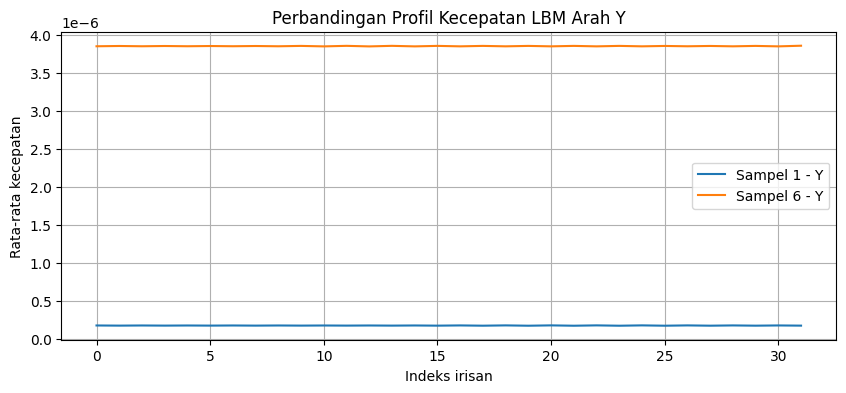

In [ ]:
# Bandingkan distribusi kecepatan arah Y
# antara sampel 1 dan sampel 6

plt.figure(figsize=(10, 4))

plt.plot(
    hasil_sampel1["Y"]["hasil"]["u"][1].mean(axis=(0, 2)),
    label="Sampel 1 - Y"
)

plt.plot(
    hasil_sampel6["Y"]["hasil"]["u"][1].mean(axis=(0, 2)),
    label="Sampel 6 - Y"
)

plt.xlabel("Indeks irisan")
plt.ylabel("Rata-rata kecepatan")
plt.title("Perbandingan Profil Kecepatan LBM Arah Y")
plt.legend()
plt.grid(True)
plt.show()

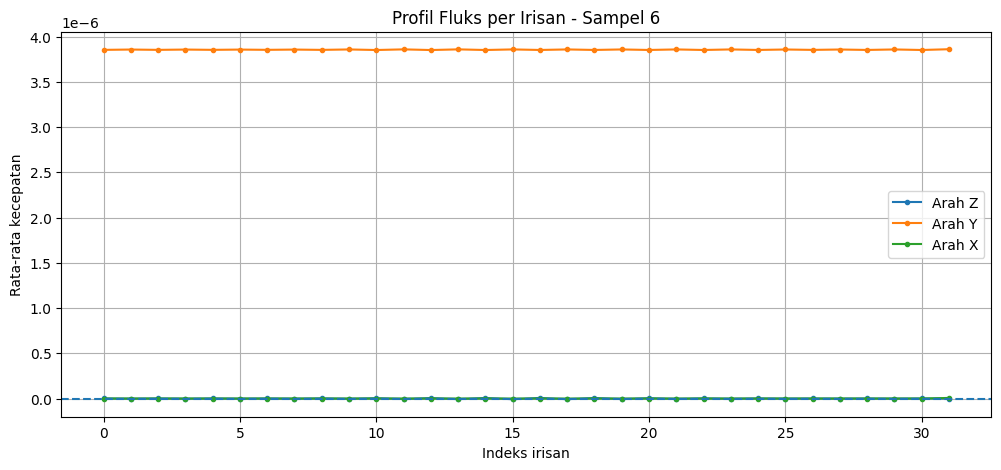

In [ ]:
# Profil fluks per irisan sampel 6

plt.figure(figsize=(12, 5))

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    hasil = hasil_sampel6[nama]["hasil"]
    kecepatan = hasil["u"][arah]

    fluks = kecepatan.mean(
        axis=tuple(a for a in range(3) if a != arah)
    )

    plt.plot(fluks, marker="o", markersize=3, label=f"Arah {nama}")

plt.axhline(0, linestyle="--")
plt.xlabel("Indeks irisan")
plt.ylabel("Rata-rata kecepatan")
plt.title("Profil Fluks per Irisan - Sampel 6")
plt.legend()
plt.grid(True)
plt.show()

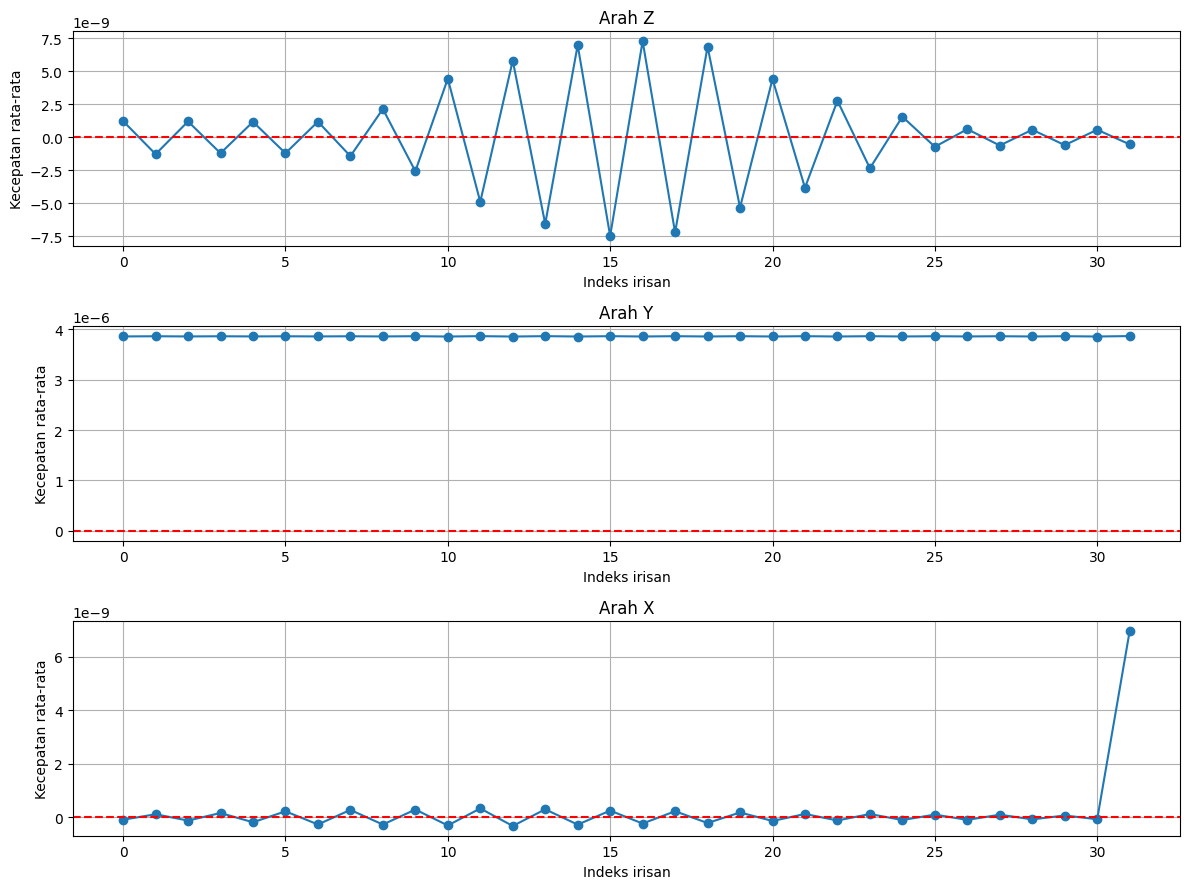

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for ax, (nama, arah) in zip(
    axes, [("Z", 0), ("Y", 1), ("X", 2)]
):
    hasil = hasil_sampel6[nama]["hasil"]
    kecepatan = hasil["u"][arah]

    fluks = kecepatan.mean(
        axis=tuple(a for a in range(3) if a != arah)
    )

    ax.plot(fluks, marker="o")
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"Arah {nama}")
    ax.set_xlabel("Indeks irisan")
    ax.set_ylabel("Kecepatan rata-rata")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Diagnosis kekuatan aliran sampel 6

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    hasil = hasil_sampel6[nama]["hasil"]
    u = hasil["u"][arah]

    rata_rata = np.mean(u)
    absolut = np.mean(np.abs(u))
    std = np.std(u)

    rasio = abs(rata_rata) / absolut if absolut > 0 else 0

    print(f"\n===== ARAH {nama} =====")
    print(f"Rata-rata kecepatan       : {rata_rata:.12e}")
    print(f"Rata-rata absolut         : {absolut:.12e}")
    print(f"Simpangan baku            : {std:.12e}")
    print(f"Rasio fluks bersih/absolut: {rasio:.6f}")


===== ARAH Z =====
Rata-rata kecepatan       : 4.304433376852e-11
Rata-rata absolut         : 3.021280866818e-09
Simpangan baku            : 6.560630290727e-09
Rasio fluks bersih/absolut: 0.014247

===== ARAH Y =====
Rata-rata kecepatan       : 3.855541874307e-06
Rata-rata absolut         : 3.856788026372e-06
Simpangan baku            : 1.239724889348e-05
Rasio fluks bersih/absolut: 0.999677

===== ARAH X =====
Rata-rata kecepatan       : 2.137988161645e-10
Rata-rata absolut         : 3.967458016883e-10
Simpangan baku            : 1.462088911065e-08
Rasio fluks bersih/absolut: 0.538881


In [ ]:
# Pemeriksaan batas periodik sampel 6 arah X dan Z

for nama, arah in [("Z", 0), ("X", 2)]:
    hasil = hasil_sampel6[nama]["hasil"]
    u = hasil["u"][arah]

    fluks = u.mean(
        axis=tuple(a for a in range(3) if a != arah)
    )

    print(f"\n===== ARAH {nama} =====")
    print("Irisan pertama :", fluks[0])
    print("Irisan kedua   :", fluks[1])
    print("Irisan terakhir:", fluks[-1])
    print("Rata-rata 5 irisan awal :", np.mean(fluks[:5]))
    print("Rata-rata 5 irisan akhir:", np.mean(fluks[-5:]))
    print("Fluks minimum:", np.min(fluks))
    print("Fluks maksimum:", np.max(fluks))


===== ARAH Z =====
Irisan pertama : 1.238290943511417e-09
Irisan kedua   : -1.2661150035653265e-09
Irisan terakhir: -5.286737621640207e-10
Rata-rata 5 irisan awal : 2.337438787377367e-10
Rata-rata 5 irisan akhir: -1.1130025505581571e-10
Fluks minimum: -7.471242947775415e-09
Fluks maksimum: 7.3042725670087785e-09

===== ARAH X =====
Irisan pertama : -9.284638382294928e-11
Irisan kedua   : 1.1057118123268422e-10
Irisan terakhir: 6.950447218466075e-09
Rata-rata 5 irisan awal : -2.751611524068218e-11
Rata-rata 5 irisan akhir: 1.3909328399749762e-09
Fluks minimum: -3.266454769400812e-10
Fluks maksimum: 6.950447218466075e-09


In [ ]:
# Pemeriksaan kontinuitas medan kecepatan sampel 6

# Mask pori tembus sampel 6
tembus6 = pori_tembus(padat_uji, arah=1)

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    hasil = hasil_sampel6[nama]["hasil"]
    u = hasil["u"]

    # Divergensi dengan pendekatan beda hingga periodik
    duz_dz = (np.roll(u[0], -1, axis=0) -
              np.roll(u[0], 1, axis=0)) / 2

    duy_dy = (np.roll(u[1], -1, axis=1) -
              np.roll(u[1], 1, axis=1)) / 2

    dux_dx = (np.roll(u[2], -1, axis=2) -
              np.roll(u[2], 1, axis=2)) / 2

    divergensi = duz_dz + duy_dy + dux_dx

    nilai = divergensi[tembus6]

    print(f"\n===== ARAH {nama} =====")
    print("Rata-rata divergensi absolut:", np.mean(np.abs(nilai)))
    print("Maksimum divergensi absolut:", np.max(np.abs(nilai)))
    print("Rata-rata divergensi:", np.mean(nilai))


===== ARAH Z =====
Rata-rata divergensi absolut: 1.554075455875877e-09
Maksimum divergensi absolut: 7.12373060304904e-09
Rata-rata divergensi: -2.419258860730584e-10

===== ARAH Y =====
Rata-rata divergensi absolut: 2.2741193293383923e-07
Maksimum divergensi absolut: 3.707820313344094e-06
Rata-rata divergensi: -4.93417004713938e-09

===== ARAH X =====
Rata-rata divergensi absolut: 8.931395865399569e-11
Maksimum divergensi absolut: 4.325744112223269e-10
Rata-rata divergensi: 3.2329891192474668e-12


In [ ]:
print("Runtime masih aktif.")
print("Numba:", ADA_NUMBA)
print("Fungsi solver:", jalankan.__name__)

Runtime masih aktif.
Numba: True
Fungsi solver: jalankan


In [ ]:
# Uji kontrol LBM

padat_kontrol = np.zeros((16, 16, 16), dtype=bool)

hasil_kontrol_ringan = {}

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    h = jalankan(
        padat_kontrol,
        tau=1.0,
        g=2e-6,
        arah=arah,
        maks=3000,
        tol=1e-6,
        periksa=100,
        catat=True
    )

    hasil_kontrol_ringan[nama] = h

    print(
        f"{nama}: k={h['k']:.10f}, "
        f"langkah={h['langkah']}, "
        f"Mach={h['Ma']:.3e}, "
        f"konvergen={bool(h['riwayat'] and h['riwayat'][-1][2] < 1e-6)}"
    )

Z: k=500.0833333340, langkah=3000, Mach=1.039e-02, konvergen=False
Y: k=500.0833333340, langkah=3000, Mach=1.039e-02, konvergen=False
X: k=500.0833333342, langkah=3000, Mach=1.039e-02, konvergen=False


In [ ]:
# Uji sensitivitas gaya pada domain homogen

h_g1 = jalankan(
    padat_kontrol,
    tau=1.0,
    g=2e-7,
    arah=0,
    maks=1000,
    tol=1e-6,
    periksa=100,
    catat=True
)

print("Permeabilitas:", h_g1["k"])
print("Kecepatan rata-rata:", h_g1["uD"])
print("Mach:", h_g1["Ma"])
print("Langkah:", h_g1["langkah"])
print("Perubahan terakhir:", h_g1["riwayat"][-1][2])

Permeabilitas: 166.7499999982562
Kecepatan rata-rata: 0.00020009999999790742
Mach: 0.0003465833665909079
Langkah: 1000
Perubahan terakhir: 0.10005002501152274


In [ ]:
# Membuat material padat dengan satu saluran lurus
# Bentuk array: (Z, Y, X)

padat_kontrol_saluran = np.ones(
    (16, 16, 16),
    dtype=bool
)

# Membuka saluran sepanjang sumbu Z
padat_kontrol_saluran[:, 5:11, 5:11] = False

print("Ukuran domain:", padat_kontrol_saluran.shape)
print("Jumlah voxel fluida:", np.count_nonzero(~padat_kontrol_saluran))
print("Jumlah voxel padat:", np.count_nonzero(padat_kontrol_saluran))

Ukuran domain: (16, 16, 16)
Jumlah voxel fluida: 576
Jumlah voxel padat: 3520


In [ ]:
# Uji LBM pada saluran lurus arah Z

hasil_kontrol_z = jalankan(
    padat_kontrol_saluran,
    tau=1.0,
    g=2e-6,
    arah=0,
    maks=10000,
    tol=1e-7,
    periksa=100,
    catat=True
)

print("Permeabilitas:", hasil_kontrol_z["k"])
print("Kecepatan rata-rata:", hasil_kontrol_z["uD"])
print("Mach:", hasil_kontrol_z["Ma"])
print("Jumlah langkah:", hasil_kontrol_z["langkah"])
print("Stabil:", not hasil_kontrol_z["meledak"])
print(
    "Perubahan relatif terakhir:",
    hasil_kontrol_z["riwayat"][-1][2]
    if hasil_kontrol_z["riwayat"] else None
)


Permeabilitas: 0.1822012304037878
Kecepatan rata-rata: 2.1864147648454538e-06
Mach: 5.2227704301172545e-05
Jumlah langkah: 300
Stabil: True
Perubahan relatif terakhir: 6.529994549702242e-09


In [ ]:
# Analisis profil aliran saluran kontrol

analisis_kontrol_z = sifat_aliran(
    hasil_kontrol_z,
    padat_kontrol_saluran,
    g=2e-6,
    arah=0
)

print("Permeabilitas rata-rata:", analisis_kontrol_z["k_vol"])
print("Permeabilitas irisan minimum:", analisis_kontrol_z["k_irisan_min"])
print("Permeabilitas irisan maksimum:", analisis_kontrol_z["k_irisan_maks"])
print("Variasi antaririsan:", analisis_kontrol_z["k_irisan_sb"])
print("Tortuositas:", analisis_kontrol_z["tau_u"])

Permeabilitas rata-rata: 0.1822012304037878
Permeabilitas irisan minimum: 0.1822012304037878
Permeabilitas irisan maksimum: 0.1822012304037878
Variasi antaririsan: 0.0
Tortuositas: 1.0000000000000682


In [ ]:
# Mengambil sampel nomor 7 untuk ukuran 32³

baris = subvolume_df[
    (subvolume_df["ukuran_voxel"] == 32) &
    (subvolume_df["nomor_sampel"] == 7)
].iloc[0]

z, y, x = int(baris["z_awal"]), int(baris["y_awal"]), int(baris["x_awal"])

sub_uji = volume[z:z+32, y:y+32, x:x+32]

print("Koordinat awal (z, y, x):", (z, y, x))
print("Ukuran subvolume:", sub_uji.shape)
print("Porositas:", np.mean(sub_uji == 0))
print("Jumlah voxel pori:", np.count_nonzero(sub_uji == 0))

Koordinat awal (z, y, x): (20, 60, 201)
Ukuran subvolume: (32, 32, 32)
Porositas: 0.269989013671875
Jumlah voxel pori: 8847


In [ ]:
# Pemeriksaan konektivitas pori sampel 7

hasil_konektivitas7 = {}

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
    padat = (sub_uji != 0)

    tembus = pori_tembus(padat, arah=arah)

    jumlah_tembus = np.count_nonzero(tembus)

    hasil_konektivitas7[nama] = tembus

    print(
        f"Arah {nama}: "
        f"{jumlah_tembus} voxel pori tembus "
        f"({jumlah_tembus / sub_uji.size * 100:.2f}%)"
    )

Arah Z: 8847 voxel pori tembus (27.00%)
Arah Y: 8847 voxel pori tembus (27.00%)
Arah X: 8847 voxel pori tembus (27.00%)


In [ ]:
# Simulasi LBM sampel 7 pada tiga arah

hasil_sampel7 = {}

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:

    print(f"\nMenjalankan simulasi arah {nama}...")

    tembus = hasil_konektivitas7[nama]
    padat_lbm = ~tembus

    h = jalankan(
        padat_lbm,
        tau=TAU,
        g=G,
        arah=arah,
        maks=400000,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    analisis = sifat_aliran(
        h,
        padat_lbm,
        g=G,
        arah=arah
    )

    k_mD = (
        analisis["k_vol"] *
        DX_UM**2 * 1e-12 /
        0.987e-15
    )

    hasil_sampel7[nama] = {
        "hasil": h,
        "analisis": analisis,
        "k_mD": k_mD
    }

    perubahan = h["riwayat"][-1][2] if h["riwayat"] else np.nan

    print("Permeabilitas:", round(k_mD, 4), "mD")
    print("Jumlah langkah:", h["langkah"])
    print("Mach:", f'{h["Ma"]:.3e}')
    print("Stabil:", not h["meledak"])
    print("Perubahan relatif:", f"{perubahan:.3e}")
    print(
        "Variasi antaririsan:",
        f'{analisis["k_irisan_sb"] * 100:.4f}%'
    )


Menjalankan simulasi arah Z...
Permeabilitas: 1163.9922 mD
Jumlah langkah: 4400
Mach: 1.303e-04
Stabil: True
Perubahan relatif: 9.293e-08
Variasi antaririsan: 0.0950%

Menjalankan simulasi arah Y...
Permeabilitas: 413.3291 mD
Jumlah langkah: 3300
Mach: 7.434e-05
Stabil: True
Perubahan relatif: 9.014e-08
Variasi antaririsan: 1.1166%

Menjalankan simulasi arah X...
Permeabilitas: 4.7596 mD
Jumlah langkah: 4500
Mach: 1.111e-05
Stabil: True
Perubahan relatif: 9.210e-08
Variasi antaririsan: 81.9938%


In [ ]:
# Diagnostik profil kecepatan aliran sampel 7

for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:

    h = hasil_sampel7[nama]["hasil"]
    kecepatan = h["u"][arah]

    if arah == 0:
        profil = kecepatan.mean(axis=(1, 2))
    elif arah == 1:
        profil = kecepatan.mean(axis=(0, 2))
    else:
        profil = kecepatan.mean(axis=(0, 1))

    print(f"\n=== ARAH {nama} ===")
    print("Rata-rata kecepatan:", profil.mean())
    print("Minimum:", profil.min())
    print("Maksimum:", profil.max())
    print("Standar deviasi:", profil.std())
    print("Irisan positif:", np.sum(profil > 0))
    print("Irisan negatif:", np.sum(profil < 0))
    print("Irisan nol:", np.sum(profil == 0))
    print("Profil:", np.round(profil, 10))


=== ARAH Z ===
Rata-rata kecepatan: 2.7232243706184634e-06
Minimum: 2.720580184700895e-06
Maksimum: 2.7346918547408257e-06
Standar deviasi: 2.5860839000742203e-09
Irisan positif: 32
Irisan negatif: 0
Irisan nol: 0
Profil: [2.7252e-06 2.7241e-06 2.7215e-06 2.7241e-06 2.7214e-06 2.7240e-06
 2.7218e-06 2.7241e-06 2.7214e-06 2.7246e-06 2.7212e-06 2.7245e-06
 2.7213e-06 2.7244e-06 2.7213e-06 2.7243e-06 2.7214e-06 2.7242e-06
 2.7213e-06 2.7243e-06 2.7212e-06 2.7244e-06 2.7211e-06 2.7243e-06
 2.7212e-06 2.7242e-06 2.7210e-06 2.7246e-06 2.7209e-06 2.7245e-06
 2.7206e-06 2.7347e-06]

=== ARAH Y ===
Rata-rata kecepatan: 9.670063774326826e-07
Minimum: 9.45103301621761e-07
Maksimum: 9.905788711172594e-07
Standar deviasi: 1.079775337896479e-08
Irisan positif: 32
Irisan negatif: 0
Irisan nol: 0
Profil: [9.906e-07 9.451e-07 9.871e-07 9.482e-07 9.840e-07 9.503e-07 9.822e-07
 9.525e-07 9.791e-07 9.557e-07 9.763e-07 9.583e-07 9.744e-07 9.595e-07
 9.734e-07 9.601e-07 9.721e-07 9.620e-07 9.707e-07 9.627e

In [ ]:
# Pemeriksaan pembatalan aliran arah X

h = hasil_sampel7["X"]["hasil"]
ux = h["u"][2]

mask_x = hasil_konektivitas7["X"]

ux_pori = ux[mask_x]

print("Rata-rata kecepatan bertanda:", ux_pori.mean())
print("Rata-rata kecepatan absolut:", np.mean(np.abs(ux_pori)))
print("Standar deviasi:", ux_pori.std())

print(
    "Rasio kecepatan bersih terhadap absolut:",
    abs(ux_pori.mean()) / np.mean(np.abs(ux_pori))
)

print(
    "Persentase kecepatan negatif:",
    np.mean(ux_pori < 0) * 100,
    "%"
)

Rata-rata kecepatan bertanda: 4.124410200937851e-08
Rata-rata kecepatan absolut: 5.7346146102899207e-08
Standar deviasi: 1.568189545403182e-07
Rasio kecepatan bersih terhadap absolut: 0.7192131435540943
Persentase kecepatan negatif: 37.481632191703405 %


In [ ]:
# Uji linearitas LBM sampel 7 arah X
# Gaya diperbesar 10 kali

hasil_x_g10 = jalankan(
    ~hasil_konektivitas7["X"],
    tau=TAU,
    g=G * 10,
    arah=2,
    maks=400000,
    tol=1e-7,
    periksa=100,
    catat=True
)

analisis_x_g10 = sifat_aliran(
    hasil_x_g10,
    ~hasil_konektivitas7["X"],
    g=G * 10,
    arah=2
)

k_x_g10_mD = (
    analisis_x_g10["k_vol"] *
    DX_UM**2 * 1e-12 /
    0.987e-15
)

print("Permeabilitas X awal:", hasil_sampel7["X"]["k_mD"], "mD")
print("Permeabilitas X dengan G x 10:", k_x_g10_mD, "mD")
print("Mach:", hasil_x_g10["Ma"])
print("Iterasi:", hasil_x_g10["langkah"])
print("Stabil:", not hasil_x_g10["meledak"])
print("Variasi antaririsan:", analisis_x_g10["k_irisan_sb"] * 100, "%")

Permeabilitas X awal: 4.759645221867816 mD
Permeabilitas X dengan G x 10: 4.758074017268324 mD
Mach: 0.00011102826820708444
Iterasi: 4500
Stabil: True
Variasi antaririsan: 82.02519906146959 %


In [ ]:
# Menentukan 6 sampel pertama untuk setiap ukuran

sampel_batch = (
    subvolume_df
    .sort_values(["ukuran_voxel", "nomor_sampel"])
    .groupby("ukuran_voxel")
    .head(6)
    .copy()
    .reset_index(drop=True)
)

print("Jumlah sampel:", len(sampel_batch))
print("\nDaftar sampel yang akan disimulasikan:")

display(
    sampel_batch[
        [
            "ukuran_voxel",
            "nomor_sampel",
            "z_awal",
            "y_awal",
            "x_awal",
            "porositas"
        ]
    ]
)

NameError: name 'subvolume_df' is not defined

In [ ]:

import os
import gc
import time
import numpy as np
import pandas as pd

# ==========================================
# KONFIGURASI BATCH LBM
# ==========================================

FILE_HASIL = "hasil_batch_lbm_kirby.csv"

ARAH = [
    ("Z", 0),
    ("Y", 1),
    ("X", 2)
]

TOL = 1e-7
MAKS_ITERASI = 400000
GAYA = G
TAU_LBM = TAU

# Mulai dari file hasil kosong
hasil_batch = []

# Validasi daftar sampel
assert len(sampel_batch) == 30
assert set(sampel_batch["ukuran_voxel"]) == {32, 48, 64, 96, 128}

print("Konfigurasi batch berhasil diperiksa.")
print("Jumlah sampel:", len(sampel_batch))
print("Jumlah arah maksimum:", len(sampel_batch) * 3)
print("File checkpoint:", FILE_HASIL)


# ==========================================
# PROSES SIMULASI OTOMATIS
# ==========================================

waktu_mulai = time.time()

for indeks, baris in sampel_batch.iterrows():

    L = int(baris["ukuran_voxel"])
    nomor = int(baris["nomor_sampel"])

    z = int(baris["z_awal"])
    y = int(baris["y_awal"])
    x = int(baris["x_awal"])

    print("\n" + "=" * 55)
    print(f"SAMPEL {nomor} | UKURAN {L}³")
    print(f"Koordinat: Z={z}, Y={y}, X={x}")
    print("=" * 55)

    # Ekstraksi subvolume
    sub = volume[z:z+L, y:y+L, x:x+L]

    assert sub.shape == (L, L, L)

    porositas = np.mean(sub == 0)

    # Material padat = True
    padat = (sub != 0)

    for nama, arah in ARAH:

        print(f"\nMemproses arah {nama}...")

        awal = time.time()

        try:

            # Identifikasi pori yang menembus domain
            tembus = pori_tembus(
                padat,
                arah=arah
            )

            jumlah_tembus = int(np.count_nonzero(tembus))

            # Data dasar
            data = {
                "ukuran_voxel": L,
                "ukuran_fisik_um": L * DX_UM,
                "nomor_sampel": nomor,
                "z_awal": z,
                "y_awal": y,
                "x_awal": x,
                "porositas": porositas,
                "arah": nama,
                "jumlah_pori_tembus": jumlah_tembus,
                "fraksi_pori_tembus": jumlah_tembus / sub.size,
                "k_mD": np.nan,
                "langkah": np.nan,
                "Mach": np.nan,
                "konvergen": False,
                "stabil": False,
                "variasi_irisan": np.nan,
                "tortuositas": np.nan,
                "status": None,
                "waktu_detik": np.nan
            }

            # Tidak menjalankan LBM jika tidak percolating
            if jumlah_tembus == 0:

                data["status"] = "Non-percolating"

            else:

                # Hanya pori tembus yang menjadi fluida
                padat_lbm = ~tembus

                # Simulasi LBM
                h = jalankan(
                    padat_lbm,
                    tau=TAU_LBM,
                    g=GAYA,
                    arah=arah,
                    maks=MAKS_ITERASI,
                    tol=TOL,
                    periksa=100,
                    catat=True
                )

                # Analisis aliran
                analisis = sifat_aliran(
                    h,
                    padat_lbm,
                    g=GAYA,
                    arah=arah
                )

                # Konversi permeabilitas ke mD
                k_mD = (
                    analisis["k_vol"]
                    * DX_UM**2
                    * 1e-12
                    / 0.987e-15
                )

                perubahan = (
                    h["riwayat"][-1][2]
                    if h["riwayat"]
                    else np.nan
                )

                konvergen = (
                    np.isfinite(perubahan)
                    and perubahan < TOL
                )

                stabil = not h["meledak"]

                mach = h["Ma"]

                variasi = analisis["k_irisan_sb"]

                # Simpan semua parameter penting
                data.update({
                    "k_mD": k_mD,
                    "langkah": h["langkah"],
                    "Mach": mach,
                    "konvergen": konvergen,
                    "stabil": stabil,
                    "variasi_irisan": variasi,
                    "tortuositas": analisis["tau_u"]
                })

                # Klasifikasi kualitas
                if not stabil:
                    data["status"] = "Tidak stabil"

                elif not konvergen:
                    data["status"] = "Belum konvergen"

                elif mach >= 0.01:
                    data["status"] = "Mach tidak memenuhi"

                elif not np.isfinite(variasi):
                    data["status"] = "Diagnostik tidak valid"

                elif variasi >= 1e-3:
                    data["status"] = "Variasi irisan tinggi"

                else:
                    data["status"] = "Lolos pemeriksaan"

                # Bersihkan array simulasi besar
                del h, analisis, padat_lbm

            data["waktu_detik"] = time.time() - awal

        except Exception as e:

            data["status"] = "Error: " + str(e)
            data["waktu_detik"] = time.time() - awal

        # Tambahkan hasil ke daftar
        hasil_batch.append(data)

        # Simpan checkpoint setiap arah
        pd.DataFrame(hasil_batch).to_csv(
            FILE_HASIL,
            index=False
        )

        print("Status:", data["status"])
        print("Permeabilitas:", data["k_mD"], "mD")
        print("Waktu:", round(data["waktu_detik"], 1), "detik")

        # Membersihkan memori
        del tembus
        gc.collect()

    del sub, padat
    gc.collect()

    print("\nSampel selesai:", nomor, "| Ukuran:", L)

# ==========================================
# RINGKASAN AKHIR
# ==========================================

df_hasil_batch = pd.DataFrame(hasil_batch)

df_hasil_batch.to_csv(
    FILE_HASIL,
    index=False
)

print("\n" + "=" * 55)
print("BATCH LBM SELESAI")
print("=" * 55)

print("Jumlah simulasi tercatat:", len(df_hasil_batch))
print("Total waktu:", round(time.time() - waktu_mulai, 1), "detik")

display(
    df_hasil_batch.groupby(
        ["ukuran_voxel", "status"]
    ).size().unstack(fill_value=0)
)

print("\nFile hasil:", FILE_HASIL)


Konfigurasi batch berhasil diperiksa.
Jumlah sampel: 30
Jumlah arah maksimum: 90
File checkpoint: hasil_batch_lbm_kirby.csv

SAMPEL 1 | UKURAN 32³
Koordinat: Z=94, Y=206, X=121

Memproses arah Z...
Status: Variasi irisan tinggi
Permeabilitas: 47.36955635803282 mD
Waktu: 21.8 detik

Memproses arah Y...
Status: Variasi irisan tinggi
Permeabilitas: 74.43963307148707 mD
Waktu: 19.1 detik

Memproses arah X...
Status: Lolos pemeriksaan
Permeabilitas: 2781.3108336623595 mD
Waktu: 6.3 detik

Sampel selesai: 1 | Ukuran: 32

SAMPEL 2 | UKURAN 32³
Koordinat: Z=42, Y=127, X=211

Memproses arah Z...
Status: Variasi irisan tinggi
Permeabilitas: 21.64560668381799 mD
Waktu: 2.6 detik

Memproses arah Y...
Status: Variasi irisan tinggi
Permeabilitas: 87.54441487901148 mD
Waktu: 0.6 detik

Memproses arah X...
Status: Non-percolating
Permeabilitas: nan mD
Waktu: 0.0 detik

Sampel selesai: 2 | Ukuran: 32

SAMPEL 3 | UKURAN 32³
Koordinat: Z=116, Y=31, X=91

Memproses arah Z...
Status: Non-percolating
Permea

KeyboardInterrupt: 

In [ ]:
# Pemeriksaan kondisi runtime Colab

variabel_penting = [
    "volume",
    "subvolume_df",
    "sampel_batch",
    "jalankan",
    "pori_tembus",
    "sifat_aliran",
    "TAU",
    "G",
    "DX_UM"
]

for nama in variabel_penting:
    tersedia = nama in globals()
    print(f"{nama}: {'TERSEDIA' if tersedia else 'TIDAK TERSEDIA'}")

print("\nUkuran volume:", volume.shape if "volume" in globals() else "Belum tersedia")
print("Numba aktif:", "numba" in globals())

volume: TERSEDIA
subvolume_df: TERSEDIA
sampel_batch: TERSEDIA
jalankan: TERSEDIA
pori_tembus: TERSEDIA
sifat_aliran: TERSEDIA
TAU: TERSEDIA
G: TERSEDIA
DX_UM: TERSEDIA

Ukuran volume: (256, 256, 256)
Numba aktif: True


In [ ]:
import os
import pandas as pd

FILE_HASIL = "hasil_batch_lbm_kirby.csv"

if os.path.exists(FILE_HASIL):
    checkpoint = pd.read_csv(FILE_HASIL)

    print("Checkpoint ditemukan.")
    print("Jumlah hasil tersimpan:", len(checkpoint))

    print("\nProgres per ukuran:")
    print(
        checkpoint.groupby("ukuran_voxel")
        .size()
    )

    print("\nTiga hasil terakhir:")
    display(checkpoint.tail(3))

else:
    print("Checkpoint belum ditemukan di runtime Colab.")
    print("Kita perlu mengunggah CSV checkpoint dari laptop.")

Checkpoint ditemukan.
Jumlah hasil tersimpan: 54

Progres per ukuran:
ukuran_voxel
32    18
48    18
64    18
dtype: int64

Tiga hasil terakhir:


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah,jumlah_pori_tembus,fraksi_pori_tembus,k_mD,langkah,Mach,konvergen,stabil,variasi_irisan,tortuositas,status,waktu_detik
51,64,144.0,6,40,187,40,0.280102,Z,73406,0.280022,251.328317,11700.0,0.000151,True,True,0.001841,1.715357,Variasi irisan tinggi,344.429698
52,64,144.0,6,40,187,40,0.280102,Y,73406,0.280022,457.943062,7100.0,0.000238,True,True,0.000801,1.504489,Lolos pemeriksaan,209.977144
53,64,144.0,6,40,187,40,0.280102,X,73406,0.280022,169.781302,5800.0,0.000126,True,True,0.002074,1.848382,Variasi irisan tinggi,171.003841


In [ ]:
# Membuat daftar kombinasi simulasi yang belum selesai

arah_batch = ["Z", "Y", "X"]

selesai = set(
    zip(
        checkpoint["ukuran_voxel"].astype(int),
        checkpoint["nomor_sampel"].astype(int),
        checkpoint["arah"].astype(str)
    )
)

pekerjaan_tersisa = []

for _, baris in sampel_batch.iterrows():

    L = int(baris["ukuran_voxel"])
    nomor = int(baris["nomor_sampel"])

    for arah in arah_batch:

        kombinasi = (L, nomor, arah)

        if kombinasi not in selesai:
            pekerjaan_tersisa.append(kombinasi)

print("Jumlah simulasi sudah tercatat:", len(selesai))
print("Jumlah simulasi tersisa:", len(pekerjaan_tersisa))

print("\nDaftar pekerjaan tersisa:")

for item in pekerjaan_tersisa:
    print(
        f"Ukuran {item[0]}³ | "
        f"Sampel {item[1]} | "
        f"Arah {item[2]}"
    )

Jumlah simulasi sudah tercatat: 54
Jumlah simulasi tersisa: 36

Daftar pekerjaan tersisa:
Ukuran 96³ | Sampel 1 | Arah Z
Ukuran 96³ | Sampel 1 | Arah Y
Ukuran 96³ | Sampel 1 | Arah X
Ukuran 96³ | Sampel 2 | Arah Z
Ukuran 96³ | Sampel 2 | Arah Y
Ukuran 96³ | Sampel 2 | Arah X
Ukuran 96³ | Sampel 3 | Arah Z
Ukuran 96³ | Sampel 3 | Arah Y
Ukuran 96³ | Sampel 3 | Arah X
Ukuran 96³ | Sampel 4 | Arah Z
Ukuran 96³ | Sampel 4 | Arah Y
Ukuran 96³ | Sampel 4 | Arah X
Ukuran 96³ | Sampel 5 | Arah Z
Ukuran 96³ | Sampel 5 | Arah Y
Ukuran 96³ | Sampel 5 | Arah X
Ukuran 96³ | Sampel 6 | Arah Z
Ukuran 96³ | Sampel 6 | Arah Y
Ukuran 96³ | Sampel 6 | Arah X
Ukuran 128³ | Sampel 1 | Arah Z
Ukuran 128³ | Sampel 1 | Arah Y
Ukuran 128³ | Sampel 1 | Arah X
Ukuran 128³ | Sampel 2 | Arah Z
Ukuran 128³ | Sampel 2 | Arah Y
Ukuran 128³ | Sampel 2 | Arah X
Ukuran 128³ | Sampel 3 | Arah Z
Ukuran 128³ | Sampel 3 | Arah Y
Ukuran 128³ | Sampel 3 | Arah X
Ukuran 128³ | Sampel 4 | Arah Z
Ukuran 128³ | Sampel 4 | Arah Y


In [ ]:

import os
import gc
import time
import numpy as np
import pandas as pd

FILE_HASIL = "hasil_batch_lbm_kirby.csv"

# Membaca checkpoint terbaru
checkpoint = pd.read_csv(FILE_HASIL)

def kombinasi_selesai(df):
    return set(zip(
        df["ukuran_voxel"].astype(int),
        df["nomor_sampel"].astype(int),
        df["arah"].astype(str)
    ))

selesai = kombinasi_selesai(checkpoint)

# Hanya mengambil pekerjaan yang belum tersimpan
pekerjaan_tersisa = []

for _, b in sampel_batch.iterrows():
    L = int(b["ukuran_voxel"])
    nomor = int(b["nomor_sampel"])

    for nama, arah in [("Z", 0), ("Y", 1), ("X", 2)]:
        if (L, nomor, nama) not in selesai:
            pekerjaan_tersisa.append((b, nama, arah))

print("Simulasi tersisa:", len(pekerjaan_tersisa))

# Jalankan satu per satu
for urutan, (b, nama, arah) in enumerate(pekerjaan_tersisa, 1):

    L = int(b["ukuran_voxel"])
    nomor = int(b["nomor_sampel"])

    z = int(b["z_awal"])
    y = int(b["y_awal"])
    x = int(b["x_awal"])

    print("\n" + "=" * 55)
    print(f"PROGRES {urutan}/{len(pekerjaan_tersisa)}")
    print(f"Ukuran {L}³ | Sampel {nomor} | Arah {nama}")
    print("=" * 55)

    awal = time.time()

    data = {
        "ukuran_voxel": L,
        "ukuran_fisik_um": L * DX_UM,
        "nomor_sampel": nomor,
        "z_awal": z,
        "y_awal": y,
        "x_awal": x,
        "porositas": float(b["porositas"]),
        "arah": nama,
        "jumlah_pori_tembus": 0,
        "fraksi_pori_tembus": 0.0,
        "k_mD": np.nan,
        "langkah": np.nan,
        "Mach": np.nan,
        "konvergen": False,
        "stabil": False,
        "variasi_irisan": np.nan,
        "tortuositas": np.nan,
        "status": None,
        "waktu_detik": np.nan
    }

    try:
        # Ekstraksi subvolume
        sub = volume[z:z+L, y:y+L, x:x+L]
        assert sub.shape == (L, L, L)

        padat = (sub != 0)

        # Konektivitas
        tembus = pori_tembus(padat, arah=arah)
        jumlah = int(np.count_nonzero(tembus))

        data["jumlah_pori_tembus"] = jumlah
        data["fraksi_pori_tembus"] = jumlah / sub.size

        if jumlah == 0:
            data["status"] = "Non-percolating"

        else:
            padat_lbm = ~tembus

            h = jalankan(
                padat_lbm,
                tau=TAU,
                g=G,
                arah=arah,
                maks=400000,
                tol=1e-7,
                periksa=100,
                catat=True
            )

            a = sifat_aliran(
                h,
                padat_lbm,
                g=G,
                arah=arah
            )

            perubahan = (
                h["riwayat"][-1][2]
                if h["riwayat"] else np.nan
            )

            konvergen = (
                np.isfinite(perubahan)
                and perubahan < 1e-7
            )

            stabil = not h["meledak"]

            k_mD = (
                a["k_vol"] * DX_UM**2 * 1e-12
                / 0.987e-15
            )

            variasi = a["k_irisan_sb"]

            data.update({
                "k_mD": k_mD,
                "langkah": h["langkah"],
                "Mach": h["Ma"],
                "konvergen": konvergen,
                "stabil": stabil,
                "variasi_irisan": variasi,
                "tortuositas": a["tau_u"]
            })

            if not stabil:
                status = "Tidak stabil"
            elif not konvergen:
                status = "Belum konvergen"
            elif h["Ma"] >= 0.01:
                status = "Mach tidak memenuhi"
            elif not np.isfinite(variasi):
                status = "Diagnostik tidak valid"
            elif variasi >= 1e-3:
                status = "Variasi irisan tinggi"
            else:
                status = "Lolos pemeriksaan"

            data["status"] = status

            del h, a, padat_lbm

        del sub, padat, tembus

    except Exception as e:
        data["status"] = "Error: " + str(e)
        print("Terjadi error:", str(e))

    data["waktu_detik"] = time.time() - awal

    # Tambahkan hasil dan simpan checkpoint
    checkpoint = pd.concat(
        [checkpoint, pd.DataFrame([data])],
        ignore_index=True
    )

    checkpoint.to_csv(FILE_HASIL, index=False)

    print("Status:", data["status"])
    print("k:", data["k_mD"], "mD")
    print("Waktu:", round(data["waktu_detik"], 1), "detik")
    print("Checkpoint berhasil diperbarui.")

    gc.collect()

print("\nBATCH RESUME SELESAI")
print("Total hasil:", len(checkpoint))
print("File:", FILE_HASIL)

display(
    checkpoint.groupby(
        ["ukuran_voxel", "status"]
    ).size().unstack(fill_value=0)
)


Simulasi tersisa: 36

PROGRES 1/36
Ukuran 96³ | Sampel 1 | Arah Z
Status: Variasi irisan tinggi
k: 128.23220226854335 mD
Waktu: 3089.8 detik
Checkpoint berhasil diperbarui.

PROGRES 2/36
Ukuran 96³ | Sampel 1 | Arah Y


In [ ]:
import sys
import os

print("Python:", sys.version)
print("Folder kerja:", os.getcwd())

try:
    import numpy as np
    import pandas as pd
    import numba

    print("NumPy:", np.__version__)
    print("Pandas:", pd.__version__)
    print("Numba:", numba.__version__)
    print("Numba aktif:", True)

except Exception as e:
    print("Terjadi error:", e)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Folder kerja: /content
NumPy: 2.4.6
Pandas: 2.2.3
Numba: 0.64.0
Numba aktif: True


In [ ]:
import os

print("File di folder /content:")
for nama in os.listdir("/content"):
    print("-", nama)

File di folder /content:
- .config
- sample_data


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Kirby_2d25um_binary_256.raw to Kirby_2d25um_binary_256.raw


In [ ]:
import numpy as np
import os

nama_file = "/content/Kirby_2d25um_binary_256.raw"

# Periksa ukuran file
ukuran_file = os.path.getsize(nama_file)
assert ukuran_file == 256**3, "Ukuran file tidak sesuai!"

# Baca dan bentuk ulang volume 3D
volume = np.fromfile(nama_file, dtype=np.uint8)
volume = volume.reshape((256, 256, 256), order="C")

# Validasi data
print("Bentuk volume:", volume.shape)
print("Tipe data:", volume.dtype)
print("Jumlah voxel pori (0):", np.count_nonzero(volume == 0))
print("Jumlah voxel solid (1):", np.count_nonzero(volume == 1))
print("Porositas total:", np.mean(volume == 0))

Bentuk volume: (256, 256, 256)
Tipe data: uint8
Jumlah voxel pori (0): 3444096
Jumlah voxel solid (1): 13333120
Porositas total: 0.20528411865234375


In [ ]:
from google.colab import files

uploaded_checkpoint = files.upload()

Saving hasil_batch_lbm_kirby (5).csv to hasil_batch_lbm_kirby (5).csv


In [ ]:
import pandas as pd

file_checkpoint = "/content/hasil_batch_lbm_kirby (5).csv"

rekap_lbm = pd.read_csv(file_checkpoint)

print("Jumlah hasil tersimpan:", len(rekap_lbm))
print("\nJumlah hasil per ukuran:")
print(rekap_lbm.groupby("ukuran_voxel").size())

print("\nLima baris terakhir:")
display(rekap_lbm.tail())

Jumlah hasil tersimpan: 54

Jumlah hasil per ukuran:
ukuran_voxel
32    18
48    18
64    18
dtype: int64

Lima baris terakhir:


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah,jumlah_pori_tembus,fraksi_pori_tembus,k_mD,langkah,Mach,konvergen,stabil,variasi_irisan,tortuositas,status,waktu_detik
49,64,144.0,5,160,95,128,0.161743,Y,41600,0.158691,145.931493,18400.0,0.000086,True,True,0.002336,1.977835,Variasi irisan tinggi,270.817817
50,64,144.0,5,160,95,128,0.161743,X,41600,0.158691,99.847949,17000.0,0.000113,True,True,0.001781,1.607329,Variasi irisan tinggi,249.989282
51,64,144.0,6,40,187,40,0.280102,Z,73406,0.280022,251.328317,11700.0,0.000151,True,True,0.001841,1.715357,Variasi irisan tinggi,344.429698
52,64,144.0,6,40,187,40,0.280102,Y,73406,0.280022,457.943062,7100.0,0.000238,True,True,0.000801,1.504489,Lolos pemeriksaan,209.977144
53,64,144.0,6,40,187,40,0.280102,X,73406,0.280022,169.781302,5800.0,0.000126,True,True,0.002074,1.848382,Variasi irisan tinggi,171.003841


In [ ]:
import shutil
import os

shutil.copy(
    "/content/hasil_batch_lbm_kirby (5).csv",
    "/content/checkpoint_lbm_kirby.csv"
)

print("Checkpoint aman:", os.path.exists("/content/checkpoint_lbm_kirby.csv"))
print("Jumlah baris:", len(rekap_lbm))

Checkpoint aman: True
Jumlah baris: 54


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from scipy import ndimage as ndi
from scipy import sparse
from scipy.sparse import csgraph
from scipy.sparse.linalg import cg

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False
})

DARCY = 0.987e-12

def judul(t):
    print("\n" + "=" * 74)
    print(t)
    print("=" * 74)

def kisi(nama):
    if nama == "D2Q9":
        c = np.array([
            [0,0], [1,0], [0,1], [-1,0], [0,-1],
            [1,1], [-1,1], [-1,-1], [1,-1]
        ])
        w = np.array([4/9] + [1/9]*4 + [1/36]*4)

    elif nama == "D3Q19":
        c = [[0,0,0]]
        for a in range(3):
            for s in (1,-1):
                v = [0,0,0]
                v[a] = s
                c.append(v)

        for a in range(3):
            for b in range(a+1,3):
                for s1 in (1,-1):
                    for s2 in (1,-1):
                        v = [0,0,0]
                        v[a] = s1
                        v[b] = s2
                        c.append(v)

        c = np.array(c)
        w = np.array([1/3] + [1/18]*6 + [1/36]*12)

    else:
        raise ValueError(nama)

    opp = np.array([
        np.where((c == -ci).all(1))[0][0] for ci in c
    ])

    return c, w, opp

try:
    import numba as nb
    ADA_NUMBA = True
except ImportError:
    ADA_NUMBA = False

print("Numba tersedia:", ADA_NUMBA)
print("Jumlah arah kisi D3Q19:", len(kisi("D3Q19")[1]))
print("Konstanta Darcy:", DARCY)

Numba tersedia: True
Jumlah arah kisi D3Q19: 19
Konstanta Darcy: 9.87e-13


In [34]:
@nb.njit
def _langkah(f, fb, nbr, c, w, opp, F, wp, wm, u, rho):
    Q, n = f.shape
    D = c.shape[1]

    for j in range(n):
        r = 0.0
        for i in range(Q):
            r += f[i, j]

        for a in range(D):
            m = 0.0
            for i in range(Q):
                m += c[i, a] * f[i, j]
            u[a, j] = (m + 0.5 * F[a]) / r

        rho[j] = r
        uu = 0.0
        uF = 0.0

        for a in range(D):
            uu += u[a, j] * u[a, j]
            uF += F[a] * u[a, j]

        for i in range(Q):
            if opp[i] < i:
                continue

            o = opp[i]
            cu = 0.0
            cF = 0.0

            for a in range(D):
                cu += c[i, a] * u[a, j]
                cF += c[i, a] * F[a]

            ei = w[i] * r * (1 + 3*cu + 4.5*cu*cu - 1.5*uu)
            eo = w[o] * r * (1 - 3*cu + 4.5*cu*cu - 1.5*uu)

            fp = 0.5 * (f[i, j] + f[o, j])
            fm = 0.5 * (f[i, j] - f[o, j])
            ep = 0.5 * (ei + eo)
            em = 0.5 * (ei - eo)

            Sg = w[i] * (-3*uF + 9*cu*cF)
            Sa = w[i] * 3*cF

            gp = -wp*(fp - ep) + (1 - 0.5*wp)*Sg
            gm = -wm*(fm - em) + (1 - 0.5*wm)*Sa

            if i == o:
                fb[i, j] = f[i, j] + gp + gm
            else:
                fb[i, j] = f[i, j] + gp + gm
                fb[o, j] = f[o, j] + gp - gm

    for i in range(Q):
        for j in range(n):
            s = nbr[i, j]
            if s >= 0:
                f[i, j] = fb[i, s]
            else:
                f[i, j] = fb[opp[i], j]


def jalankan(
    padat, tau, g=1e-5, arah=0, maks=400000,
    tol=1e-7, periksa=100, catat=False,
    operator="TRT", lam=3/16, cetak=False, **_
):
    D = padat.ndim
    nama = "D2Q9" if D == 2 else "D3Q19"

    c, w, opp = kisi(nama)
    Q = len(w)
    nu = (tau - 0.5) / 3.0
    sh = padat.shape

    alir = ~padat
    idx = -np.ones(sh, np.int64)
    idx[alir] = np.arange(alir.sum())
    n = int(alir.sum())

    nbr = np.empty((Q, n), np.int64)

    for i in range(Q):
        sumber = np.roll(
            idx,
            shift=tuple(c[i]),
            axis=tuple(range(D))
        )
        nbr[i] = sumber[alir]

    F = np.zeros(D)
    F[arah] = g

    if operator == "BGK":
        wp = wm = 1.0 / tau
    else:
        wp = 1.0 / tau
        wm = 1.0 / (0.5 + lam / (tau - 0.5))

    f = np.repeat(w[:, None], n, 1).astype(np.float64)
    fb = np.empty_like(f)
    u = np.zeros((D, n))
    rho = np.ones(n)
    cf = c.astype(np.float64)

    riwayat = []
    ux_lama = 0.0
    N = padat.size

    for k in range(1, maks + 1):
        _langkah(f, fb, nbr, cf, w, opp, F, wp, wm, u, rho)

        if k % periksa == 0:
            ux = u[arah].sum() / N
            ubah = abs(ux - ux_lama) / max(abs(ux), 1e-30)

            if catat:
                riwayat.append((k, ux, ubah))

            ux_lama = ux

            if not np.isfinite(ux) or ubah < tol:
                break

    rho = f.sum(0)
    uf = (cf.T @ f + 0.5 * F[:, None]) / rho

    U = np.zeros((D,) + sh)
    R = np.ones(sh)

    for a in range(D):
        U[a][alir] = uf[a]

    R[alir] = rho

    uD = U[arah].mean()
    kk = nu * uD / g
    umaks = np.sqrt((U ** 2).sum(0)).max()

    return dict(
        u=U,
        rho=R,
        k=kk,
        uD=uD,
        langkah=k,
        riwayat=riwayat,
        nu=nu,
        umaks=umaks,
        Ma=umaks * np.sqrt(3),
        meledak=not np.isfinite(kk)
    )


print("Fungsi solver LBM berhasil dimuat.")

Fungsi solver LBM berhasil dimuat.


In [35]:
def label_periodik(pori, sumbu=None):
    lab, n = ndi.label(pori)

    induk = list(range(n + 1))

    def akar(a):
        while induk[a] != a:
            induk[a] = induk[induk[a]]
            a = induk[a]
        return a

    for ax in (range(pori.ndim) if sumbu is None else sumbu):
        a = np.take(lab, 0, axis=ax)
        b = np.take(lab, -1, axis=ax)

        m = (a > 0) & (b > 0)

        for p, q in set(zip(a[m].tolist(), b[m].tolist())):
            ra, rb = akar(p), akar(q)
            if ra != rb:
                induk[ra] = rb

    peta = np.array([akar(i) for i in range(n + 1)])
    return peta[lab]


def pori_tembus(padat, arah=0):
    pori = ~padat

    lab = label_periodik(pori)

    lab2 = label_periodik(
        pori,
        [a for a in range(pori.ndim) if a != arah]
    )

    a = set(np.unique(np.take(lab2, 0, axis=arah))) - {0}
    b = set(np.unique(np.take(lab2, -1, axis=arah))) - {0}

    tembus2 = np.isin(lab2, list(a & b))
    kel = set(np.unique(lab[tembus2])) - {0}

    return np.isin(lab, list(kel))


def sifat_aliran(hasil, padat, g, arah=0):
    u = hasil["u"]
    nu = hasil["nu"]
    pori = ~padat

    ux = u[arah]

    k_vol = nu * ux.mean() / g

    sumbu = tuple(
        a for a in range(padat.ndim) if a != arah
    )

    k_irisan = nu * ux.mean(axis=sumbu) / g

    besar = np.sqrt((u ** 2).sum(0))
    tau_u = besar[pori].sum() / ux[pori].sum()

    return dict(
        k_vol=float(k_vol),
        k_irisan_min=float(k_irisan.min()),
        k_irisan_maks=float(k_irisan.max()),
        k_irisan_sb=float(k_irisan.std() / k_irisan.mean()),
        tau_u=float(tau_u)
    )


print("Fungsi konektivitas:", callable(pori_tembus))
print("Fungsi analisis aliran:", callable(sifat_aliran))
print("Solver LBM:", callable(jalankan))

Fungsi konektivitas: True
Fungsi analisis aliran: True
Solver LBM: True


In [ ]:
# Parameter LBM dari simulasi sebelumnya
TAU = 1.0
G = 2e-6
DARCY = 0.987e-12
DX_UM = 2.25

# Ukuran subvolume yang dianalisis
UKURAN_SISI = [32, 48, 64, 96, 128]

# Periksa isi checkpoint
print("Parameter:")
print("TAU =", TAU)
print("G =", G)
print("DX =", DX_UM, "µm")

print("\nJumlah hasil checkpoint:")
print(rekap_lbm.groupby("ukuran_voxel").size())

print("\nStatus hasil yang sudah tersimpan:")
print(rekap_lbm["status"].value_counts())

print("\nKolom checkpoint:")
print(rekap_lbm.columns.tolist())

Parameter:
TAU = 1.0
G = 2e-06
DX = 2.25 µm

Jumlah hasil checkpoint:
ukuran_voxel
32    18
48    18
64    18
dtype: int64

Status hasil yang sudah tersimpan:
status
Variasi irisan tinggi    35
Non-percolating          10
Lolos pemeriksaan         9
Name: count, dtype: int64

Kolom checkpoint:
['ukuran_voxel', 'ukuran_fisik_um', 'nomor_sampel', 'z_awal', 'y_awal', 'x_awal', 'porositas', 'arah', 'jumlah_pori_tembus', 'fraksi_pori_tembus', 'k_mD', 'langkah', 'Mach', 'konvergen', 'stabil', 'variasi_irisan', 'tortuositas', 'status', 'waktu_detik']


In [ ]:
DX_UM = 2.25

In [ ]:
kolom = [
    "ukuran_voxel",
    "nomor_sampel",
    "z_awal",
    "y_awal",
    "x_awal",
    "porositas"
]

sampel_batch = pd.DataFrame(data_sampel, columns=kolom)

sampel_batch["ukuran_fisik_um"] = (
    sampel_batch["ukuran_voxel"] * DX_UM
)

print("Jumlah sampel:", len(sampel_batch))
print("\nJumlah per ukuran:")
print(sampel_batch.groupby("ukuran_voxel").size())

Jumlah sampel: 30

Jumlah per ukuran:
ukuran_voxel
32     6
48     6
64     6
96     6
128    6
dtype: int64


In [ ]:
data_sampel = [
    # Ukuran 32
    [32,1,94,206,121,0.289886],
    [32,2,42,127,211,0.069336],
    [32,3,116,31,91,0.174713],
    [32,4,178,72,186,0.055450],
    [32,5,14,186,54,0.199371],
    [32,6,97,90,189,0.212128],

    # Ukuran 48
    [48,1,65,192,80,0.360225],
    [48,2,170,33,61,0.149984],
    [48,3,1,172,204,0.074888],
    [48,4,11,167,90,0.104519],
    [48,5,161,51,151,0.270761],
    [48,6,32,144,177,0.190095],

    # Ukuran 64
    [64,1,12,4,123,0.199120],
    [64,2,56,137,25,0.175804],
    [64,3,155,123,13,0.195000],
    [64,4,116,149,132,0.139099],
    [64,5,160,95,128,0.161743],
    [64,6,40,187,40,0.280102],

    # Ukuran 96
    [96,1,130,26,45,0.208654],
    [96,2,135,75,36,0.214381],
    [96,3,135,104,120,0.184973],
    [96,4,106,129,85,0.220457],
    [96,5,38,45,47,0.206906],
    [96,6,113,31,27,0.209394],

    # Ukuran 128
    [128,1,64,53,110,0.206907],
    [128,2,110,115,0,0.237433],
    [128,3,38,70,110,0.211396],
    [128,4,25,24,114,0.219217],
    [128,5,30,108,1,0.219060],
    [128,6,33,75,101,0.213523],
]

sampel_batch = pd.DataFrame(
    data_sampel,
    columns=[
        "ukuran_voxel",
        "nomor_sampel",
        "z_awal",
        "y_awal",
        "x_awal",
        "porositas"
    ]
)

sampel_batch["ukuran_fisik_um"] = sampel_batch["ukuran_voxel"] * DX_UM

print("Jumlah sampel:", len(sampel_batch))
print("\nJumlah sampel per ukuran:")
print(sampel_batch.groupby("ukuran_voxel").size())

display(sampel_batch)

NameError: name 'DX_UM' is not defined

In [ ]:
# Setiap kombinasi sampel dan arah hanya boleh muncul satu kali
kunci = [
    "ukuran_voxel",
    "nomor_sampel",
    "arah"
]

# Periksa duplikasi di checkpoint
duplikat = rekap_lbm.duplicated(subset=kunci).sum()

# Buat seluruh kombinasi yang seharusnya disimulasikan
daftar_arah = pd.DataFrame({"arah": ["Z", "Y", "X"]})

target = sampel_batch.merge(daftar_arah, how="cross")

# Cocokkan dengan hasil yang sudah tersimpan
pemeriksaan = target.merge(
    rekap_lbm[kunci],
    on=kunci,
    how="left",
    indicator=True
)

sudah_ada = pemeriksaan["_merge"] == "both"
belum_ada = pemeriksaan["_merge"] == "left_only"

print("Total target simulasi:", len(target))
print("Simulasi sudah tersimpan:", sudah_ada.sum())
print("Simulasi belum tersimpan:", belum_ada.sum())
print("Duplikasi dalam checkpoint:", duplikat)

print("\nSimulasi yang belum tersimpan:")
display(
    pemeriksaan.loc[
        belum_ada,
        ["ukuran_voxel", "nomor_sampel", "arah"]
    ].reset_index(drop=True)
)

Total target simulasi: 90
Simulasi sudah tersimpan: 54
Simulasi belum tersimpan: 36
Duplikasi dalam checkpoint: 0

Simulasi yang belum tersimpan:


,ukuran_voxel,nomor_sampel,arah
0,96,1,Z
1,96,1,Y
2,96,1,X
3,96,2,Z
4,96,2,Y
5,96,2,X
6,96,3,Z
7,96,3,Y
8,96,3,X
9,96,4,Z


In [ ]:
# Ambil hanya kombinasi yang belum ada di checkpoint
pekerjaan = pemeriksaan.loc[
    pemeriksaan["_merge"] == "left_only",
    [
        "ukuran_voxel",
        "ukuran_fisik_um",
        "nomor_sampel",
        "z_awal",
        "y_awal",
        "x_awal",
        "porositas",
        "arah"
    ]
].copy()

pekerjaan = pekerjaan.reset_index(drop=True)

print("Total pekerjaan tersisa:", len(pekerjaan))
print("\nJumlah pekerjaan per ukuran:")
print(pekerjaan.groupby("ukuran_voxel").size())

print("\nUrutan pekerjaan pertama:")
display(pekerjaan.head(6))

Total pekerjaan tersisa: 36

Jumlah pekerjaan per ukuran:
ukuran_voxel
96     18
128    18
dtype: int64

Urutan pekerjaan pertama:


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah
0,96,216.0,1,130,26,45,0.208654,Z
1,96,216.0,1,130,26,45,0.208654,Y
2,96,216.0,1,130,26,45,0.208654,X
3,96,216.0,2,135,75,36,0.214381,Z
4,96,216.0,2,135,75,36,0.214381,Y
5,96,216.0,2,135,75,36,0.214381,X


In [ ]:
from google.colab import drive
import shutil
import os

drive.mount('/content/drive')

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"
os.makedirs(folder_backup, exist_ok=True)

shutil.copy(
    "/content/checkpoint_lbm_kirby.csv",
    folder_backup + "/checkpoint_lbm_kirby.csv"
)

print("Backup berhasil:", os.path.exists(
    folder_backup + "/checkpoint_lbm_kirby.csv"
))
print("Lokasi:", folder_backup)

Mounted at /content/drive
Backup berhasil: True
Lokasi: /content/drive/MyDrive/Proyek_Akhir_Kirby


In [ ]:
import os
import pandas as pd

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"

def simpan_checkpoint():
    # Simpan hasil terbaru ke Colab
    rekap_lbm.to_csv(
        "/content/checkpoint_lbm_kirby.csv",
        index=False
    )

    # Simpan salinan terbaru ke Google Drive
    rekap_lbm.to_csv(
        os.path.join(folder_backup, "checkpoint_lbm_kirby.csv"),
        index=False
    )

    print(
        f"Checkpoint tersimpan: {len(rekap_lbm)} hasil"
    )

print("Fungsi penyimpanan otomatis siap.")

Fungsi penyimpanan otomatis siap.


In [ ]:
def proses_satu_simulasi(pekerjaan_satu):
    mulai = time.time()

    L = int(pekerjaan_satu["ukuran_voxel"])
    nomor = int(pekerjaan_satu["nomor_sampel"])

    z = int(pekerjaan_satu["z_awal"])
    y = int(pekerjaan_satu["y_awal"])
    x = int(pekerjaan_satu["x_awal"])

    phi = float(pekerjaan_satu["porositas"])
    arah_nama = pekerjaan_satu["arah"]

    peta_arah = {"Z": 0, "Y": 1, "X": 2}
    arah = peta_arah[arah_nama]

    # Ekstraksi subvolume
    sub = volume[z:z+L, y:y+L, x:x+L]
    padat = (sub == 1)

    # Identifikasi pori yang menembus
    tembus = pori_tembus(padat, arah)
    jumlah_tembus = int(tembus.sum())
    fraksi_tembus = jumlah_tembus / sub.size

    # Data dasar hasil
    hasil_baris = {
        "ukuran_voxel": L,
        "ukuran_fisik_um": L * DX_UM,
        "nomor_sampel": nomor,
        "z_awal": z,
        "y_awal": y,
        "x_awal": x,
        "porositas": phi,
        "arah": arah_nama,
        "jumlah_pori_tembus": jumlah_tembus,
        "fraksi_pori_tembus": fraksi_tembus,
        "k_mD": np.nan,
        "langkah": 0,
        "Mach": np.nan,
        "konvergen": False,
        "stabil": True,
        "variasi_irisan": np.nan,
        "tortuositas": np.nan,
        "status": "",
        "waktu_detik": 0.0
    }

    # Tidak ada jalur pori yang menembus
    if jumlah_tembus == 0:
        hasil_baris["status"] = "Non-percolating"
        hasil_baris["waktu_detik"] = time.time() - mulai
        return hasil_baris

    # Hanya pori tembus yang menjadi fluida
    padat_lbm = ~tembus

    # Jalankan LBM
    h = jalankan(
        padat_lbm,
        TAU,
        g=G,
        arah=arah,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    a = sifat_aliran(h, padat_lbm, G, arah=arah)

    # Konversi voxel² menjadi mD
    k_mD = a["k_vol"] * DX_UM**2 * 1e-12 / 0.987e-15

    riwayat = h["riwayat"]
    konvergen = (
        len(riwayat) > 0 and riwayat[-1][2] < 1e-7
    )

    stabil = not h["meledak"]
    mach = h["Ma"]
    variasi = a["k_irisan_sb"]

    if not stabil:
        status = "Tidak stabil"
    elif not konvergen:
        status = "Belum konvergen"
    elif mach >= 0.1:
        status = "Mach tidak memenuhi"
    elif not np.isfinite(k_mD) or not np.isfinite(variasi):
        status = "Diagnostik tidak valid"
    elif variasi >= 1e-3:
        status = "Variasi irisan tinggi"
    else:
        status = "Lolos pemeriksaan"

    hasil_baris.update({
        "k_mD": k_mD,
        "langkah": h["langkah"],
        "Mach": mach,
        "konvergen": konvergen,
        "stabil": stabil,
        "variasi_irisan": variasi,
        "tortuositas": a["tau_u"],
        "status": status,
        "waktu_detik": time.time() - mulai
    })

    return hasil_baris


print("Fungsi satu simulasi berhasil dibuat.")

Fungsi satu simulasi berhasil dibuat.


In [ ]:
uji = sampel_batch[
    (sampel_batch["ukuran_voxel"] == 32) &
    (sampel_batch["nomor_sampel"] == 1)
].iloc[0]

baris_uji = proses_satu_simulasi({
    **uji.to_dict(),
    "arah": "Z"
})

display(pd.DataFrame([baris_uji]))

NameError: name 'sampel_batch' is not defined

In [ ]:
def jalankan_batch():
    global rekap_lbm

    for i, tugas in pekerjaan.iterrows():

        kunci = (
            rekap_lbm["ukuran_voxel"].eq(tugas["ukuran_voxel"]) &
            rekap_lbm["nomor_sampel"].eq(tugas["nomor_sampel"]) &
            rekap_lbm["arah"].eq(tugas["arah"])
        )

        if kunci.any():
            continue

        print("\n" + "="*55)
        print(
            f"SIMULASI {i+1}/{len(pekerjaan)} | "
            f"L={int(tugas['ukuran_voxel'])}³ | "
            f"Sampel {int(tugas['nomor_sampel'])} | "
            f"Arah {tugas['arah']}"
        )

        try:
            hasil_baris = proses_satu_simulasi(tugas)

            rekap_lbm = pd.concat(
                [rekap_lbm, pd.DataFrame([hasil_baris])],
                ignore_index=True
            )

            simpan_checkpoint()

            print("Status:", hasil_baris["status"])
            print("Permeabilitas:", hasil_baris["k_mD"], "mD")
            print("Waktu:", round(hasil_baris["waktu_detik"], 1), "detik")

        except Exception as e:
            print("ERROR:", repr(e))
            print("Batch dihentikan agar bisa diperiksa.")
            break

    print("\nJumlah hasil tersimpan:", len(rekap_lbm))


print("Fungsi batch siap digunakan.")

Fungsi batch siap digunakan.


In [ ]:
import os
import pandas as pd

file_drive = (
    "/content/drive/MyDrive/Proyek_Akhir_Kirby/"
    "checkpoint_lbm_kirby.csv"
)

backup_df = pd.read_csv(file_drive)

print("Fungsi batch aktif:", callable(jalankan_batch))
print("Fungsi simulasi aktif:", callable(proses_satu_simulasi))
print("Checkpoint Colab:", len(rekap_lbm))
print("Checkpoint Drive:", len(backup_df))
print("Pekerjaan tersisa:", len(pekerjaan))

print("\nPekerjaan pertama yang akan dijalankan:")
display(pekerjaan.head(1))

Fungsi batch aktif: True
Fungsi simulasi aktif: True
Checkpoint Colab: 54
Checkpoint Drive: 54
Pekerjaan tersisa: 36

Pekerjaan pertama yang akan dijalankan:


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah
0,96,216.0,1,130,26,45,0.208654,Z


In [ ]:
jalankan_batch()


SIMULASI 1/36 | L=96³ | Sampel 1 | Arah Z
Checkpoint tersimpan: 55 hasil
Status: Variasi irisan tinggi
Permeabilitas: 128.23220226854335 mD
Waktu: 1454.3 detik

SIMULASI 2/36 | L=96³ | Sampel 1 | Arah Y
Checkpoint tersimpan: 56 hasil
Status: Variasi irisan tinggi
Permeabilitas: 183.60931353315314 mD
Waktu: 1458.9 detik

SIMULASI 3/36 | L=96³ | Sampel 1 | Arah X
Checkpoint tersimpan: 57 hasil
Status: Variasi irisan tinggi
Permeabilitas: 366.17721559015473 mD
Waktu: 1216.8 detik

SIMULASI 4/36 | L=96³ | Sampel 2 | Arah Z
Checkpoint tersimpan: 58 hasil
Status: Variasi irisan tinggi
Permeabilitas: 195.4193407657857 mD
Waktu: 548.8 detik

SIMULASI 5/36 | L=96³ | Sampel 2 | Arah Y
Checkpoint tersimpan: 59 hasil
Status: Variasi irisan tinggi
Permeabilitas: 111.78716856955963 mD
Waktu: 688.1 detik

SIMULASI 6/36 | L=96³ | Sampel 2 | Arah X
Checkpoint tersimpan: 60 hasil
Status: Lolos pemeriksaan
Permeabilitas: 365.5031317724391 mD
Waktu: 540.8 detik

SIMULASI 7/36 | L=96³ | Sampel 3 | Arah Z


In [ ]:
import os
import pandas as pd

file_drive = "/content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv"

print("File ditemukan:", os.path.exists(file_drive))

if os.path.exists(file_drive):
    cek_drive = pd.read_csv(file_drive)
    print("Jumlah hasil:", len(cek_drive))

File ditemukan: False


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"
file_drive = os.path.join(folder_backup, "checkpoint_lbm_kirby.csv")

print("Folder ditemukan:", os.path.exists(folder_backup))
print("File checkpoint ditemukan:", os.path.exists(file_drive))

if os.path.exists(file_drive):
    cek_drive = pd.read_csv(file_drive)
    print("Jumlah hasil tersimpan:", len(cek_drive))

Folder ditemukan: True
File checkpoint ditemukan: True
Jumlah hasil tersimpan: 80


In [ ]:
import pandas as pd
import os

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"
file_drive = os.path.join(folder_backup, "checkpoint_lbm_kirby.csv")

rekap_lbm = pd.read_csv(file_drive)

print("Jumlah hasil:", len(rekap_lbm))
print("\nJumlah hasil per ukuran:")
print(rekap_lbm.groupby("ukuran_voxel").size())

print("\nLima hasil terakhir:")
print(
    rekap_lbm[
        ["ukuran_voxel", "nomor_sampel", "arah", "status", "k_mD"]
    ].tail()
)

Jumlah hasil: 80

Jumlah hasil per ukuran:
ukuran_voxel
32     18
48     18
64     18
96     18
128     8
dtype: int64

Lima hasil terakhir:
    ukuran_voxel  nomor_sampel arah             status        k_mD
75           128             2    Z  Lolos pemeriksaan  761.029665
76           128             2    Y  Lolos pemeriksaan  517.167805
77           128             2    X  Lolos pemeriksaan  561.597429
78           128             3    Z  Lolos pemeriksaan  547.369563
79           128             3    Y  Lolos pemeriksaan  422.846059


In [ ]:
import os

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"

print("Daftar file dalam folder proyek:\n")

for nama in os.listdir(folder_backup):
    print(nama)

Daftar file dalam folder proyek:

checkpoint_lbm_kirby.csv


In [ ]:
import os

akar = "/content/drive/MyDrive"

for root, dirs, files in os.walk(akar):
    for nama in files:
        if "subvolume" in nama.lower():
            print(os.path.join(root, nama))

In [ ]:
# Buat seluruh kombinasi 30 sampel x 3 arah
daftar_tugas = []

for _, s in sampel_batch.iterrows():
    for arah in ["Z", "Y", "X"]:
        daftar_tugas.append({
            "ukuran_voxel": s["ukuran_voxel"],
            "ukuran_fisik_um": s["ukuran_fisik_um"],
            "nomor_sampel": s["nomor_sampel"],
            "z_awal": s["z_awal"],
            "y_awal": s["y_awal"],
            "x_awal": s["x_awal"],
            "porositas": s["porositas"],
            "arah": arah
        })

semua_tugas = pd.DataFrame(daftar_tugas)

# Cari kombinasi yang belum ada di checkpoint
kunci_checkpoint = set(
    zip(
        rekap_lbm["ukuran_voxel"],
        rekap_lbm["nomor_sampel"],
        rekap_lbm["arah"]
    )
)

pekerjaan = semua_tugas[
    ~semua_tugas.apply(
        lambda r: (
            r["ukuran_voxel"],
            r["nomor_sampel"],
            r["arah"]
        ) in kunci_checkpoint,
        axis=1
    )
].reset_index(drop=True)

print("Total kombinasi:", len(semua_tugas))
print("Sudah tersimpan:", len(rekap_lbm))
print("Belum dikerjakan:", len(pekerjaan))

display(pekerjaan)

Total kombinasi: 90
Sudah tersimpan: 80
Belum dikerjakan: 10


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah
0,128.0,288.0,3.0,38.0,70.0,110.0,0.211396,X
1,128.0,288.0,4.0,25.0,24.0,114.0,0.219217,Z
2,128.0,288.0,4.0,25.0,24.0,114.0,0.219217,Y
3,128.0,288.0,4.0,25.0,24.0,114.0,0.219217,X
4,128.0,288.0,5.0,30.0,108.0,1.0,0.219060,Z
5,128.0,288.0,5.0,30.0,108.0,1.0,0.219060,Y
6,128.0,288.0,5.0,30.0,108.0,1.0,0.219060,X
7,128.0,288.0,6.0,33.0,75.0,101.0,0.213523,Z
8,128.0,288.0,6.0,33.0,75.0,101.0,0.213523,Y
9,128.0,288.0,6.0,33.0,75.0,101.0,0.213523,X


In [ ]:
fungsi_diperlukan = [
    "volume",
    "kisi",
    "_langkah",
    "jalankan",
    "pori_tembus",
    "sifat_aliran",
    "proses_satu_simulasi",
    "simpan_checkpoint"
]

for nama in fungsi_diperlukan:
    print(nama, ":", nama in globals())

volume : False
kisi : False
_langkah : False
jalankan : False
pori_tembus : False
sifat_aliran : False
proses_satu_simulasi : False
simpan_checkpoint : False


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Kirby_2d25um_binary_256.raw to Kirby_2d25um_binary_256.raw


In [ ]:
import numpy as np

file_raw = "/content/Kirby_2d25um_binary_256.raw"

volume = np.fromfile(file_raw, dtype=np.uint8)
volume = volume.reshape((256, 256, 256), order="C")

print("Dimensi:", volume.shape)
print("Tipe data:", volume.dtype)
print("Jumlah voxel:", volume.size)
print("Jumlah pori:", np.count_nonzero(volume == 0))
print("Jumlah solid:", np.count_nonzero(volume == 1))
print("Porositas:", np.mean(volume == 0))

Dimensi: (256, 256, 256)
Tipe data: uint8
Jumlah voxel: 16777216
Jumlah pori: 3444096
Jumlah solid: 13333120
Porositas: 0.20528411865234375


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

from numba import njit
from scipy import ndimage
from scipy.sparse import lil_matrix
from scipy.sparse import csgraph
from scipy.sparse.linalg import cg

# Parameter simulasi
TAU = 1.0
G = 2e-6
DX_UM = 2.25
DARCY = 0.987e-12

UKURAN_SISI = [32, 48, 64, 96, 128]

print("Library berhasil dimuat")
print("Numba aktif:", njit is not None)
print("Ukuran voxel:", DX_UM, "µm")
print("Parameter LBM siap")

Library berhasil dimuat
Numba aktif: True
Ukuran voxel: 2.25 µm
Parameter LBM siap


In [ ]:
c, w, opp = kisi("D3Q19")

print("Jumlah arah kisi:", len(w))
print("Dimensi c:", c.shape)
print("Jumlah bobot:", len(w))
print("Jumlah arah berlawanan:", len(opp))

Jumlah arah kisi: 19
Dimensi c: (19, 3)
Jumlah bobot: 19
Jumlah arah berlawanan: 19


In [ ]:
print("_langkah aktif:", callable(_langkah))
print("jalankan aktif:", callable(jalankan))
print("Numba aktif:", ADA_NUMBA)

_langkah aktif: True
jalankan aktif: True
Numba aktif: True


In [ ]:
def label_periodik(pori, sumbu=None):
    lab, n = ndimage.label(pori)
    induk = list(range(n + 1))

    def akar(a):
        while induk[a] != a:
            induk[a] = induk[induk[a]]
            a = induk[a]
        return a

    for ax in (range(pori.ndim) if sumbu is None else sumbu):
        a = np.take(lab, 0, axis=ax)
        b = np.take(lab, -1, axis=ax)
        m = (a > 0) & (b > 0)

        for p, q in set(zip(a[m].tolist(), b[m].tolist())):
            ra, rb = akar(p), akar(q)
            if ra != rb:
                induk[ra] = rb

    peta = np.array([akar(i) for i in range(n + 1)])
    return peta[lab]


def pori_tembus(padat, arah=0):
    pori = ~padat

    lab = label_periodik(pori)
    lab2 = label_periodik(
        pori,
        [a for a in range(pori.ndim) if a != arah]
    )

    a = set(np.unique(np.take(lab2, 0, axis=arah))) - {0}
    b = set(np.unique(np.take(lab2, -1, axis=arah))) - {0}

    tembus2 = np.isin(lab2, list(a & b))
    kel = set(np.unique(lab[tembus2])) - {0}

    return np.isin(lab, list(kel))


print("Fungsi label_periodik:", callable(label_periodik))
print("Fungsi pori_tembus:", callable(pori_tembus))

Fungsi label_periodik: True
Fungsi pori_tembus: True


In [ ]:
def sifat_aliran(hasil, padat, g, arah=0):
    u = hasil["u"]
    nu = hasil["nu"]
    pori = ~padat

    ux = u[arah]
    k_vol = nu * ux.mean() / g

    sumbu = tuple(a for a in range(padat.ndim) if a != arah)
    k_irisan = nu * ux.mean(axis=sumbu) / g

    besar = np.sqrt((u ** 2).sum(0))
    tau_u = besar[pori].sum() / ux[pori].sum()

    return dict(
        k_vol=float(k_vol),
        k_irisan_min=float(k_irisan.min()),
        k_irisan_maks=float(k_irisan.max()),
        k_irisan_sb=float(k_irisan.std() / k_irisan.mean()),
        tau_u=float(tau_u)
    )


print("Fungsi sifat_aliran:", callable(sifat_aliran))

Fungsi sifat_aliran: True


In [ ]:
print("Jumlah hasil dalam checkpoint:", len(rekap_lbm))
print("\nJumlah hasil per ukuran:")
print(rekap_lbm.groupby("ukuran_voxel").size())

print("\nJumlah pekerjaan yang tersisa:", len(pekerjaan))
print("\nDaftar pekerjaan yang tersisa:")
print(
    pekerjaan[
        ["ukuran_voxel", "nomor_sampel", "arah"]
    ].to_string(index=False)
)

print("\nCheckpoint Drive tersedia:", os.path.exists(file_drive))

Jumlah hasil dalam checkpoint: 80

Jumlah hasil per ukuran:
ukuran_voxel
32     18
48     18
64     18
96     18
128     8
dtype: int64

Jumlah pekerjaan yang tersisa: 10

Daftar pekerjaan yang tersisa:
 ukuran_voxel  nomor_sampel arah
        128.0           3.0    X
        128.0           4.0    Z
        128.0           4.0    Y
        128.0           4.0    X
        128.0           5.0    Z
        128.0           5.0    Y
        128.0           5.0    X
        128.0           6.0    Z
        128.0           6.0    Y
        128.0           6.0    X

Checkpoint Drive tersedia: True


In [ ]:
print("Kolom checkpoint:")
print(rekap_lbm.columns.tolist())

print("\nContoh satu hasil:")
display(rekap_lbm.head(1).T)

Kolom checkpoint:
['ukuran_voxel', 'ukuran_fisik_um', 'nomor_sampel', 'z_awal', 'y_awal', 'x_awal', 'porositas', 'arah', 'jumlah_pori_tembus', 'fraksi_pori_tembus', 'k_mD', 'langkah', 'Mach', 'konvergen', 'stabil', 'variasi_irisan', 'tortuositas', 'status', 'waktu_detik']

Contoh satu hasil:


,0
ukuran_voxel,32
ukuran_fisik_um,72.0
nomor_sampel,1
z_awal,94
y_awal,206
x_awal,121
porositas,0.289886
arah,Z
jumlah_pori_tembus,9364
fraksi_pori_tembus,0.285767


In [ ]:
def simpan_checkpoint():
    file_lokal = "/content/checkpoint_lbm_kirby.csv"

    rekap_lbm.to_csv(file_lokal, index=False)
    rekap_lbm.to_csv(file_drive, index=False)

    print("Checkpoint berhasil disimpan.")
    print("Jumlah hasil:", len(rekap_lbm))
    print("Lokasi Drive:", file_drive)


print("Fungsi simpan_checkpoint:", callable(simpan_checkpoint))

Fungsi simpan_checkpoint: True


In [ ]:
def proses_satu_simulasi(pekerjaan_satu):
    waktu_mulai = time.time()

    L = int(pekerjaan_satu["ukuran_voxel"])
    nomor = int(pekerjaan_satu["nomor_sampel"])

    z = int(pekerjaan_satu["z_awal"])
    y = int(pekerjaan_satu["y_awal"])
    x = int(pekerjaan_satu["x_awal"])

    porositas = float(pekerjaan_satu["porositas"])
    arah_huruf = pekerjaan_satu["arah"]
    arah = {"Z": 0, "Y": 1, "X": 2}[arah_huruf]

    sub = volume[z:z+L, y:y+L, x:x+L]
    padat = (sub == 1)

    tembus = pori_tembus(padat, arah)
    jumlah_pori_tembus = int(tembus.sum())
    fraksi = float(tembus.mean())

    hasil_baris = {
        "ukuran_voxel": L,
        "ukuran_fisik_um": L * DX_UM,
        "nomor_sampel": nomor,
        "z_awal": z,
        "y_awal": y,
        "x_awal": x,
        "porositas": porositas,
        "arah": arah_huruf,
        "jumlah_pori_tembus": jumlah_pori_tembus,
        "fraksi_pori_tembus": fraksi,
        "k_mD": np.nan,
        "langkah": np.nan,
        "Mach": np.nan,
        "konvergen": False,
        "stabil": False,
        "variasi_irisan": np.nan,
        "tortuositas": np.nan,
        "status": "Non-percolating",
        "waktu_detik": np.nan
    }

    if jumlah_pori_tembus == 0:
        hasil_baris["waktu_detik"] = time.time() - waktu_mulai
        return hasil_baris

    padat_lbm = ~tembus

    h = jalankan(
        padat_lbm,
        TAU,
        g=G,
        arah=arah,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    a = sifat_aliran(h, padat_lbm, G, arah=arah)

    k_mD = a["k_vol"] * DX_UM**2 * 1e-12 / DARCY
    konvergen = (
        len(h["riwayat"]) > 0
        and h["riwayat"][-1][2] < 1e-7
    )
    stabil = not h["meledak"]

    if h["meledak"]:
        status = "Tidak stabil"
    elif not konvergen:
        status = "Belum konvergen"
    elif h["Ma"] >= 0.1:
        status = "Mach tidak memenuhi"
    elif not np.isfinite(k_mD):
        status = "Diagnostik tidak valid"
    elif a["k_irisan_sb"] >= 1e-3:
        status = "Variasi irisan tinggi"
    else:
        status = "Lolos pemeriksaan"

    hasil_baris.update({
        "k_mD": k_mD,
        "langkah": h["langkah"],
        "Mach": h["Ma"],
        "konvergen": konvergen,
        "stabil": stabil,
        "variasi_irisan": a["k_irisan_sb"],
        "tortuositas": a["tau_u"],
        "status": status,
        "waktu_detik": time.time() - waktu_mulai
    })

    return hasil_baris


print("Fungsi proses_satu_simulasi:", callable(proses_satu_simulasi))

Fungsi proses_satu_simulasi: True


In [ ]:
print("Nilai DARCY:", DARCY)
print("Konversi mD yang seharusnya:", 0.987e-15)

Nilai DARCY: 9.87e-13
Konversi mD yang seharusnya: 9.87e-16


In [ ]:
DARCY = 0.987e-15

print("DARCY yang sudah diperbaiki:", DARCY)
print("Sesuai nilai referensi:", DARCY == 0.987e-15)

DARCY yang sudah diperbaiki: 9.87e-16
Sesuai nilai referensi: True


In [ ]:
kunci_lama = set(
    zip(
        rekap_lbm["ukuran_voxel"].astype(int),
        rekap_lbm["nomor_sampel"].astype(int),
        rekap_lbm["arah"]
    )
)

kunci_baru = set(
    zip(
        pekerjaan["ukuran_voxel"].astype(int),
        pekerjaan["nomor_sampel"].astype(int),
        pekerjaan["arah"]
    )
)

print("Jumlah hasil lama:", len(kunci_lama))
print("Jumlah pekerjaan baru:", len(kunci_baru))
print("Ada pekerjaan ganda:", len(kunci_lama & kunci_baru) > 0)
print("Total kombinasi:", len(kunci_lama | kunci_baru))
print("Volume tersedia:", volume.shape)
print("Checkpoint Drive tersedia:", os.path.exists(file_drive))

Jumlah hasil lama: 80
Jumlah pekerjaan baru: 10
Ada pekerjaan ganda: False
Total kombinasi: 90
Volume tersedia: (256, 256, 256)
Checkpoint Drive tersedia: True


In [ ]:
def jalankan_batch():
    global rekap_lbm

    for i, tugas in pekerjaan.iterrows():
        kunci = (
            rekap_lbm["ukuran_voxel"].eq(tugas["ukuran_voxel"]) &
            rekap_lbm["nomor_sampel"].eq(tugas["nomor_sampel"]) &
            rekap_lbm["arah"].eq(tugas["arah"])
        )

        if kunci.any():
            print("Dilewati:", tugas["ukuran_voxel"],
                  tugas["nomor_sampel"], tugas["arah"])
            continue

        print("\n" + "=" * 50)
        print(
            f"Memulai: ukuran {int(tugas['ukuran_voxel'])}³ | "
            f"Sampel {int(tugas['nomor_sampel'])} | "
            f"Arah {tugas['arah']}"
        )

        try:
            hasil_baris = proses_satu_simulasi(tugas)

            rekap_lbm = pd.concat(
                [rekap_lbm, pd.DataFrame([hasil_baris])],
                ignore_index=True
            )

            simpan_checkpoint()

            print("Status:", hasil_baris["status"])
            print("Permeabilitas:", hasil_baris["k_mD"], "mD")
            print("Waktu:", round(hasil_baris["waktu_detik"], 2), "detik")

        except Exception as e:
            print("ERROR:", repr(e))
            print("Proses dihentikan. Checkpoint sebelumnya tetap tersimpan.")
            break

    print("\nJumlah hasil tersimpan:", len(rekap_lbm))
    print(rekap_lbm.groupby("ukuran_voxel").size())


jalankan_batch()


Memulai: ukuran 128³ | Sampel 3 | Arah X
Checkpoint berhasil disimpan.
Jumlah hasil: 81
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos pemeriksaan
Permeabilitas: 480.55125302592853 mD
Waktu: 5176.38 detik

Memulai: ukuran 128³ | Sampel 4 | Arah Z
Checkpoint berhasil disimpan.
Jumlah hasil: 82
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos pemeriksaan
Permeabilitas: 722.4731118111064 mD
Waktu: 2044.53 detik

Memulai: ukuran 128³ | Sampel 4 | Arah Y
Checkpoint berhasil disimpan.
Jumlah hasil: 83
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos pemeriksaan
Permeabilitas: 498.42472608084756 mD
Waktu: 2516.12 detik

Memulai: ukuran 128³ | Sampel 4 | Arah X
Checkpoint berhasil disimpan.
Jumlah hasil: 84
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos pemeriksaan
Permeabilitas: 425.6667964569371 mD
Waktu: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import os

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"
file_drive = os.path.join(folder_backup, "checkpoint_lbm_kirby.csv")

rekap_lbm = pd.read_csv(file_drive)

print("Total simulasi tersimpan:", len(rekap_lbm))
print(rekap_lbm.groupby("ukuran_voxel").size())

Mounted at /content/drive
Total simulasi tersimpan: 84
ukuran_voxel
32     18
48     18
64     18
96     18
128    12
dtype: int64


In [ ]:
pekerjaan = pd.DataFrame([
    [128, 5, 30, 108, 1, 0.219060, "Z"],
    [128, 5, 30, 108, 1, 0.219060, "Y"],
    [128, 5, 30, 108, 1, 0.219060, "X"],
    [128, 6, 33, 75, 101, 0.213523, "Z"],
    [128, 6, 33, 75, 101, 0.213523, "Y"],
    [128, 6, 33, 75, 101, 0.213523, "X"]
], columns=[
    "ukuran_voxel",
    "nomor_sampel",
    "z_awal",
    "y_awal",
    "x_awal",
    "porositas",
    "arah"
])

print("Pekerjaan tersisa:", len(pekerjaan))
display(pekerjaan)

Pekerjaan tersisa: 6


,ukuran_voxel,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah
0,128,5,30,108,1,0.219060,Z
1,128,5,30,108,1,0.219060,Y
2,128,5,30,108,1,0.219060,X
3,128,6,33,75,101,0.213523,Z
4,128,6,33,75,101,0.213523,Y
5,128,6,33,75,101,0.213523,X


In [ ]:
import os

file_raw = "/content/Kirby_2d25um_binary_256.raw"

print("File RAW tersedia:", os.path.exists(file_raw))

if os.path.exists(file_raw):
    print("Ukuran file:", os.path.getsize(file_raw), "bytes")

File RAW tersedia: False


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Kirby_2d25um_binary_256.raw to Kirby_2d25um_binary_256.raw


In [ ]:
import numpy as np
import os

file_raw = "/content/Kirby_2d25um_binary_256.raw"

volume = np.fromfile(
    file_raw,
    dtype=np.uint8
).reshape((256, 256, 256), order="C")

print("Dimensi:", volume.shape)
print("Tipe data:", volume.dtype)
print("Jumlah voxel:", volume.size)
print("Porositas:", np.mean(volume == 0))
print("Jumlah pori:", np.count_nonzero(volume == 0))

Dimensi: (256, 256, 256)
Tipe data: uint8
Jumlah voxel: 16777216
Porositas: 0.20528411865234375
Jumlah pori: 3444096


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

from numba import njit
from scipy import ndimage

TAU = 1.0
G = 2e-6
DX_UM = 2.25
DARCY = 0.987e-15

UKURAN_SISI = [32, 48, 64, 96, 128]

print("Library berhasil dimuat.")
print("Numba tersedia:", True)
print("TAU:", TAU)
print("G:", G)
print("DX:", DX_UM, "µm")
print("DARCY:", DARCY)

Library berhasil dimuat.
Numba tersedia: True
TAU: 1.0
G: 2e-06
DX: 2.25 µm
DARCY: 9.87e-16


In [ ]:
def kisi(nama):
    if nama == "D2Q9":
        c = np.array([
            [0,0], [1,0], [0,1], [-1,0], [0,-1],
            [1,1], [-1,1], [-1,-1], [1,-1]
        ])
        w = np.array([4/9] + [1/9]*4 + [1/36]*4)

    elif nama == "D3Q19":
        c = [[0,0,0]]

        for a in range(3):
            for s in (1,-1):
                v = [0,0,0]
                v[a] = s
                c.append(v)

        for a in range(3):
            for b in range(a+1,3):
                for s1 in (1,-1):
                    for s2 in (1,-1):
                        v = [0,0,0]
                        v[a] = s1
                        v[b] = s2
                        c.append(v)

        c = np.array(c)
        w = np.array([1/3] + [1/18]*6 + [1/36]*12)

    else:
        raise ValueError(nama)

    opp = np.array([
        np.where((c == -ci).all(1))[0][0]
        for ci in c
    ])

    return c, w, opp


c, w, opp = kisi("D3Q19")

print("Jumlah arah kisi:", len(w))
print("Dimensi c:", c.shape)
print("Jumlah arah berlawanan:", len(opp))

Jumlah arah kisi: 19
Dimensi c: (19, 3)
Jumlah arah berlawanan: 19


In [ ]:
print("_langkah aktif:", callable(_langkah))
print("jalankan aktif:", callable(jalankan))
print("Numba aktif:", ADA_NUMBA)

_langkah aktif: True
jalankan aktif: True
Numba aktif: True


In [ ]:
def label_periodik(pori, sumbu=None):
    lab, n = ndimage.label(pori)
    induk = list(range(n + 1))

    def akar(a):
        while induk[a] != a:
            induk[a] = induk[induk[a]]
            a = induk[a]
        return a

    for ax in (range(pori.ndim) if sumbu is None else sumbu):
        a = np.take(lab, 0, axis=ax)
        b = np.take(lab, -1, axis=ax)
        m = (a > 0) & (b > 0)

        for p, q in set(zip(a[m].tolist(), b[m].tolist())):
            ra, rb = akar(p), akar(q)
            if ra != rb:
                induk[ra] = rb

    peta = np.array([akar(i) for i in range(n + 1)])
    return peta[lab]


def pori_tembus(padat, arah=0):
    pori = ~padat

    lab = label_periodik(pori)
    lab2 = label_periodik(
        pori,
        [a for a in range(pori.ndim) if a != arah]
    )

    a = set(np.unique(np.take(lab2, 0, axis=arah))) - {0}
    b = set(np.unique(np.take(lab2, -1, axis=arah))) - {0}

    tembus2 = np.isin(lab2, list(a & b))
    kel = set(np.unique(lab[tembus2])) - {0}

    return np.isin(lab, list(kel))


print("Fungsi konektivitas berhasil dimuat.")

Fungsi konektivitas berhasil dimuat.


In [ ]:
def sifat_aliran(hasil, padat, g, arah=0):
    u = hasil["u"]
    nu = hasil["nu"]
    pori = ~padat

    ux = u[arah]
    k_vol = nu * ux.mean() / g

    sumbu = tuple(a for a in range(padat.ndim) if a != arah)
    k_irisan = nu * ux.mean(axis=sumbu) / g

    besar = np.sqrt((u**2).sum(0))
    tau_u = besar[pori].sum() / ux[pori].sum()

    return dict(
        k_vol=float(k_vol),
        k_irisan_min=float(k_irisan.min()),
        k_irisan_maks=float(k_irisan.max()),
        k_irisan_sb=float(k_irisan.std() / k_irisan.mean()),
        tau_u=float(tau_u)
    )

print("Fungsi analisis aliran berhasil dimuat.")

Fungsi analisis aliran berhasil dimuat.


In [ ]:
def simpan_checkpoint():
    file_lokal = "/content/checkpoint_lbm_kirby.csv"

    rekap_lbm.to_csv(file_lokal, index=False)
    rekap_lbm.to_csv(file_drive, index=False)

    print("Checkpoint berhasil disimpan.")
    print("Jumlah hasil:", len(rekap_lbm))
    print("Lokasi Drive:", file_drive)

In [ ]:
print("Jumlah data saat ini:", len(rekap_lbm))
print("File Drive tersedia:", os.path.exists(file_drive))

Jumlah data saat ini: 84
File Drive tersedia: True


In [ ]:
print("Jumlah data saat ini:", len(rekap_lbm))
print("File Drive tersedia:", os.path.exists(file_drive))

Jumlah data saat ini: 84
File Drive tersedia: True


In [ ]:
def proses_satu_simulasi(pekerjaan_satu):
    waktu_mulai = time.time()

    L = int(pekerjaan_satu["ukuran_voxel"])
    nomor = int(pekerjaan_satu["nomor_sampel"])
    z = int(pekerjaan_satu["z_awal"])
    y = int(pekerjaan_satu["y_awal"])
    x = int(pekerjaan_satu["x_awal"])
    porositas = float(pekerjaan_satu["porositas"])
    arah_huruf = pekerjaan_satu["arah"]

    arah = {"Z": 0, "Y": 1, "X": 2}[arah_huruf]

    sub = volume[z:z+L, y:y+L, x:x+L]
    padat = (sub == 1)

    tembus = pori_tembus(padat, arah)
    jumlah_pori_tembus = int(tembus.sum())
    fraksi = float(tembus.mean())

    hasil_baris = {
        "ukuran_voxel": L,
        "nomor_sampel": nomor,
        "z_awal": z,
        "y_awal": y,
        "x_awal": x,
        "porositas": porositas,
        "arah": arah_huruf,
        "jumlah_pori_tembus": jumlah_pori_tembus,
        "fraksi_pori_tembus": fraksi,
        "k_mD": np.nan,
        "langkah": np.nan,
        "Mach": np.nan,
        "konvergen": False,
        "stabil": False,
        "variasi_irisan": np.nan,
        "tortuositas": np.nan,
        "status": "Non-percolating",
        "waktu_detik": np.nan
    }

    if jumlah_pori_tembus == 0:
        hasil_baris["waktu_detik"] = time.time() - waktu_mulai
        return hasil_baris

    padat_lbm = ~tembus

    h = jalankan(
        padat_lbm,
        TAU,
        g=G,
        arah=arah,
        tol=1e-7,
        periksa=100,
        catat=True
    )

    a = sifat_aliran(h, padat_lbm, G, arah=arah)

    k_mD = a["k_vol"] * DX_UM**2 * 1e-12 / DARCY

    konvergen = (
        len(h["riwayat"]) > 0
        and h["riwayat"][-1][2] < 1e-7
    )
    stabil = not h["meledak"]

    if h["meledak"]:
        status = "Tidak stabil"
    elif not konvergen:
        status = "Belum konvergen"
    elif h["Ma"] >= 0.1:
        status = "Mach tidak memenuhi"
    elif not np.isfinite(k_mD):
        status = "Diagnostik tidak valid"
    elif a["k_irisan_sb"] >= 1e-3:
        status = "Variasi irisan tinggi"
    else:
        status = "Lolos pemeriksaan"

    hasil_baris.update({
        "k_mD": k_mD,
        "langkah": h["langkah"],
        "Mach": h["Ma"],
        "konvergen": konvergen,
        "stabil": stabil,
        "variasi_irisan": a["k_irisan_sb"],
        "tortuositas": a["tau_u"],
        "status": status,
        "waktu_detik": time.time() - waktu_mulai
    })

    return hasil_baris


print("Fungsi simulasi berhasil dimuat.")

Fungsi simulasi berhasil dimuat.


In [ ]:
print("Jumlah pekerjaan tersisa:", len(pekerjaan))
print("\nDaftar pekerjaan:")
display(pekerjaan)

print("\nJumlah hasil checkpoint:", len(rekap_lbm))

for _, tugas in pekerjaan.iterrows():
    sudah_ada = (
        rekap_lbm["ukuran_voxel"].eq(tugas["ukuran_voxel"]) &
        rekap_lbm["nomor_sampel"].eq(tugas["nomor_sampel"]) &
        rekap_lbm["arah"].eq(tugas["arah"])
    ).any()

    print(
        f"Ukuran {tugas['ukuran_voxel']} | "
        f"Sampel {tugas['nomor_sampel']} | "
        f"Arah {tugas['arah']} : "
        f"{'SUDAH ADA' if sudah_ada else 'BELUM ADA'}"
    )

Jumlah pekerjaan tersisa: 6

Daftar pekerjaan:


,ukuran_voxel,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah
0,128,5,30,108,1,0.219060,Z
1,128,5,30,108,1,0.219060,Y
2,128,5,30,108,1,0.219060,X
3,128,6,33,75,101,0.213523,Z
4,128,6,33,75,101,0.213523,Y
5,128,6,33,75,101,0.213523,X



Jumlah hasil checkpoint: 84
Ukuran 128 | Sampel 5 | Arah Z : BELUM ADA
Ukuran 128 | Sampel 5 | Arah Y : BELUM ADA
Ukuran 128 | Sampel 5 | Arah X : BELUM ADA
Ukuran 128 | Sampel 6 | Arah Z : BELUM ADA
Ukuran 128 | Sampel 6 | Arah Y : BELUM ADA
Ukuran 128 | Sampel 6 | Arah X : BELUM ADA


In [ ]:
def jalankan_batch():
    global rekap_lbm

    for i, tugas in pekerjaan.iterrows():
        kunci = (
            rekap_lbm["ukuran_voxel"].eq(tugas["ukuran_voxel"]) &
            rekap_lbm["nomor_sampel"].eq(tugas["nomor_sampel"]) &
            rekap_lbm["arah"].eq(tugas["arah"])
        )

        if kunci.any():
            print(
                f"Melewati sampel {tugas['nomor_sampel']} "
                f"arah {tugas['arah']} — sudah ada."
            )
            continue

        print(
            f"\nMemulai simulasi {i+1}/6 | "
            f"Ukuran {tugas['ukuran_voxel']}³ | "
            f"Sampel {tugas['nomor_sampel']} | "
            f"Arah {tugas['arah']}"
        )

        try:
            hasil_baris = proses_satu_simulasi(tugas)

            rekap_lbm = pd.concat(
                [rekap_lbm, pd.DataFrame([hasil_baris])],
                ignore_index=True
            )

            simpan_checkpoint()

            print("Status:", hasil_baris["status"])
            print("Permeabilitas:", hasil_baris["k_mD"], "mD")
            print("Durasi:", round(hasil_baris["waktu_detik"], 1), "detik")

        except Exception as e:
            print("ERROR:", repr(e))
            print("Batch dihentikan. Checkpoint sebelumnya tetap tersimpan.")
            break

    print("\nJumlah hasil tersimpan:", len(rekap_lbm))

In [ ]:
print("Total hasil simulasi:", len(rekap_lbm))

display(
    rekap_lbm[
        rekap_lbm["ukuran_voxel"] == 128
    ][[
        "nomor_sampel",
        "arah",
        "k_mD",
        "status",
        "waktu_detik"
    ]]
)

Total hasil simulasi: 84


,nomor_sampel,arah,k_mD,status,waktu_detik
72,1,Z,523.518672,Lolos pemeriksaan,4213.550149
73,1,Y,407.357913,Lolos pemeriksaan,2829.622587
74,1,X,481.632531,Lolos pemeriksaan,3480.012885
75,2,Z,761.029665,Lolos pemeriksaan,922.899245
76,2,Y,517.167805,Lolos pemeriksaan,2028.715613
77,2,X,561.597429,Lolos pemeriksaan,2290.844786
78,3,Z,547.369563,Lolos pemeriksaan,2525.380484
79,3,Y,422.846059,Lolos pemeriksaan,2268.854285
80,3,X,480.551253,Lolos pemeriksaan,5176.376110
81,4,Z,722.473112,Lolos pemeriksaan,2044.526619


In [ ]:
jalankan_batch()


Memulai simulasi 1/6 | Ukuran 128³ | Sampel 5 | Arah Z
Checkpoint berhasil disimpan.
Jumlah hasil: 85
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos pemeriksaan
Permeabilitas: 322.50798271736204 mD
Durasi: 4800.5 detik

Memulai simulasi 2/6 | Ukuran 128³ | Sampel 5 | Arah Y
Checkpoint berhasil disimpan.
Jumlah hasil: 86
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos pemeriksaan
Permeabilitas: 471.1880738304942 mD
Durasi: 3459.6 detik

Memulai simulasi 3/6 | Ukuran 128³ | Sampel 5 | Arah X
Checkpoint berhasil disimpan.
Jumlah hasil: 87
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos pemeriksaan
Permeabilitas: 543.2290447931576 mD
Durasi: 2508.3 detik

Memulai simulasi 4/6 | Ukuran 128³ | Sampel 6 | Arah Z
Checkpoint berhasil disimpan.
Jumlah hasil: 88
Lokasi Drive: /content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv
Status: Lolos 

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import os

file_drive = "/content/drive/MyDrive/Proyek_Akhir_Kirby/checkpoint_lbm_kirby.csv"

rekap_lbm = pd.read_csv(file_drive)

print("Total hasil:", len(rekap_lbm))
print("\nDistribusi ukuran:")
print(rekap_lbm["ukuran_voxel"].value_counts().sort_index())

Mounted at /content/drive
Total hasil: 90

Distribusi ukuran:
ukuran_voxel
32     18
48     18
64     18
96     18
128    18
Name: count, dtype: int64


In [2]:
print("=== AUDIT HASIL LBM ===")

print("\n1. Jumlah data:")
print(len(rekap_lbm))

print("\n2. Status simulasi:")
print(rekap_lbm["status"].value_counts(dropna=False))

print("\n3. Jumlah simulasi per ukuran dan arah:")
display(
    rekap_lbm.pivot_table(
        index="ukuran_voxel",
        columns="arah",
        values="k_mD",
        aggfunc="count",
        fill_value=0
    )
)

print("\n4. Pemeriksaan nilai permeabilitas:")
print("Nilai kosong:", rekap_lbm["k_mD"].isna().sum())
print("Nilai negatif:", (rekap_lbm["k_mD"] < 0).sum())
print("Nilai nol:", (rekap_lbm["k_mD"] == 0).sum())

print("\n5. Pemeriksaan konvergensi:")
print(rekap_lbm["konvergen"].value_counts(dropna=False))

print("\n6. Pemeriksaan kestabilan:")
print(rekap_lbm["stabil"].value_counts(dropna=False))

=== AUDIT HASIL LBM ===

1. Jumlah data:
90

2. Status simulasi:
status
Variasi irisan tinggi    46
Lolos pemeriksaan        34
Non-percolating          10
Name: count, dtype: int64

3. Jumlah simulasi per ukuran dan arah:


arah,X,Y,Z
ukuran_voxel,,,
32,5,5,4
48,5,4,3
64,6,6,6
96,6,6,6
128,6,6,6



4. Pemeriksaan nilai permeabilitas:
Nilai kosong: 10
Nilai negatif: 0
Nilai nol: 0

5. Pemeriksaan konvergensi:
konvergen
True     80
False    10
Name: count, dtype: int64

6. Pemeriksaan kestabilan:
stabil
True     80
False    10
Name: count, dtype: int64


In [4]:
import numpy as np
import pandas as pd

print("NumPy berhasil dimuat:", np.__version__)
print("Pandas berhasil dimuat:", pd.__version__)

NumPy berhasil dimuat: 2.4.6
Pandas berhasil dimuat: 2.2.3


In [6]:
DX_UM = 2.25

print("Ukuran voxel:", DX_UM, "mikrometer")

Ukuran voxel: 2.25 mikrometer


In [7]:
# Ambil hasil yang konvergen, stabil, dan memiliki nilai k valid
lbm_valid = rekap_lbm[
    (rekap_lbm["konvergen"] == True) &
    (rekap_lbm["stabil"] == True) &
    (rekap_lbm["k_mD"].notna()) &
    (np.isfinite(rekap_lbm["k_mD"]))
].copy()

# Hitung statistik per ukuran dan arah
ringkasan_k = (
    lbm_valid
    .groupby(["ukuran_voxel", "arah"])["k_mD"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .reset_index()
)

ringkasan_k["CV_persen"] = (
    ringkasan_k["standar_deviasi"] /
    ringkasan_k["rata_rata"] * 100
)

# Konversi ukuran voxel ke mikrometer
ringkasan_k["ukuran_um"] = (
    ringkasan_k["ukuran_voxel"] * DX_UM
)

print("Jumlah data permeabilitas valid:", len(lbm_valid))
display(
    ringkasan_k[
        [
            "ukuran_voxel",
            "ukuran_um",
            "arah",
            "jumlah",
            "rata_rata",
            "standar_deviasi",
            "CV_persen"
        ]
    ].round(4)
)

Jumlah data permeabilitas valid: 80


,ukuran_voxel,ukuran_um,arah,jumlah,rata_rata,standar_deviasi,CV_persen
0,32,72.0,X,5,697.7595,1181.6488,169.3490
1,32,72.0,Y,5,408.7829,697.4895,170.6259
2,32,72.0,Z,4,63.8351,83.9105,131.4490
3,48,108.0,X,5,864.1120,1010.7260,116.9670
4,48,108.0,Y,4,679.2917,885.8420,130.4067
5,48,108.0,Z,3,159.3082,188.5703,118.3682
6,64,144.0,X,6,181.6296,166.6222,91.7373
7,64,144.0,Y,6,182.7450,146.5164,80.1753
8,64,144.0,Z,6,207.3311,290.7406,140.2301
9,96,216.0,X,6,274.9915,213.6036,77.6764


In [8]:
# Hasil yang hanya lolos seluruh pemeriksaan
lbm_lolos = rekap_lbm[
    (rekap_lbm["status"] == "Lolos pemeriksaan") &
    (rekap_lbm["k_mD"].notna())
].copy()

# Ringkasan CV untuk kedua kelompok
def hitung_cv(data, nama):
    hasil = (
        data.groupby(["ukuran_voxel", "arah"])["k_mD"]
        .agg(["count", "mean", "std"])
        .reset_index()
    )

    hasil["CV_persen"] = hasil["std"] / hasil["mean"] * 100
    hasil["kelompok"] = nama
    return hasil

cv_semua = hitung_cv(lbm_valid, "Semua hasil stabil")
cv_lolos = hitung_cv(lbm_lolos, "Hanya lolos pemeriksaan")

perbandingan_cv = pd.concat(
    [cv_semua, cv_lolos],
    ignore_index=True
)

display(
    perbandingan_cv[
        ["ukuran_voxel", "arah", "kelompok", "count", "mean", "CV_persen"]
    ].round(3)
)

,ukuran_voxel,arah,kelompok,count,mean,CV_persen
0,32,X,Semua hasil stabil,5,697.760,169.349
1,32,Y,Semua hasil stabil,5,408.783,170.626
2,32,Z,Semua hasil stabil,4,63.835,131.449
3,48,X,Semua hasil stabil,5,864.112,116.967
4,48,Y,Semua hasil stabil,4,679.292,130.407
5,48,Z,Semua hasil stabil,3,159.308,118.368
6,64,X,Semua hasil stabil,6,181.630,91.737
7,64,Y,Semua hasil stabil,6,182.745,80.175
8,64,Z,Semua hasil stabil,6,207.331,140.230
9,96,X,Semua hasil stabil,6,274.992,77.676


In [9]:
# Statistik gabungan berdasarkan arah
data_anisotropi = (
    lbm_valid
    .groupby(["ukuran_voxel", "arah"])["k_mD"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

hasil_anisotropi = []

for L in sorted(data_anisotropi["ukuran_voxel"].unique()):

    bagian = data_anisotropi[
        data_anisotropi["ukuran_voxel"] == L
    ]

    k_max = bagian["mean"].max()
    k_min = bagian["mean"].min()

    arah_max = bagian.loc[
        bagian["mean"].idxmax(), "arah"
    ]

    arah_min = bagian.loc[
        bagian["mean"].idxmin(), "arah"
    ]

    sigma = bagian.loc[
        bagian["mean"].idxmax(), "std"
    ]

    A = (k_max - k_min) / sigma
    Rk = k_max / k_min

    hasil_anisotropi.append({
        "ukuran_voxel": L,
        "ukuran_um": L * DX_UM,
        "arah_kmax": arah_max,
        "arah_kmin": arah_min,
        "k_max_mD": k_max,
        "k_min_mD": k_min,
        "sigma_mD": sigma,
        "A": A,
        "rasio_kmax_kmin": Rk,
        "interpretasi": (
            "Belum berbeda nyata dari variasi posisi"
            if A < 2
            else "Indikasi anisotropi"
        )
    })

df_anisotropi = pd.DataFrame(hasil_anisotropi)

display(df_anisotropi.round(4))

,ukuran_voxel,ukuran_um,arah_kmax,arah_kmin,k_max_mD,k_min_mD,sigma_mD,A,rasio_kmax_kmin,interpretasi
0,32,72.0,X,Z,697.7595,63.8351,1181.6488,0.5365,10.9307,Belum berbeda nyata dari variasi posisi
1,48,108.0,X,Z,864.1120,159.3082,1010.7260,0.6973,5.4242,Belum berbeda nyata dari variasi posisi
2,64,144.0,Z,X,207.3311,181.6296,290.7406,0.0884,1.1415,Belum berbeda nyata dari variasi posisi
3,96,216.0,Z,X,361.0064,274.9915,293.0642,0.2935,1.3128,Belum berbeda nyata dari variasi posisi
4,128,288.0,Z,Y,560.1110,475.1955,161.5641,0.5256,1.1787,Belum berbeda nyata dari variasi posisi


In [10]:
referensi = {
    "X": 636.3142,
    "Y": 621.6607,
    "Z": 594.9657
}

simulasi_128 = (
    ringkasan_k[ringkasan_k["ukuran_voxel"] == 128]
    .copy()
)

simulasi_128["referensi_mD"] = (
    simulasi_128["arah"].map(referensi)
)

simulasi_128["selisih_mD"] = (
    simulasi_128["rata_rata"] -
    simulasi_128["referensi_mD"]
)

simulasi_128["error_persen"] = (
    abs(simulasi_128["selisih_mD"]) /
    simulasi_128["referensi_mD"] * 100
)

simulasi_128["memenuhi_toleransi_25"] = (
    simulasi_128["error_persen"] < 25
)

display(
    simulasi_128[
        [
            "arah",
            "jumlah",
            "rata_rata",
            "referensi_mD",
            "error_persen",
            "memenuhi_toleransi_25"
        ]
    ].round(3)
)

,arah,jumlah,rata_rata,referensi_mD,error_persen,memenuhi_toleransi_25
12,X,6,482.251,636.314,24.212,True
13,Y,6,475.196,621.661,23.560,True
14,Z,6,560.111,594.966,5.858,True


In [11]:
# Statistik permeabilitas gabungan dari seluruh arah
ringkasan_rev = (
    lbm_valid
    .groupby("ukuran_voxel")["k_mD"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .reset_index()
)

ringkasan_rev["ukuran_um"] = (
    ringkasan_rev["ukuran_voxel"] * DX_UM
)

ringkasan_rev["CV_persen"] = (
    ringkasan_rev["standar_deviasi"] /
    ringkasan_rev["rata_rata"] * 100
)

ringkasan_rev["REV_tercapai"] = (
    ringkasan_rev["CV_persen"] < 5
)

display(ringkasan_rev.round(4))

,ukuran_voxel,jumlah,rata_rata,standar_deviasi,minimum,maksimum,ukuran_um,CV_persen,REV_tercapai
0,32,14,413.4323,806.0089,0.0184,2781.3108,72.0,194.9555,False
1,48,12,626.3043,823.5060,0.0071,2004.4774,108.0,131.4866,False
2,64,18,190.5686,198.7214,3.1384,769.7871,144.0,104.2781,False
3,96,18,323.8622,222.3269,77.9631,862.3540,216.0,68.6486,False
4,128,18,505.8525,105.7602,322.5080,761.0297,288.0,20.9073,False


In [12]:
# Estimasi ukuran REV dari CV masing-masing arah
cv_128 = {
    "X": 13.0650,
    "Y": 10.7879,
    "Z": 28.8450
}

hasil_estimasi = []

for arah, cv in cv_128.items():
    L_rev = 128 * (cv / 5) ** (2/3)

    memori_gb = (L_rev**3 * 304) / 1e9

    hasil_estimasi.append({
        "arah": arah,
        "CV_128_persen": cv,
        "estimasi_sisi_voxel": L_rev,
        "estimasi_sisi_um": L_rev * 2.25,
        "estimasi_memori_GB": memori_gb
    })

df_estimasi = pd.DataFrame(hasil_estimasi)

display(df_estimasi.round(2))

# Estimasi konservatif untuk semua arah
L_konservatif = df_estimasi["estimasi_sisi_voxel"].max()
memori_konservatif = L_konservatif**3 * 304 / 1e9

print("\nESTIMASI KONSERVATIF")
print("Ukuran sisi:", round(L_konservatif, 1), "voxel")
print("Ukuran fisik:", round(L_konservatif * 2.25, 1), "µm")
print("Memori:", round(memori_konservatif, 2), "GB")

,arah,CV_128_persen,estimasi_sisi_voxel,estimasi_sisi_um,estimasi_memori_GB
0,X,13.06,242.83,546.37,4.35
1,Y,10.79,213.72,480.88,2.97
2,Z,28.84,411.73,926.39,21.22



ESTIMASI KONSERVATIF
Ukuran sisi: 411.7 voxel
Ukuran fisik: 926.4 µm
Memori: 21.22 GB


In [13]:
from scipy.stats import linregress

hasil_slope = []

for arah in ["X", "Y", "Z"]:

    data = ringkasan_k[
        ringkasan_k["arah"] == arah
    ].copy()

    # Ambil hanya CV yang valid dan positif
    data = data[
        (data["CV_persen"] > 0) &
        np.isfinite(data["CV_persen"])
    ]

    x = np.log(data["ukuran_voxel"].values)
    y = np.log(data["CV_persen"].values)

    regresi = linregress(x, y)

    hasil_slope.append({
        "arah": arah,
        "jumlah_titik": len(data),
        "slope": regresi.slope,
        "R_squared": regresi.rvalue**2,
        "slope_teori": -1.5,
        "selisih_dari_teori": abs(regresi.slope - (-1.5))
    })

df_slope = pd.DataFrame(hasil_slope)

display(df_slope.round(4))

,arah,jumlah_titik,slope,R_squared,slope_teori,selisih_dari_teori
0,X,5,-1.5627,0.7463,-1.5,0.0627
1,Y,5,-1.8190,0.8445,-1.5,0.3190
2,Z,5,-0.9695,0.6600,-1.5,0.5305


In [15]:
import matplotlib.pyplot as plt

print("Matplotlib berhasil dimuat.")

Matplotlib berhasil dimuat.


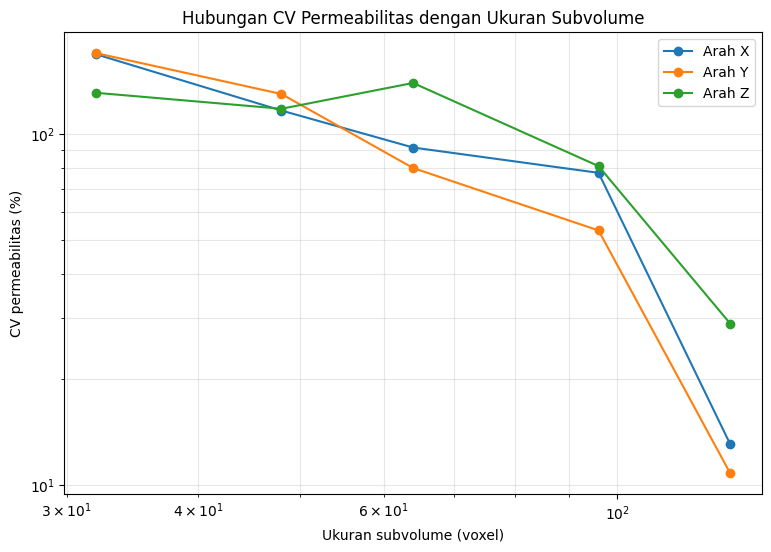

In [16]:
plt.figure(figsize=(9, 6))

for arah in ["X", "Y", "Z"]:

    data = ringkasan_k[
        ringkasan_k["arah"] == arah
    ].copy()

    plt.plot(
        data["ukuran_voxel"],
        data["CV_persen"],
        marker="o",
        label=f"Arah {arah}"
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Ukuran subvolume (voxel)")
plt.ylabel("CV permeabilitas (%)")
plt.title("Hubungan CV Permeabilitas dengan Ukuran Subvolume")
plt.grid(True, which="both", alpha=0.3)
plt.legend()

plt.show()

In [17]:
variabel_penting = [
    "subvolume_df",
    "ringkasan_por",
    "ssa_df",
    "ringkasan_ssa",
    "rekap_lbm",
    "ringkasan_k",
    "df_anisotropi",
    "df_estimasi",
    "df_slope"
]

for nama in variabel_penting:
    print(
        nama,
        ":",
        "TERSEDIA" if nama in globals() else "BELUM ADA"
    )

subvolume_df : BELUM ADA
ringkasan_por : BELUM ADA
ssa_df : BELUM ADA
ringkasan_ssa : BELUM ADA
rekap_lbm : TERSEDIA
ringkasan_k : TERSEDIA
df_anisotropi : TERSEDIA
df_estimasi : TERSEDIA
df_slope : TERSEDIA


In [18]:
import os

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"

print("Daftar file dalam folder proyek:\n")

for file in os.listdir(folder_backup):
    print(file)

Daftar file dalam folder proyek:

checkpoint_lbm_kirby.csv


In [19]:
import os

file_raw = "/content/Kirby_2d25um_binary_256.raw"

print("File RAW tersedia:", os.path.exists(file_raw))
print("Variabel volume tersedia:", "volume" in globals())
print("Variabel NumPy tersedia:", "np" in globals())

File RAW tersedia: False
Variabel volume tersedia: False
Variabel NumPy tersedia: True


In [21]:
from google.colab import files

uploaded = files.upload()

print("\nFile yang berhasil diunggah:")
for nama in uploaded.keys():
    print(nama)

Saving ringkasan_porositas_kirby (1).csv to ringkasan_porositas_kirby (1).csv
Saving ringkasan_ssa_kirby (1).csv to ringkasan_ssa_kirby (1).csv
Saving data_ssa_subvolume_kirby.csv to data_ssa_subvolume_kirby.csv

File yang berhasil diunggah:
ringkasan_porositas_kirby (1).csv
ringkasan_ssa_kirby (1).csv
data_ssa_subvolume_kirby.csv


In [23]:
import pandas as pd

ringkasan_por = pd.read_csv(
    "/content/ringkasan_porositas_kirby (1).csv"
)

ssa_df = pd.read_csv(
    "/content/data_ssa_subvolume_kirby.csv"
)

ringkasan_ssa = pd.read_csv(
    "/content/ringkasan_ssa_kirby (1).csv"
)

print("Ringkasan porositas:", ringkasan_por.shape)
print("Data SSA:", ssa_df.shape)
print("Ringkasan SSA:", ringkasan_ssa.shape)

display(ringkasan_por)
display(ringkasan_ssa)

Ringkasan porositas: (5, 10)
Data SSA: (150, 10)
Ringkasan SSA: (5, 10)


,ukuran_voxel,jumlah_sampel,rata_rata,standar_deviasi,minimum,maksimum,ukuran_fisik_um,CV,CV_persen,status_REV
0,32,30,0.197401,0.093428,0.050476,0.414337,72.0,0.473292,47.329238,Belum memenuhi ambang CV
1,48,30,0.208348,0.075930,0.074888,0.360225,108.0,0.364440,36.444012,Belum memenuhi ambang CV
2,64,30,0.205668,0.054270,0.102333,0.357357,144.0,0.263874,26.387400,Belum memenuhi ambang CV
3,96,30,0.203262,0.022421,0.158272,0.248179,216.0,0.110308,11.030833,Belum memenuhi ambang CV
4,128,30,0.215314,0.010909,0.193624,0.240153,288.0,0.050666,5.066559,Belum memenuhi ambang CV


,ukuran_voxel,jumlah_sampel,rata_rata,standar_deviasi,minimum,maksimum,ukuran_fisik_um,CV,CV_persen,status_REV
0,32,30,0.030453,0.009441,0.010263,0.043023,72.0,0.310003,31.000283,Belum memenuhi ambang CV
1,48,30,0.030711,0.007232,0.013565,0.048850,108.0,0.235494,23.549421,Belum memenuhi ambang CV
2,64,30,0.031618,0.005088,0.022248,0.042963,144.0,0.160911,16.091084,Belum memenuhi ambang CV
3,96,30,0.031110,0.002428,0.026936,0.037140,216.0,0.078045,7.804538,Belum memenuhi ambang CV
4,128,30,0.032093,0.001506,0.029482,0.035507,288.0,0.046940,4.693961,Memenuhi ambang CV


In [24]:
import pandas as pd
import os

folder_backup = "/content/drive/MyDrive/Proyek_Akhir_Kirby"
os.makedirs(folder_backup, exist_ok=True)

file_excel = os.path.join(
    folder_backup,
    "Hasil_Analisis_REV_Anisotropi_Kirby.xlsx"
)

daftar_sheet = {
    "Ringkasan_Porositas": ringkasan_por,
    "Data_SSA": ssa_df,
    "Ringkasan_SSA": ringkasan_ssa,
    "Data_LBM": rekap_lbm,
    "Statistik_Permeabilitas": ringkasan_k,
    "Analisis_Anisotropi": df_anisotropi,
    "Estimasi_REV": df_estimasi,
    "Scaling_Law": df_slope
}

with pd.ExcelWriter(file_excel, engine="openpyxl") as writer:
    for nama_sheet, data in daftar_sheet.items():
        data.to_excel(
            writer,
            sheet_name=nama_sheet,
            index=False
        )

print("Workbook berhasil dibuat.")
print("Lokasi:", file_excel)
print("Jumlah sheet:", len(daftar_sheet))
print("Ukuran file:", round(os.path.getsize(file_excel) / 1024, 2), "KB")

Workbook berhasil dibuat.
Lokasi: /content/drive/MyDrive/Proyek_Akhir_Kirby/Hasil_Analisis_REV_Anisotropi_Kirby.xlsx
Jumlah sheet: 8
Ukuran file: 33.66 KB


In [25]:
# Pemeriksaan kesiapan pemecah LBM

fungsi_diperlukan = [
    "jalankan",
    "sifat_aliran",
    "pori_tembus"
]

for nama in fungsi_diperlukan:
    tersedia = nama in globals()
    print(f"{nama}: {'TERSEDIA' if tersedia else 'BELUM TERSEDIA'}")

print("\nPemeriksaan parameter:")
print("TAU:", "TERSEDIA" if "TAU" in globals() else "BELUM ADA")
print("DX_UM:", "TERSEDIA" if "DX_UM" in globals() else "BELUM ADA")

jalankan: BELUM TERSEDIA
sifat_aliran: BELUM TERSEDIA
pori_tembus: BELUM TERSEDIA

Pemeriksaan parameter:
TAU: BELUM ADA
DX_UM: TERSEDIA


In [27]:
print("jalankan:", "TERSEDIA" if "jalankan" in globals() else "BELUM")
print("_langkah:", "TERSEDIA" if "_langkah" in globals() else "BELUM")
print("D3Q19:", "TERSEDIA" if "kisi" in globals() else "BELUM")
print("Numba:", ADA_NUMBA if "ADA_NUMBA" in globals() else "BELUM")

jalankan: BELUM
_langkah: BELUM
D3Q19: BELUM
Numba: BELUM


In [28]:
print("jalankan:", "TERSEDIA" if "jalankan" in globals() else "BELUM")
print("_langkah:", "TERSEDIA" if "_langkah" in globals() else "BELUM")
print("D3Q19:", "TERSEDIA" if "kisi" in globals() else "BELUM")
print("Numba:", ADA_NUMBA if "ADA_NUMBA" in globals() else "BELUM")

jalankan: BELUM
_langkah: BELUM
D3Q19: BELUM
Numba: BELUM


In [29]:
print("=== AUDIT FUNGSI LBM ===")

fungsi = [
    "np",
    "nb",
    "ADA_NUMBA",
    "kisi",
    "_langkah",
    "jalankan",
    "label_periodik",
    "pori_tembus",
    "sifat_aliran",
    "TAU",
    "G",
    "DX_UM"
]

for nama in fungsi:
    print(
        nama,
        ":",
        "TERSEDIA" if nama in globals() else "BELUM TERSEDIA"
    )

=== AUDIT FUNGSI LBM ===
np : TERSEDIA
nb : BELUM TERSEDIA
ADA_NUMBA : BELUM TERSEDIA
kisi : BELUM TERSEDIA
_langkah : BELUM TERSEDIA
jalankan : BELUM TERSEDIA
label_periodik : BELUM TERSEDIA
pori_tembus : BELUM TERSEDIA
sifat_aliran : BELUM TERSEDIA
TAU : BELUM TERSEDIA
G : BELUM TERSEDIA
DX_UM : TERSEDIA


In [30]:
fungsi = [
    "ADA_NUMBA",
    "kisi",
    "_langkah",
    "jalankan",
    "label_periodik",
    "pori_tembus",
    "sifat_aliran",
    "TAU",
    "G"
]

for nama in fungsi:
    print(nama, ":", "TERSEDIA" if nama in globals() else "BELUM")

ADA_NUMBA : BELUM
kisi : BELUM
_langkah : BELUM
jalankan : BELUM
label_periodik : BELUM
pori_tembus : BELUM
sifat_aliran : BELUM
TAU : BELUM
G : BELUM


In [36]:
# Koreksi konstanta konversi Darcy
DARCY = 0.987e-15

# Audit kesiapan fungsi dan parameter
fungsi = [
    "np", "nb", "ADA_NUMBA", "kisi",
    "_langkah", "jalankan", "label_periodik",
    "pori_tembus", "sifat_aliran",
    "TAU", "G", "DX_UM", "DARCY"
]

print("=== AUDIT KESIAPAN LBM ===")
for nama in fungsi:
    print(nama, ":", "TERSEDIA" if nama in globals() else "BELUM")

print("\nDARCY untuk konversi mD:", DARCY)

=== AUDIT KESIAPAN LBM ===
np : TERSEDIA
nb : TERSEDIA
ADA_NUMBA : TERSEDIA
kisi : TERSEDIA
_langkah : TERSEDIA
jalankan : TERSEDIA
label_periodik : TERSEDIA
pori_tembus : TERSEDIA
sifat_aliran : TERSEDIA
TAU : TERSEDIA
G : TERSEDIA
DX_UM : TERSEDIA
DARCY : TERSEDIA

DARCY untuk konversi mD: 9.87e-16


In [39]:
print("=== REKAP CHECKPOINT LBM ===")

print("\nJumlah simulasi per ukuran:")
display(
    rekap_lbm.groupby("ukuran_voxel")
    .size()
    .reset_index(name="jumlah_simulasi")
)

print("\nJumlah simulasi per ukuran dan arah:")
display(
    rekap_lbm.groupby(["ukuran_voxel", "arah"])
    .size()
    .unstack(fill_value=0)
)

print("\nDistribusi status simulasi:")
display(
    rekap_lbm["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="jumlah")
)

print("\nJumlah hasil konvergen dan stabil:")
print("Konvergen:", rekap_lbm["konvergen"].sum())
print("Stabil:", rekap_lbm["stabil"].sum())
print("Permeabilitas tersedia:", rekap_lbm["k_mD"].notna().sum())

=== REKAP CHECKPOINT LBM ===

Jumlah simulasi per ukuran:


,ukuran_voxel,jumlah_simulasi
0,32,18
1,48,18
2,64,18
3,96,18
4,128,18



Jumlah simulasi per ukuran dan arah:


arah,X,Y,Z
ukuran_voxel,,,
32,6,6,6
48,6,6,6
64,6,6,6
96,6,6,6
128,6,6,6



Distribusi status simulasi:


,status,jumlah
0,Variasi irisan tinggi,46
1,Lolos pemeriksaan,34
2,Non-percolating,10



Jumlah hasil konvergen dan stabil:
Konvergen: 80
Stabil: 80
Permeabilitas tersedia: 80


In [38]:
print("Jumlah baris:", len(rekap_lbm))

print("\nNama seluruh kolom:")
print(rekap_lbm.columns.tolist())

print("\nContoh 5 baris pertama:")
display(rekap_lbm.head())

Jumlah baris: 90

Nama seluruh kolom:
['ukuran_voxel', 'ukuran_fisik_um', 'nomor_sampel', 'z_awal', 'y_awal', 'x_awal', 'porositas', 'arah', 'jumlah_pori_tembus', 'fraksi_pori_tembus', 'k_mD', 'langkah', 'Mach', 'konvergen', 'stabil', 'variasi_irisan', 'tortuositas', 'status', 'waktu_detik']

Contoh 5 baris pertama:


,ukuran_voxel,ukuran_fisik_um,nomor_sampel,z_awal,y_awal,x_awal,porositas,arah,jumlah_pori_tembus,fraksi_pori_tembus,k_mD,langkah,Mach,konvergen,stabil,variasi_irisan,tortuositas,status,waktu_detik
0,32,72.0,1,94,206,121,0.289886,Z,9364,0.285767,47.369556,6300.0,0.000018,True,True,0.040189,1.681647,Variasi irisan tinggi,21.833869
1,32,72.0,1,94,206,121,0.289886,Y,9364,0.285767,74.439633,5900.0,0.000049,True,True,0.008722,1.561185,Variasi irisan tinggi,19.125685
2,32,72.0,1,94,206,121,0.289886,X,9364,0.285767,2781.310834,1700.0,0.000240,True,True,0.000408,1.053567,Lolos pemeriksaan,6.309298
3,32,72.0,2,42,127,211,0.069336,Z,2013,0.061432,21.645607,4000.0,0.000027,True,True,0.099129,1.479043,Variasi irisan tinggi,2.550674
4,32,72.0,2,42,127,211,0.069336,Y,2013,0.061432,87.544415,1000.0,0.000039,True,True,0.006004,1.222602,Variasi irisan tinggi,0.642339


In [40]:
# Memilih hasil simulasi yang valid untuk analisis utama
lbm_valid = rekap_lbm[
    (rekap_lbm["konvergen"] == True) &
    (rekap_lbm["stabil"] == True) &
    (rekap_lbm["k_mD"].notna()) &
    (np.isfinite(rekap_lbm["k_mD"])) &
    (rekap_lbm["k_mD"] > 0)
].copy()

# Menghitung statistik per ukuran dan arah
ringkasan_k = (
    lbm_valid
    .groupby(["ukuran_voxel", "ukuran_fisik_um", "arah"])
    ["k_mD"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .reset_index()
)

# Menghitung coefficient of variation
ringkasan_k["CV"] = (
    ringkasan_k["standar_deviasi"] /
    ringkasan_k["rata_rata"]
)

ringkasan_k["CV_persen"] = ringkasan_k["CV"] * 100

print("Jumlah data valid:", len(lbm_valid))
print("Jumlah kelompok statistik:", len(ringkasan_k))

display(ringkasan_k.round(4))

Jumlah data valid: 80
Jumlah kelompok statistik: 15


,ukuran_voxel,ukuran_fisik_um,arah,jumlah,rata_rata,standar_deviasi,minimum,maksimum,CV,CV_persen
0,32,72.0,X,5,697.7595,1181.6488,0.0914,2781.3108,1.6935,169.3490
1,32,72.0,Y,5,408.7829,697.4895,5.0100,1647.9805,1.7063,170.6259
2,32,72.0,Z,4,63.8351,83.9105,0.0184,186.3067,1.3145,131.4490
3,48,108.0,X,5,864.1120,1010.7260,0.0235,2004.4774,1.1697,116.9670
4,48,108.0,Y,4,679.2917,885.8420,0.0071,1929.5875,1.3041,130.4067
5,48,108.0,Z,3,159.3082,188.5703,0.0121,367.5149,1.1837,118.3682
6,64,144.0,X,6,181.6296,166.6222,3.1384,492.0400,0.9174,91.7373
7,64,144.0,Y,6,182.7450,146.5164,43.4135,457.9431,0.8018,80.1753
8,64,144.0,Z,6,207.3311,290.7406,12.7761,769.7871,1.4023,140.2301
9,96,216.0,X,6,274.9915,213.6036,77.9631,618.9356,0.7768,77.6764


In [41]:
# Memeriksa seluruh simulasi pada ukuran 128³
data_128 = rekap_lbm[
    rekap_lbm["ukuran_voxel"] == 128
].copy()

kolom = [
    "nomor_sampel",
    "arah",
    "k_mD",
    "konvergen",
    "stabil",
    "status",
    "jumlah_pori_tembus",
    "fraksi_pori_tembus"
]

display(
    data_128[kolom]
    .sort_values(["nomor_sampel", "arah"])
    .reset_index(drop=True)
)

,nomor_sampel,arah,k_mD,konvergen,stabil,status,jumlah_pori_tembus,fraksi_pori_tembus
0,1,X,481.632531,True,True,Lolos pemeriksaan,430683,0.205366
1,1,Y,407.357913,True,True,Lolos pemeriksaan,430683,0.205366
2,1,Z,523.518672,True,True,Lolos pemeriksaan,430683,0.205366
3,2,X,561.597429,True,True,Lolos pemeriksaan,496390,0.236697
4,2,Y,517.167805,True,True,Lolos pemeriksaan,496390,0.236697
5,2,Z,761.029665,True,True,Lolos pemeriksaan,496390,0.236697
6,3,X,480.551253,True,True,Lolos pemeriksaan,440896,0.210236
7,3,Y,422.846059,True,True,Lolos pemeriksaan,440896,0.210236
8,3,Z,547.369563,True,True,Lolos pemeriksaan,440896,0.210236
9,4,X,425.666796,True,True,Lolos pemeriksaan,457483,0.218145


In [42]:
# Pastikan seluruh data berasal dari checkpoint terbaru
lbm_valid = rekap_lbm[
    (rekap_lbm["konvergen"] == True) &
    (rekap_lbm["stabil"] == True) &
    (rekap_lbm["k_mD"].notna()) &
    (np.isfinite(rekap_lbm["k_mD"])) &
    (rekap_lbm["k_mD"] > 0)
].copy()

# Hitung ulang statistik
ringkasan_k = (
    lbm_valid
    .groupby(["ukuran_voxel", "ukuran_fisik_um", "arah"])
    ["k_mD"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .reset_index()
)

ringkasan_k["CV"] = (
    ringkasan_k["standar_deviasi"] /
    ringkasan_k["rata_rata"]
)

ringkasan_k["CV_persen"] = ringkasan_k["CV"] * 100

print("Total data valid:", len(lbm_valid))
print("\nJumlah data per ukuran dan arah:")
display(
    lbm_valid.groupby(["ukuran_voxel", "arah"])
    .size()
    .unstack()
)

print("\nStatistik permeabilitas terbaru:")
display(ringkasan_k.round(4))

Total data valid: 80

Jumlah data per ukuran dan arah:


arah,X,Y,Z
ukuran_voxel,,,
32,5,5,4
48,5,4,3
64,6,6,6
96,6,6,6
128,6,6,6



Statistik permeabilitas terbaru:


,ukuran_voxel,ukuran_fisik_um,arah,jumlah,rata_rata,standar_deviasi,minimum,maksimum,CV,CV_persen
0,32,72.0,X,5,697.7595,1181.6488,0.0914,2781.3108,1.6935,169.3490
1,32,72.0,Y,5,408.7829,697.4895,5.0100,1647.9805,1.7063,170.6259
2,32,72.0,Z,4,63.8351,83.9105,0.0184,186.3067,1.3145,131.4490
3,48,108.0,X,5,864.1120,1010.7260,0.0235,2004.4774,1.1697,116.9670
4,48,108.0,Y,4,679.2917,885.8420,0.0071,1929.5875,1.3041,130.4067
5,48,108.0,Z,3,159.3082,188.5703,0.0121,367.5149,1.1837,118.3682
6,64,144.0,X,6,181.6296,166.6222,3.1384,492.0400,0.9174,91.7373
7,64,144.0,Y,6,182.7450,146.5164,43.4135,457.9431,0.8018,80.1753
8,64,144.0,Z,6,207.3311,290.7406,12.7761,769.7871,1.4023,140.2301
9,96,216.0,X,6,274.9915,213.6036,77.9631,618.9356,0.7768,77.6764


In [43]:
# Ambil seluruh data ukuran 128
audit_128 = rekap_lbm[
    rekap_lbm["ukuran_voxel"] == 128
].copy()

# Hitung ulang dari checkpoint secara langsung
hasil_audit_128 = (
    audit_128
    .groupby("arah")["k_mD"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .reset_index()
)

hasil_audit_128["CV_persen"] = (
    hasil_audit_128["standar_deviasi"] /
    hasil_audit_128["rata_rata"] * 100
)

print("Jumlah baris checkpoint:", len(audit_128))
print("\nJumlah nilai permeabilitas per arah:")
print(audit_128.groupby("arah")["k_mD"].count())

print("\nHasil statistik hitung ulang:")
display(hasil_audit_128.round(4))

Jumlah baris checkpoint: 18

Jumlah nilai permeabilitas per arah:
arah
X    6
Y    6
Z    6
Name: k_mD, dtype: int64

Hasil statistik hitung ulang:


,arah,jumlah,rata_rata,standar_deviasi,minimum,maksimum,CV_persen
0,X,6,482.2510,63.0060,400.8289,561.5974,13.0650
1,Y,6,475.1955,51.2638,407.3579,534.1885,10.7879
2,Z,6,560.1110,161.5641,322.5080,761.0297,28.8450


In [44]:
# Hitung ulang statistik dari checkpoint terbaru
lbm_valid = rekap_lbm[
    (rekap_lbm["konvergen"] == True) &
    (rekap_lbm["stabil"] == True) &
    (rekap_lbm["k_mD"].notna()) &
    (np.isfinite(rekap_lbm["k_mD"])) &
    (rekap_lbm["k_mD"] > 0)
].copy()

ringkasan_k = (
    lbm_valid
    .groupby(["ukuran_voxel", "ukuran_fisik_um", "arah"])["k_mD"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        standar_deviasi="std",
        CV=lambda x: x.std() / x.mean()
    )
    .reset_index()
)

ringkasan_k["CV_persen"] = ringkasan_k["CV"] * 100

# Analisis anisotropi per ukuran
hasil_anisotropi = []

for ukuran in sorted(ringkasan_k["ukuran_voxel"].unique()):

    data = ringkasan_k[
        ringkasan_k["ukuran_voxel"] == ukuran
    ]

    tertinggi = data.loc[data["rata_rata"].idxmax()]
    terendah = data.loc[data["rata_rata"].idxmin()]

    kmax = tertinggi["rata_rata"]
    kmin = terendah["rata_rata"]
    sigma = tertinggi["standar_deviasi"]

    A = (kmax - kmin) / sigma
    rasio = kmax / kmin

    hasil_anisotropi.append({
        "ukuran_voxel": ukuran,
        "ukuran_fisik_um": tertinggi["ukuran_fisik_um"],
        "arah_kmax": tertinggi["arah"],
        "arah_kmin": terendah["arah"],
        "kmax_mD": kmax,
        "kmin_mD": kmin,
        "sigma_kmax": sigma,
        "indeks_A": A,
        "rasio_kmax_kmin": rasio,
        "interpretasi": (
            "Belum terbedakan dari variasi posisi"
            if A < 2 else
            "Indikasi anisotropi"
        )
    })

df_anisotropi = pd.DataFrame(hasil_anisotropi)

print("=== HASIL ANALISIS ANISOTROPI ===")
display(df_anisotropi.round(4))

=== HASIL ANALISIS ANISOTROPI ===


,ukuran_voxel,ukuran_fisik_um,arah_kmax,arah_kmin,kmax_mD,kmin_mD,sigma_kmax,indeks_A,rasio_kmax_kmin,interpretasi
0,32,72.0,X,Z,697.7595,63.8351,1181.6488,0.5365,10.9307,Belum terbedakan dari variasi posisi
1,48,108.0,X,Z,864.1120,159.3082,1010.7260,0.6973,5.4242,Belum terbedakan dari variasi posisi
2,64,144.0,Z,X,207.3311,181.6296,290.7406,0.0884,1.1415,Belum terbedakan dari variasi posisi
3,96,216.0,Z,X,361.0064,274.9915,293.0642,0.2935,1.3128,Belum terbedakan dari variasi posisi
4,128,288.0,Z,Y,638.5978,461.4491,120.5410,1.4696,1.3839,Belum terbedakan dari variasi posisi


In [45]:
# Estimasi ukuran REV berdasarkan CV ukuran terbesar
hasil_estimasi = []

for arah in ["X", "Y", "Z"]:

    data = ringkasan_k[
        ringkasan_k["arah"] == arah
    ].sort_values("ukuran_voxel")

    cv_128 = data.loc[
        data["ukuran_voxel"] == 128, "CV"
    ].iloc[0]

    # Estimasi ukuran sisi REV dalam voxel
    l_rev_voxel = 128 * (cv_128 / 0.05)**(2/3)

    # Konversi ke mikrometer
    l_rev_um = l_rev_voxel * DX_UM

    # Estimasi memori LBM: 304 byte/node
    memori_gb = (l_rev_voxel**3 * 304) / 1e9

    hasil_estimasi.append({
        "arah": arah,
        "CV_128_persen": cv_128 * 100,
        "estimasi_REV_voxel": l_rev_voxel,
        "estimasi_REV_um": l_rev_um,
        "estimasi_memori_GB": memori_gb
    })

df_estimasi = pd.DataFrame(hasil_estimasi)

print("=== ESTIMASI UKURAN REV PERMEABILITAS ===")
display(df_estimasi.round(2))

=== ESTIMASI UKURAN REV PERMEABILITAS ===


,arah,CV_128_persen,estimasi_REV_voxel,estimasi_REV_um,estimasi_memori_GB
0,X,11.48,222.81,501.33,3.36
1,Y,11.80,226.83,510.37,3.55
2,Z,18.88,310.34,698.26,9.09


In [46]:
from scipy.stats import linregress

hasil_scaling = []

for arah in ["X", "Y", "Z"]:

    data = ringkasan_k[
        ringkasan_k["arah"] == arah
    ].sort_values("ukuran_voxel")

    x = np.log(data["ukuran_voxel"].values)
    y = np.log(data["CV"].values)

    regresi = linregress(x, y)

    slope = regresi.slope
    r2 = regresi.rvalue ** 2

    hasil_scaling.append({
        "arah": arah,
        "jumlah_titik": len(data),
        "slope": slope,
        "R2": r2,
        "selisih_dari_minus_1_5": abs(slope - (-1.5)),
        "interpretasi": (
            "Sesuai rentang teoritis"
            if -1.8 <= slope <= -1.2
            else "Di luar rentang teoritis"
        )
    })

df_slope = pd.DataFrame(hasil_scaling)

print("=== ANALISIS SCALING LAW ===")
display(df_slope.round(4))

=== ANALISIS SCALING LAW ===


,arah,jumlah_titik,slope,R2,selisih_dari_minus_1_5,interpretasi
0,X,5,-1.6344,0.7326,0.1344,Sesuai rentang teoritis
1,Y,5,-1.7694,0.8551,0.2694,Sesuai rentang teoritis
2,Z,5,-1.2051,0.6249,0.2949,Sesuai rentang teoritis


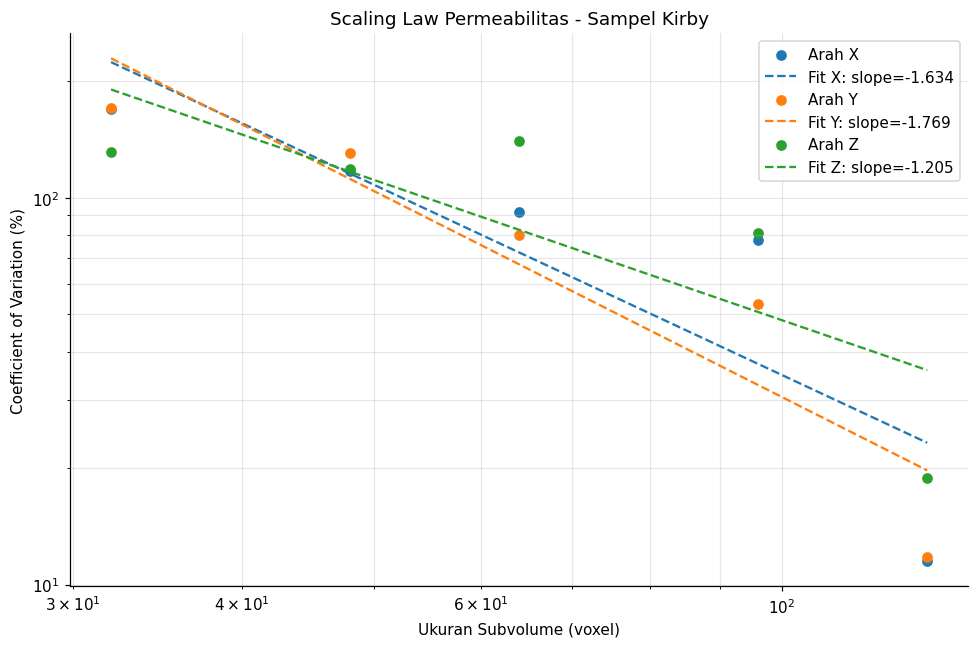

In [47]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

for arah in ["X", "Y", "Z"]:

    data = ringkasan_k[
        ringkasan_k["arah"] == arah
    ].sort_values("ukuran_voxel")

    x = data["ukuran_voxel"].values
    y = data["CV"].values * 100

    # Regresi log-log
    slope = df_slope.loc[
        df_slope["arah"] == arah, "slope"
    ].iloc[0]

    intercept = np.polyfit(np.log(x), np.log(y), 1)[1]

    x_fit = np.linspace(min(x), max(x), 100)
    y_fit = np.exp(intercept) * x_fit**slope

    plt.scatter(x, y, label=f"Arah {arah}")
    plt.plot(
        x_fit,
        y_fit,
        linestyle="--",
        label=f"Fit {arah}: slope={slope:.3f}"
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Ukuran Subvolume (voxel)")
plt.ylabel("Coefficient of Variation (%)")
plt.title("Scaling Law Permeabilitas - Sampel Kirby")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
# Nilai referensi dari CSV sampel Kirby
referensi = {
    "X": 636.3142,
    "Y": 621.6607,
    "Z": 594.9657
}

# Statistik simulasi pada ukuran terbesar
simulasi_128 = ringkasan_k[
    ringkasan_k["ukuran_voxel"] == 128
].copy()

hasil_perbandingan = []

for _, baris in simulasi_128.iterrows():

    arah = baris["arah"]
    nilai_simulasi = baris["rata_rata"]
    nilai_referensi = referensi[arah]

    error = abs(
        nilai_simulasi - nilai_referensi
    ) / nilai_referensi * 100

    hasil_perbandingan.append({
        "arah": arah,
        "simulasi_mD": nilai_simulasi,
        "referensi_mD": nilai_referensi,
        "error_persen": error,
        "memenuhi_toleransi_25_persen": error < 25
    })

df_perbandingan = pd.DataFrame(hasil_perbandingan)

print("=== PERBANDINGAN DENGAN REFERENSI KIRBY ===")
display(df_perbandingan.round(4))

=== PERBANDINGAN DENGAN REFERENSI KIRBY ===


,arah,simulasi_mD,referensi_mD,error_persen,memenuhi_toleransi_25_persen
0,X,487.3620,636.3142,23.4086,True
1,Y,461.4491,621.6607,25.7715,False
2,Z,638.5978,594.9657,7.3335,True


In [49]:
# Ambil hasil valid langsung dari checkpoint
data_valid_final = rekap_lbm[
    (rekap_lbm["konvergen"] == True) &
    (rekap_lbm["stabil"] == True) &
    (rekap_lbm["k_mD"].notna()) &
    (np.isfinite(rekap_lbm["k_mD"])) &
    (rekap_lbm["k_mD"] > 0)
].copy()

# Hitung ulang rata-rata per ukuran dan arah
ringkasan_final = (
    data_valid_final
    .groupby(["ukuran_voxel", "arah"])
    .agg(
        jumlah=("k_mD", "count"),
        rata_rata=("k_mD", "mean"),
        standar_deviasi=("k_mD", "std")
    )
    .reset_index()
)

# Ambil ukuran 128
simulasi_final = ringkasan_final[
    ringkasan_final["ukuran_voxel"] == 128
].copy()

referensi = {
    "X": 636.3142,
    "Y": 621.6607,
    "Z": 594.9657
}

simulasi_final["referensi_mD"] = (
    simulasi_final["arah"].map(referensi)
)

simulasi_final["error_persen"] = (
    abs(simulasi_final["rata_rata"] -
        simulasi_final["referensi_mD"]) /
    simulasi_final["referensi_mD"] * 100
)

simulasi_final["memenuhi_25_persen"] = (
    simulasi_final["error_persen"] < 25
)

print("Jumlah data valid:", len(data_valid_final))
print("\nJumlah sampel ukuran 128:")
display(
    simulasi_final[
        ["arah", "jumlah", "rata_rata",
         "referensi_mD", "error_persen",
         "memenuhi_25_persen"]
    ].round(4)
)

Jumlah data valid: 80

Jumlah sampel ukuran 128:


,arah,jumlah,rata_rata,referensi_mD,error_persen,memenuhi_25_persen
12,X,6,482.2510,636.3142,24.2118,True
13,Y,6,475.1955,621.6607,23.5603,True
14,Z,6,560.1110,594.9657,5.8583,True


In [50]:
# Gunakan statistik yang dihitung langsung dari checkpoint
ringkasan_k = ringkasan_final.copy()

# Hitung CV berdasarkan statistik terbaru
ringkasan_k["CV"] = (
    ringkasan_k["standar_deviasi"] /
    ringkasan_k["rata_rata"]
)

ringkasan_k["CV_persen"] = ringkasan_k["CV"] * 100

print("=== STATISTIK PERMEABILITAS FINAL ===")
display(ringkasan_k.round(4))

print("\nPemeriksaan ukuran 128:")
display(
    ringkasan_k[
        ringkasan_k["ukuran_voxel"] == 128
    ].round(4)
)

=== STATISTIK PERMEABILITAS FINAL ===


,ukuran_voxel,arah,jumlah,rata_rata,standar_deviasi,CV,CV_persen
0,32,X,5,697.7595,1181.6488,1.6935,169.3490
1,32,Y,5,408.7829,697.4895,1.7063,170.6259
2,32,Z,4,63.8351,83.9105,1.3145,131.4490
3,48,X,5,864.1120,1010.7260,1.1697,116.9670
4,48,Y,4,679.2917,885.8420,1.3041,130.4067
5,48,Z,3,159.3082,188.5703,1.1837,118.3682
6,64,X,6,181.6296,166.6222,0.9174,91.7373
7,64,Y,6,182.7450,146.5164,0.8018,80.1753
8,64,Z,6,207.3311,290.7406,1.4023,140.2301
9,96,X,6,274.9915,213.6036,0.7768,77.6764



Pemeriksaan ukuran 128:


,ukuran_voxel,arah,jumlah,rata_rata,standar_deviasi,CV,CV_persen
12,128,X,6,482.2510,63.0060,0.1306,13.0650
13,128,Y,6,475.1955,51.2638,0.1079,10.7879
14,128,Z,6,560.1110,161.5641,0.2885,28.8450


In [51]:
hasil_anisotropi = []

for ukuran in sorted(ringkasan_k["ukuran_voxel"].unique()):

    data = ringkasan_k[
        ringkasan_k["ukuran_voxel"] == ukuran
    ]

    tertinggi = data.loc[data["rata_rata"].idxmax()]
    terendah = data.loc[data["rata_rata"].idxmin()]

    kmax = tertinggi["rata_rata"]
    kmin = terendah["rata_rata"]
    sigma = tertinggi["standar_deviasi"]

    A = (kmax - kmin) / sigma
    rasio = kmax / kmin

    hasil_anisotropi.append({
        "ukuran_voxel": ukuran,
        "arah_kmax": tertinggi["arah"],
        "arah_kmin": terendah["arah"],
        "kmax_mD": kmax,
        "kmin_mD": kmin,
        "sigma_kmax": sigma,
        "indeks_A": A,
        "rasio_kmax_kmin": rasio,
        "interpretasi": (
            "Belum terbedakan dari variasi posisi"
            if A < 2 else "Indikasi anisotropi"
        )
    })

df_anisotropi = pd.DataFrame(hasil_anisotropi)

print("=== ANALISIS ANISOTROPI FINAL ===")
display(df_anisotropi.round(4))

=== ANALISIS ANISOTROPI FINAL ===


,ukuran_voxel,arah_kmax,arah_kmin,kmax_mD,kmin_mD,sigma_kmax,indeks_A,rasio_kmax_kmin,interpretasi
0,32,X,Z,697.7595,63.8351,1181.6488,0.5365,10.9307,Belum terbedakan dari variasi posisi
1,48,X,Z,864.1120,159.3082,1010.7260,0.6973,5.4242,Belum terbedakan dari variasi posisi
2,64,Z,X,207.3311,181.6296,290.7406,0.0884,1.1415,Belum terbedakan dari variasi posisi
3,96,Z,X,361.0064,274.9915,293.0642,0.2935,1.3128,Belum terbedakan dari variasi posisi
4,128,Z,Y,560.1110,475.1955,161.5641,0.5256,1.1787,Belum terbedakan dari variasi posisi


In [52]:
hasil_estimasi = []

for arah in ["X", "Y", "Z"]:

    data = ringkasan_k[
        ringkasan_k["arah"] == arah
    ]

    cv_128 = data.loc[
        data["ukuran_voxel"] == 128,
        "CV"
    ].iloc[0]

    l_rev = 128 * (cv_128 / 0.05)**(2/3)

    l_rev_um = l_rev * DX_UM

    memori_gb = (l_rev**3 * 304) / 1e9

    hasil_estimasi.append({
        "arah": arah,
        "CV_128_persen": cv_128 * 100,
        "estimasi_REV_voxel": l_rev,
        "estimasi_REV_um": l_rev_um,
        "estimasi_memori_GB": memori_gb
    })

df_estimasi = pd.DataFrame(hasil_estimasi)

print("=== ESTIMASI REV FINAL ===")
display(df_estimasi.round(2))

=== ESTIMASI REV FINAL ===


,arah,CV_128_persen,estimasi_REV_voxel,estimasi_REV_um,estimasi_memori_GB
0,X,13.06,242.83,546.37,4.35
1,Y,10.79,213.73,480.88,2.97
2,Z,28.85,411.73,926.39,21.22


In [53]:
from scipy.stats import linregress

hasil_scaling_final = []

for arah in ["X", "Y", "Z"]:

    data = ringkasan_k[
        ringkasan_k["arah"] == arah
    ].sort_values("ukuran_voxel")

    x = np.log(data["ukuran_voxel"].values)
    y = np.log(data["CV"].values)

    regresi = linregress(x, y)

    slope = regresi.slope
    r2 = regresi.rvalue ** 2

    hasil_scaling_final.append({
        "arah": arah,
        "jumlah_titik": len(data),
        "slope": slope,
        "R2": r2,
        "sesuai_teori": -1.8 <= slope <= -1.2
    })

df_slope = pd.DataFrame(hasil_scaling_final)

print("=== SCALING LAW FINAL ===")
display(df_slope.round(4))

=== SCALING LAW FINAL ===


,arah,jumlah_titik,slope,R2,sesuai_teori
0,X,5,-1.5627,0.7463,True
1,Y,5,-1.8190,0.8445,False
2,Z,5,-0.9695,0.6600,False


In [55]:
# AUDIT SELURUH HASIL PROYEK KIRBY

daftar_variabel = [
    "rekap_lbm",
    "lbm_valid",
    "ringkasan_k",
    "ringkasan_final",
    "df_anisotropi",
    "df_estimasi",
    "df_slope",
    "ringkasan_por",
    "ringkasan_ssa",
    "ssa_df",
    "subvolume_df",
    "overlap_df",
    "df_perbandingan"
]

print("=== AUDIT HASIL PROYEK REV KIRBY ===")

for nama in daftar_variabel:
    if nama in globals():
        obj = globals()[nama]

        if hasattr(obj, "shape"):
            print(f"{nama}: TERSEDIA | ukuran {obj.shape}")
        else:
            print(f"{nama}: TERSEDIA")
    else:
        print(f"{nama}: BELUM TERSEDIA")

=== AUDIT HASIL PROYEK REV KIRBY ===
rekap_lbm: TERSEDIA | ukuran (90, 19)
lbm_valid: TERSEDIA | ukuran (80, 19)
ringkasan_k: TERSEDIA | ukuran (15, 7)
ringkasan_final: TERSEDIA | ukuran (15, 5)
df_anisotropi: TERSEDIA | ukuran (5, 9)
df_estimasi: TERSEDIA | ukuran (3, 5)
df_slope: TERSEDIA | ukuran (3, 5)
ringkasan_por: TERSEDIA | ukuran (5, 10)
ringkasan_ssa: TERSEDIA | ukuran (5, 10)
ssa_df: TERSEDIA | ukuran (150, 10)
subvolume_df: BELUM TERSEDIA
overlap_df: BELUM TERSEDIA
df_perbandingan: TERSEDIA | ukuran (3, 5)


In [56]:
import os

folder = "/content/drive/MyDrive/Proyek_Akhir_Kirby"

file_cadangan = [
    "data_subvolume_kirby.csv",
    "diagnostik_overlap_kirby.csv",
    "ringkasan_porositas_kirby.csv",
    "ringkasan_ssa_kirby.csv",
    "data_ssa_subvolume_kirby.csv",
    "checkpoint_lbm_kirby.csv"
]

print("=== PEMERIKSAAN FILE CADANGAN ===")

for nama in file_cadangan:
    path = os.path.join(folder, nama)

    if os.path.exists(path):
        ukuran = os.path.getsize(path) / 1024
        print(f"ADA  | {nama} | {ukuran:.2f} KB")
    else:
        print(f"TIDAK ADA | {nama}")

=== PEMERIKSAAN FILE CADANGAN ===
TIDAK ADA | data_subvolume_kirby.csv
TIDAK ADA | diagnostik_overlap_kirby.csv
TIDAK ADA | ringkasan_porositas_kirby.csv
TIDAK ADA | ringkasan_ssa_kirby.csv
TIDAK ADA | data_ssa_subvolume_kirby.csv
ADA  | checkpoint_lbm_kirby.csv | 16.31 KB


In [57]:
print("=== AUDIT DATA SUMBER ===")

variabel = [
    "volume",
    "np",
    "UKURAN_SISI",
    "JUMLAH_SUBVOLUME",
    "RANDOM_SEED",
    "DX_UM",
    "ringkasan_por",
    "ringkasan_ssa",
    "ssa_df"
]

for nama in variabel:
    if nama in globals():
        obj = globals()[nama]

        if hasattr(obj, "shape"):
            print(f"{nama}: TERSEDIA | shape={obj.shape}")
        else:
            print(f"{nama}: TERSEDIA | nilai={obj}")
    else:
        print(f"{nama}: BELUM TERSEDIA")

=== AUDIT DATA SUMBER ===
volume: BELUM TERSEDIA
np: TERSEDIA | shape=<function shape at 0x7fb8aa7b0c20>
UKURAN_SISI: TERSEDIA | nilai=[32, 48, 64, 96, 128]
JUMLAH_SUBVOLUME: BELUM TERSEDIA
RANDOM_SEED: BELUM TERSEDIA
DX_UM: TERSEDIA | nilai=2.25
ringkasan_por: TERSEDIA | shape=(5, 10)
ringkasan_ssa: TERSEDIA | shape=(5, 10)
ssa_df: TERSEDIA | shape=(150, 10)


In [58]:
import os
import pandas as pd

folder = "/content/drive/MyDrive/Proyek_Akhir_Kirby"
os.makedirs(folder, exist_ok=True)

# Susun perbandingan referensi dari statistik final
referensi = {
    "X": 636.3142,
    "Y": 621.6607,
    "Z": 594.9657
}

perbandingan_final = ringkasan_k[
    ringkasan_k["ukuran_voxel"] == 128
].copy()

perbandingan_final["referensi_mD"] = (
    perbandingan_final["arah"].map(referensi)
)

perbandingan_final["error_persen"] = (
    abs(perbandingan_final["rata_rata"] -
        perbandingan_final["referensi_mD"]) /
    perbandingan_final["referensi_mD"] * 100
)

perbandingan_final["memenuhi_25_persen"] = (
    perbandingan_final["error_persen"] < 25
)

# Simpan seluruh hasil ke workbook
file_excel = os.path.join(
    folder,
    "Hasil_Final_REV_Anisotropi_Kirby.xlsx"
)

with pd.ExcelWriter(file_excel, engine="openpyxl") as writer:

    rekap_lbm.to_excel(
        writer, sheet_name="Data_LBM_90", index=False
    )

    lbm_valid.to_excel(
        writer, sheet_name="Data_LBM_Valid", index=False
    )

    ringkasan_por.to_excel(
        writer, sheet_name="Ringkasan_Porositas", index=False
    )

    ringkasan_ssa.to_excel(
        writer, sheet_name="Ringkasan_SSA", index=False
    )

    ssa_df.to_excel(
        writer, sheet_name="Data_SSA_150", index=False
    )

    ringkasan_k.to_excel(
        writer, sheet_name="Statistik_Permeabilitas", index=False
    )

    df_anisotropi.to_excel(
        writer, sheet_name="Anisotropi_Final", index=False
    )

    df_estimasi.to_excel(
        writer, sheet_name="Estimasi_REV_Final", index=False
    )

    df_slope.to_excel(
        writer, sheet_name="Scaling_Law_Final", index=False
    )

    perbandingan_final.to_excel(
        writer, sheet_name="Validasi_Referensi", index=False
    )

print("WORKBOOK BERHASIL DISIMPAN")
print(file_excel)
print("Ukuran file:", round(os.path.getsize(file_excel)/1024, 2), "KB")

WORKBOOK BERHASIL DISIMPAN
/content/drive/MyDrive/Proyek_Akhir_Kirby/Hasil_Final_REV_Anisotropi_Kirby.xlsx
Ukuran file: 45.07 KB


In [59]:
import pandas as pd
import os

file_excel = (
    "/content/drive/MyDrive/Proyek_Akhir_Kirby/"
    "Hasil_Final_REV_Anisotropi_Kirby.xlsx"
)

excel = pd.ExcelFile(file_excel)

print("=== VERIFIKASI WORKBOOK ===")
print("Jumlah sheet:", len(excel.sheet_names))

for sheet in excel.sheet_names:
    df = pd.read_excel(file_excel, sheet_name=sheet)
    print(f"{sheet}: {df.shape[0]} baris, {df.shape[1]} kolom")

=== VERIFIKASI WORKBOOK ===
Jumlah sheet: 10
Data_LBM_90: 90 baris, 19 kolom
Data_LBM_Valid: 80 baris, 19 kolom
Ringkasan_Porositas: 5 baris, 10 kolom
Ringkasan_SSA: 5 baris, 10 kolom
Data_SSA_150: 150 baris, 10 kolom
Statistik_Permeabilitas: 15 baris, 7 kolom
Anisotropi_Final: 5 baris, 9 kolom
Estimasi_REV_Final: 3 baris, 5 kolom
Scaling_Law_Final: 3 baris, 5 kolom
Validasi_Referensi: 3 baris, 10 kolom
